# LSST Y1: baryonic feedback models in the 3×2pt data vector

Baryonic feedback, the heating and expulsion of gas by active galactic nuclei and
supernovae, suppresses the matter power spectrum on small scales by an amount that
hydrodynamical simulations disagree on. This notebook computes the suppression
$S(k,z)=P_{\rm hydro}/P_{\rm DMO}$ with six models of the `bfmt` theory block, applies
each one to the nonlinear matter power, and shows how the LSST Y1 predictions change:
cosmic shear ($C_\ell^{EE}$ and $\xi_\pm$) and galaxy–galaxy lensing ($C_\ell^{gs}$ and
$\gamma_t$), together with the $\chi^2$ shift each model produces. A final section
varies each model's parameters one at a time.

**Model and data.** The fiducial point is the one of the project's example YAML files
and of the other two notebooks:

| Choice | Value |
| --- | --- |
| Dataset | `data/lsst_y1_M1_GGL0.05.dataset`, full 3×2pt data vector |
| Lens / source bins | 5 / 5 |
| Angular bins | 26, logarithmic, 2.5–900 arcmin |
| Scale cuts | mask M1: 959 of the 1,560 entries enter $\chi^2$ |
| Cosmology | $\Omega_m=0.3$, $\Omega_b=0.04$, $H_0=67.32$, $n_s=0.96605$, $10^9A_s=2.1$, $w_0=-0.9$, $w_a=0$, $\sum m_\nu=0.06$ eV |
| Nonlinear matter power | halofit (Takahashi version), multiplied by $S(k,z)$ |
| Intrinsic alignment | NLA, amplitude $0.606\,[(1+z)/1.62]^{-1.515}$ |
| Nuisance parameters | the fiducial photo-z shifts, shear calibrations and linear galaxy biases; zero point masses |

Words used throughout:

- The **data vector** stacks every predicted $\xi_+$, $\xi_-$, $\gamma_t$ and $w$ value
  into one long vector; the **mask** holds one 0/1 flag per entry, the likelihood's
  scale cuts.
- **Cobaya** is the framework in which Cocoa's likelihoods run. A **theory block** is
  a Cobaya component that computes a product other components request: CAMB's power
  spectra, or the suppression $S(k,z)$ of `bfmt`.
- An **emulator** is a fast interpolator trained on a suite of simulations; it is
  valid inside the parameter box it was trained on.
- $\chi^2=(d-m)^{\mathsf T}C^{-1}(d-m)$ measures the distance between a prediction $m$
  and the stored data vector $d$ in units of the LSST Y1 covariance $C$.

**Conventions.** Angles are in arcmin. Arrays count bins from 0 and panel labels from
1. The data-vector figures show (with feedback)/(without feedback) − 1 on linear axes;
their `ylim` gives the band as ratios, so `ylim=(0.8, 1.05)` draws −0.2 to 0.05. The
parameter-sweep figures of section 12 show $S$ itself against $\log_{10}k$, with $k$ in
1/Mpc.

**Before running.** Compile the project (see the [project README](README.md#notebooks))
and install `bfmt` with its emulators: the
[baryonic feedback section](README.md#lsst_y1_baryonic_feedback) of the README lists the
installation keys that must stay commented out. Start Jupyter from a shell where
`start_cocoa.sh` was sourced and restart the kernel after any recompilation. The
plotting style sets `text.usetex = True`, which needs a LaTeX installation. Section 6
builds six Cobaya models, a few minutes in total; section 12 runs CAMB about 130 times
and takes tens of minutes. Section 7 writes one text file under `chains/`.

**Contents**

1. Set up Python, CAMB and the plotting style
2. Mirror the YAML settings
3. Initialize the interface with the 3×2pt data
4. The baryonic feedback methods of the `bfmt` theory block
5. The two wrappers this notebook drives
6. Compute the data vector without and with each feedback method
7. Print and save the data vectors
8. Cosmic shear with feedback: $C_\ell^{EE}$
9. Cosmic shear with feedback: $\xi_\pm(\theta)$
10. Galaxy–galaxy lensing with feedback: $C_\ell^{gs}$
11. Galaxy–galaxy lensing with feedback: $\gamma_t(\theta)$
12. Vary each method's free parameters, one at a time

## 1. Set up Python, CAMB and the plotting style

The first cell sets the number of OpenMP threads of the compiled code before importing
it, imports the numerical libraries and the compiled interface `ci`
(`cosmolike_lsst_y1_interface`, this project's CosmoLike library, built by its compile
script), and sets the figure style through Matplotlib's `rcParams`, the defaults of
every figure. The shared plotting functions never change `rcParams`, so this cell alone
controls fonts and LaTeX rendering. The last lines only widen the notebook page. Lower
`OMP_NUM_THREADS` on a machine with fewer than eight cores.

The second cell imports CAMB, the Boltzmann code that computes the linear and
nonlinear matter power spectra; `cnu` (`cosmolike_notebook_utils`), the CAMB packaging,
plotting and Fisher helpers shared by every project; and `nw`, this project's notebook
wrappers in `interface/`. It prints where each one was found.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys, platform, os
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is set
# before the compiled interface is imported below.
os.environ['OMP_NUM_THREADS'] = '8'
import matplotlib
import math
from matplotlib import pyplot as plt
import numpy as np
import euclidemu2
import scipy
import cosmolike_lsst_y1_interface as ci
from getdist import IniFile
from scipy.interpolate import interp1d
import itertools
import iminuit
import functools
print(sys.version)
print(os.getcwd())

# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
# text.usetex = True renders every label with LaTeX. It needs texlive-latex-base,
# texlive-latex-extra, texlive-fonts-recommended, dvipng, ghostscript and
# cm-super; set it to False where they are missing.
matplotlib.rcParams['text.usetex'] = True

# Display only: widen the notebook page and the scrollable output area.
import IPython
IPython.display.display(IPython.display.HTML("<style>:root { --jp-notebook-max-width: 85% !important; }</style>"))
IPython.display.display(IPython.display.HTML("<style>div.output_scroll { height: 54em; }</style>"))


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


3.11.12 | packaged by conda-forge | (main, Apr 10 2025, 22:18:52) [Clang 18.1.8 ]
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lsst_y1


In [2]:
# CAMB. The build directory name is platform specific (linux-x86_64 here); where
# it does not exist, Python imports the first camb on sys.path, so the printed
# path shows which build is in use.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/CAMB/build/lib.linux-x86_64-'+os.environ['PYTHON_VERSION'])
import camb
from camb import model
print('Using CAMB %s installed at %s'%(camb.__version__,os.path.dirname(camb.__file__)))

# cnu: the CAMB packaging, plotting and Fisher helpers shared by every project.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/cosmolike_core')
import cosmolike_notebook_utils as cnu
print('Using cosmolike_notebook_utils installed at %s'%(os.path.dirname(cnu.__file__)))


# nw: this project's notebook wrappers (projects/lsst_y1/interface):
# the probe, chi2, Fisher, and bfmt wrappers every notebook of this
# project shares
import cosmolike_lsst_y1_notebook_wrappers as nw
print('Using notebook wrappers installed at %s'%(nw.__file__))

Using CAMB 1.6.7 installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/camb
Using cosmolike_notebook_utils installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils
Using notebook wrappers installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lsst_y1/interface/cosmolike_lsst_y1_notebook_wrappers.py


## 2. Mirror the YAML settings

The next cell records the fiducial choices shared by the project's example YAML
files: the nonlinear model, the probe set `"3x2pt"`, the dataset, the
intrinsic-alignment model and the angular binning. `nw.configure` hands the binning
and the nonlinear model to the wrappers, which keep such per-notebook values in one
module-level dictionary; the other values document the choices, and the wrappers hold
the same ones. The cell after it imports the project's fiducial nuisance values from
the wrappers module.

In [3]:
# Fiducial choices of the project's example YAML files. CAMBAccuracyBoost records
# the YAML value; the wrappers use their own accuracy defaults.
CAMBAccuracyBoost = 1.0
# Nonlinear matter power: 1 = EuclidEmulator2, 2 = halofit.
non_linear_emul = 2
CLprobe="3x2pt"

# The relative path assumes the notebook runs from projects/lsst_y1 (the first
# cell prints the working directory).
path= "../../external_modules/data/lsst_y1"
data_file="lsst_y1_M1_GGL0.05.dataset"

# Intrinsic alignment: model 0 = NLA, 1 = TATT; redshift evolution 3 is a power
# law in (1 + z).
IA_model = 0
IA_redshift_evolution = 3
IA_code = 0  # 0 = C FASTPT, 1 = Python FAST-PT (NLA always uses 0)

ntheta = 26
theta_min_arcmin = 2.5
theta_max_arcmin = 900
# Base of the internal C_ell tables, for reference: configure() below does not
# receive it, and the wrappers use their own value, also 50000.
lmax = 50000


# hand this notebook's yaml-mirroring values to the shared wrappers
nw.configure(ntheta=ntheta,
             theta_min_arcmin=theta_min_arcmin,
             theta_max_arcmin=theta_max_arcmin,
             non_linear_emul=non_linear_emul)

In [4]:
# The project fiducial point lives in the wrappers module
# (interface/cosmolike_lsst_y1_notebook_wrappers.py), shared by
# every notebook. The names are imported so the sweep cells below can
# build shifted vectors from them; override any value per call
# instead, e.g. nw.get_chi2(omegam=0.31).
from cosmolike_lsst_y1_notebook_wrappers import (
    As_1e9, ns, H0, omegab, omegam, mnu, w, w0pwa,
    LSST_A1_1, LSST_A1_2,
    LSST_DZ_S1, LSST_DZ_S2, LSST_DZ_S3, LSST_DZ_S4, LSST_DZ_S5,
    LSST_M1, LSST_M2, LSST_M3, LSST_M4, LSST_M5,
    LSST_DZ_L1, LSST_DZ_L2, LSST_DZ_L3, LSST_DZ_L4, LSST_DZ_L5,
    LSST_B1_1, LSST_B1_2, LSST_B1_3, LSST_B1_4, LSST_B1_5,
    LSST_PM_1, LSST_PM_2, LSST_PM_3, LSST_PM_4, LSST_PM_5)

## 3. Initialize the interface with the 3×2pt data

`nw.init_cosmolike` reads the dataset file, a small text file of `key = value` lines
that names the redshift-distribution, covariance, mask and data-vector files and the
angular binning, and runs the initialization sequence of the likelihood. With
`CLprobe="3x2pt"` and `with_data=True` it also selects the three probes and loads the
covariance, the mask and the stored data vector, which the $\chi^2$ of section 6 needs.
The stored data vector is a feedback-free prediction at this fiducial point.

In [5]:
# Init Cosmolike for the masked 3x2pt data vector (the full
# sequence lives in nw.init_cosmolike)
ini = nw.init_cosmolike(CLprobe=CLprobe, with_data=True)

## 4. The baryonic feedback methods of the `bfmt` theory block

The `bfmt` theory block (`external_modules/code/baryon_suppression`) implements seven
ways to compute the suppression $S(k,z)=P_{\rm hydro}/P_{\rm DMO}$ of the nonlinear
matter power spectrum:

- three SP(k) relations (Salcido et al. 2023), which map the baryon fraction retained
  in halos, as a function of halo mass and redshift, to $S(k,z)$; they differ in how
  that fraction depends on mass;
- four emulators trained on simulation suites: BCEmu (a baryonification model),
  the FLAMINGO response emulator, BACCOemu and BCemu2025.

Instead of re-implementing any of them here, this notebook drives the block itself
through a minimal Cobaya model: CAMB, `bfmt`, and the `one` likelihood, which always
returns zero and only makes Cobaya run the theory blocks. It requests the suppression
on the $(z,k)$ grid of this notebook's CAMB tables, from the same code that the
CosmoLike likelihoods call in an MCMC run.

The next cell lists the six methods run here, each as (label, `bfmt` options, fixed
parameter values); BACCOemu is left out, for the reason its comment gives.

In [6]:
# One entry per feedback method: (label, bfmt options, fixed parameter
# point). The SP(k) points are pyspk's documented examples; the emulator
# points are the fiducial values quoted in the example yamls. BACCOemu
# is commented out on this project: its omega_baryon training box
# starts at 0.04001, exactly above this notebook's omegab = 0.04, so
# the block (correctly) rejects the fiducial.
BARYON_METHODS = [
    ("SP(k) power law", {"baryon_model": 1, "spk_fb_model": 1},
     {"fb_a_spk": 0.4, "fb_pow_spk": 0.3}),
    ("SP(k) Akino et al. 2022", {"baryon_model": 1, "spk_fb_model": 2},
     {"alpha_spk": 4.189, "beta_spk": 1.273, "gamma_spk": 0.298}),
    # this point matches the Akino relation's amplitude at the pivot
    # and stays inside SP(k)'s calibrated baryon-fraction band over
    # the full z grid; pyspk's documented example (0.3, 1.1, 0.2,
    # 0.5) exits the band at z >~ 1.4, and the block then falls back
    # to unity for those redshifts
    ("SP(k) double power law", {"baryon_model": 1, "spk_fb_model": 3},
     {"epsilon_spk": 0.66, "alpha_spk": 0.35, "beta_spk": 0.2,
      "gamma_spk": 0.3}),
    ("BCEmu", {"baryon_model": 2},
     {"log10Mc_bcemu": 13.32, "mu_bcemu": 0.93, "thej_bcemu": 4.235,
      "gamma_bcemu": 2.25, "delta_bcemu": 6.40, "eta_bcemu": 0.15,
      "deta_bcemu": 0.14}),
    ("Flamingo", {"baryon_model": 3},
     {"fgas_sigma_flamingo": 0.0, "mstar_sigma_flamingo": 0.0,
      "jet_frac_flamingo": 0.0}),
    #("BACCOemu", {"baryon_model": 4},
    # {"M_c_baccoemu": 14.0, "eta_baccoemu": -0.3, "beta_baccoemu": -0.22,
    #  "M1_z0_cen_baccoemu": 10.5, "theta_inn_baccoemu": -0.86}),
    ("BCemu2025", {"baryon_model": 5},
     {"Theta_co_bcemu25": 0.3, "log10Mc_bcemu25": 13.1, "mu_bcemu25": 1.0,
      "delta_bcemu25": 6.0, "eta_bcemu25": 0.10, "deta_bcemu25": 0.22,
      "Nstar_bcemu25": 0.028}),
]


## 5. The two wrappers this notebook drives

- `nw.get_baryon_suppression(options, point, z_grid, log10k_grid)` builds the minimal
  Cobaya model of section 4, evaluates it at the project's fiducial cosmology plus the
  method's parameters, and returns a dictionary `{z: S}` with one array over the
  requested wavenumbers per redshift. Each call runs CAMB once.
- `nw.compute_probes(sup=None)` runs CAMB at the fiducial point and, when `sup` is
  given, adds $\ln S(k,z)$ to the nonlinear $\ln P$ table, the operation the
  likelihoods apply. It then installs the cosmology and the fiducial nuisance
  parameters and returns a dictionary with the shear spectra `C_ss` and the
  galaxy–galaxy lensing spectra `C_gs` at the multipoles `ell`, the real-space `xip`,
  `xim` and `gammat` at the angles `theta` (arcmin), the masked data vector `dv`, its
  `chi2`, and the `z_grid` and `log10k_grid` of the CAMB tables.

The next two cells contain only comments: they name these wrappers and execute
nothing.

In [7]:
# nw.get_baryon_suppression lives in this project's interface/
# (cosmolike_lsst_y1_notebook_wrappers): one Cobaya model (CAMB + bfmt + the one
# likelihood) per call, returning {z: S(k)}.

In [8]:
# nw.compute_probes lives in this project's interface/ (the nw wrappers): the
# 3x2pt predictions, the masked data vector and its chi2, with an optional
# suppression applied to the nonlinear power.

## 6. Compute the data vector without and with each feedback method

The first cell computes the feedback-free prediction. It prints its $\chi^2$, close to
zero because the stored data vector is a feedback-free prediction at this fiducial
point, and the length of the masked data vector: 1,560, the full 3×2pt layout, in
which the 601 masked entries are zero.

The second cell loops over the six methods. For each it computes $S(k,z)$ on the
$(z,k)$ grid of the CAMB tables, then the prediction with that suppression, and prints
its $\chi^2$ against the feedback-free data. A value well above one means that the M1
scale cuts do not protect an LSST Y1 analysis from feedback of that strength.

In [9]:
# ref holds ell, C_ss, C_gs, theta, xip, xim, gammat, the masked data vector dv,
# its chi2, and the z and log10 k grids of the CAMB tables.
ref = nw.compute_probes()
print("no feedback: chi2 = %.6f, data vector length = %d" % (ref["chi2"], len(ref["dv"])))

no feedback: chi2 = 0.267253, data vector length = 1560


In [10]:
# For each method: one Cobaya model (CAMB + bfmt) gives S(k, z) on the grid of ref,
# then one data vector with S applied to the nonlinear power.
results = {}
for label, theory_options, point in BARYON_METHODS:
    sup = nw.get_baryon_suppression(theory_options, point,
                                 ref["z_grid"], ref["log10k_grid"])
    results[label] = nw.compute_probes(sup = sup)
    print("%-28s chi2 = %10.4f" % (label, results[label]["chi2"]),
          flush=True)


SP(k) power law              chi2 =   132.7957


SP(k) Akino et al. 2022      chi2 =    70.1472


SP(k) double power law       chi2 =    69.5916


BCEmu                        chi2 =    67.8981


Flamingo                     chi2 =    29.8963


Loading BCemu2025 models (backend='numpy')...


Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

...BCemu2025 emulator is ready.


BCemu2025                    chi2 =     2.5911


## 7. Print and save the data vectors

The next cell writes every prediction to
`projects/lsst_y1/chains/EXAMPLE_EVALUATE3.datavectors`, a text table with one row per
entry of the 1,560-entry data vector (masked entries are zero) and one column per
prediction: no feedback first, then one column per method, named in the header. It
prints the header and six sample rows: the first three, the middle one and the last
two. The $\chi^2$ values printed by the previous cell summarize how far each column
moves from the stored feedback-free data vector.

In [11]:
# One row per data-vector entry, one column per prediction; the file is
# replaced on every run.
chains_dir = os.environ["ROOTDIR"] + "/projects/lsst_y1/chains"
os.makedirs(chains_dir, exist_ok=True)
table = np.column_stack([ref["dv"]] +
                        [results[label]["dv"] for label, _, _ in BARYON_METHODS])
header = "no_feedback " + " ".join(
    label.replace(" ", "_") for label, _, _ in BARYON_METHODS)
np.savetxt(chains_dir + "/EXAMPLE_EVALUATE3.datavectors",
           table, header=header)
print(header)
for i in (0, 1, 2, len(table)//2, len(table)-2, len(table)-1):
    print(("%6d" % i) + "".join(" %.6e" % v for v in table[i]))
print("full table saved to " + chains_dir + "/EXAMPLE_EVALUATE3.datavectors")


no_feedback SP(k)_power_law SP(k)_Akino_et_al._2022 SP(k)_double_power_law BCEmu Flamingo BCemu2025
     0 1.320556e-05 1.202134e-05 1.228857e-05 1.228999e-05 1.235142e-05 1.256279e-05 1.318166e-05
     1 1.123268e-05 1.033727e-05 1.054356e-05 1.054417e-05 1.060255e-05 1.080665e-05 1.127871e-05
     2 9.410909e-06 8.762969e-06 8.917553e-06 8.917768e-06 8.968370e-06 9.146976e-06 9.489326e-06
   780 0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00
  1558 -5.211707e-06 -5.214923e-06 -5.209704e-06 -5.209660e-06 -5.207911e-06 -5.209075e-06 -5.211659e-06
  1559 -2.431821e-06 -2.438599e-06 -2.427818e-06 -2.427727e-06 -2.433175e-06 -2.430421e-06 -2.431831e-06
full table saved to /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lsst_y1/chains/EXAMPLE_EVALUATE3.datavectors


## 8. Cosmic shear with feedback: $C_\ell^{EE}$

Each panel is one source-bin pair $(i,j)$ of the lower triangle and shows
$C_\ell^{\rm feedback}/C_\ell^{\rm none}-1$ for $25\le\ell\le3000$, one color per method
(the color values only order the methods; the legend names them), in the band −18% to
+5%. Expect no change at low $\ell$ and a suppression that grows with $\ell$; the methods
differ both in its amplitude and in the multipole where it begins.

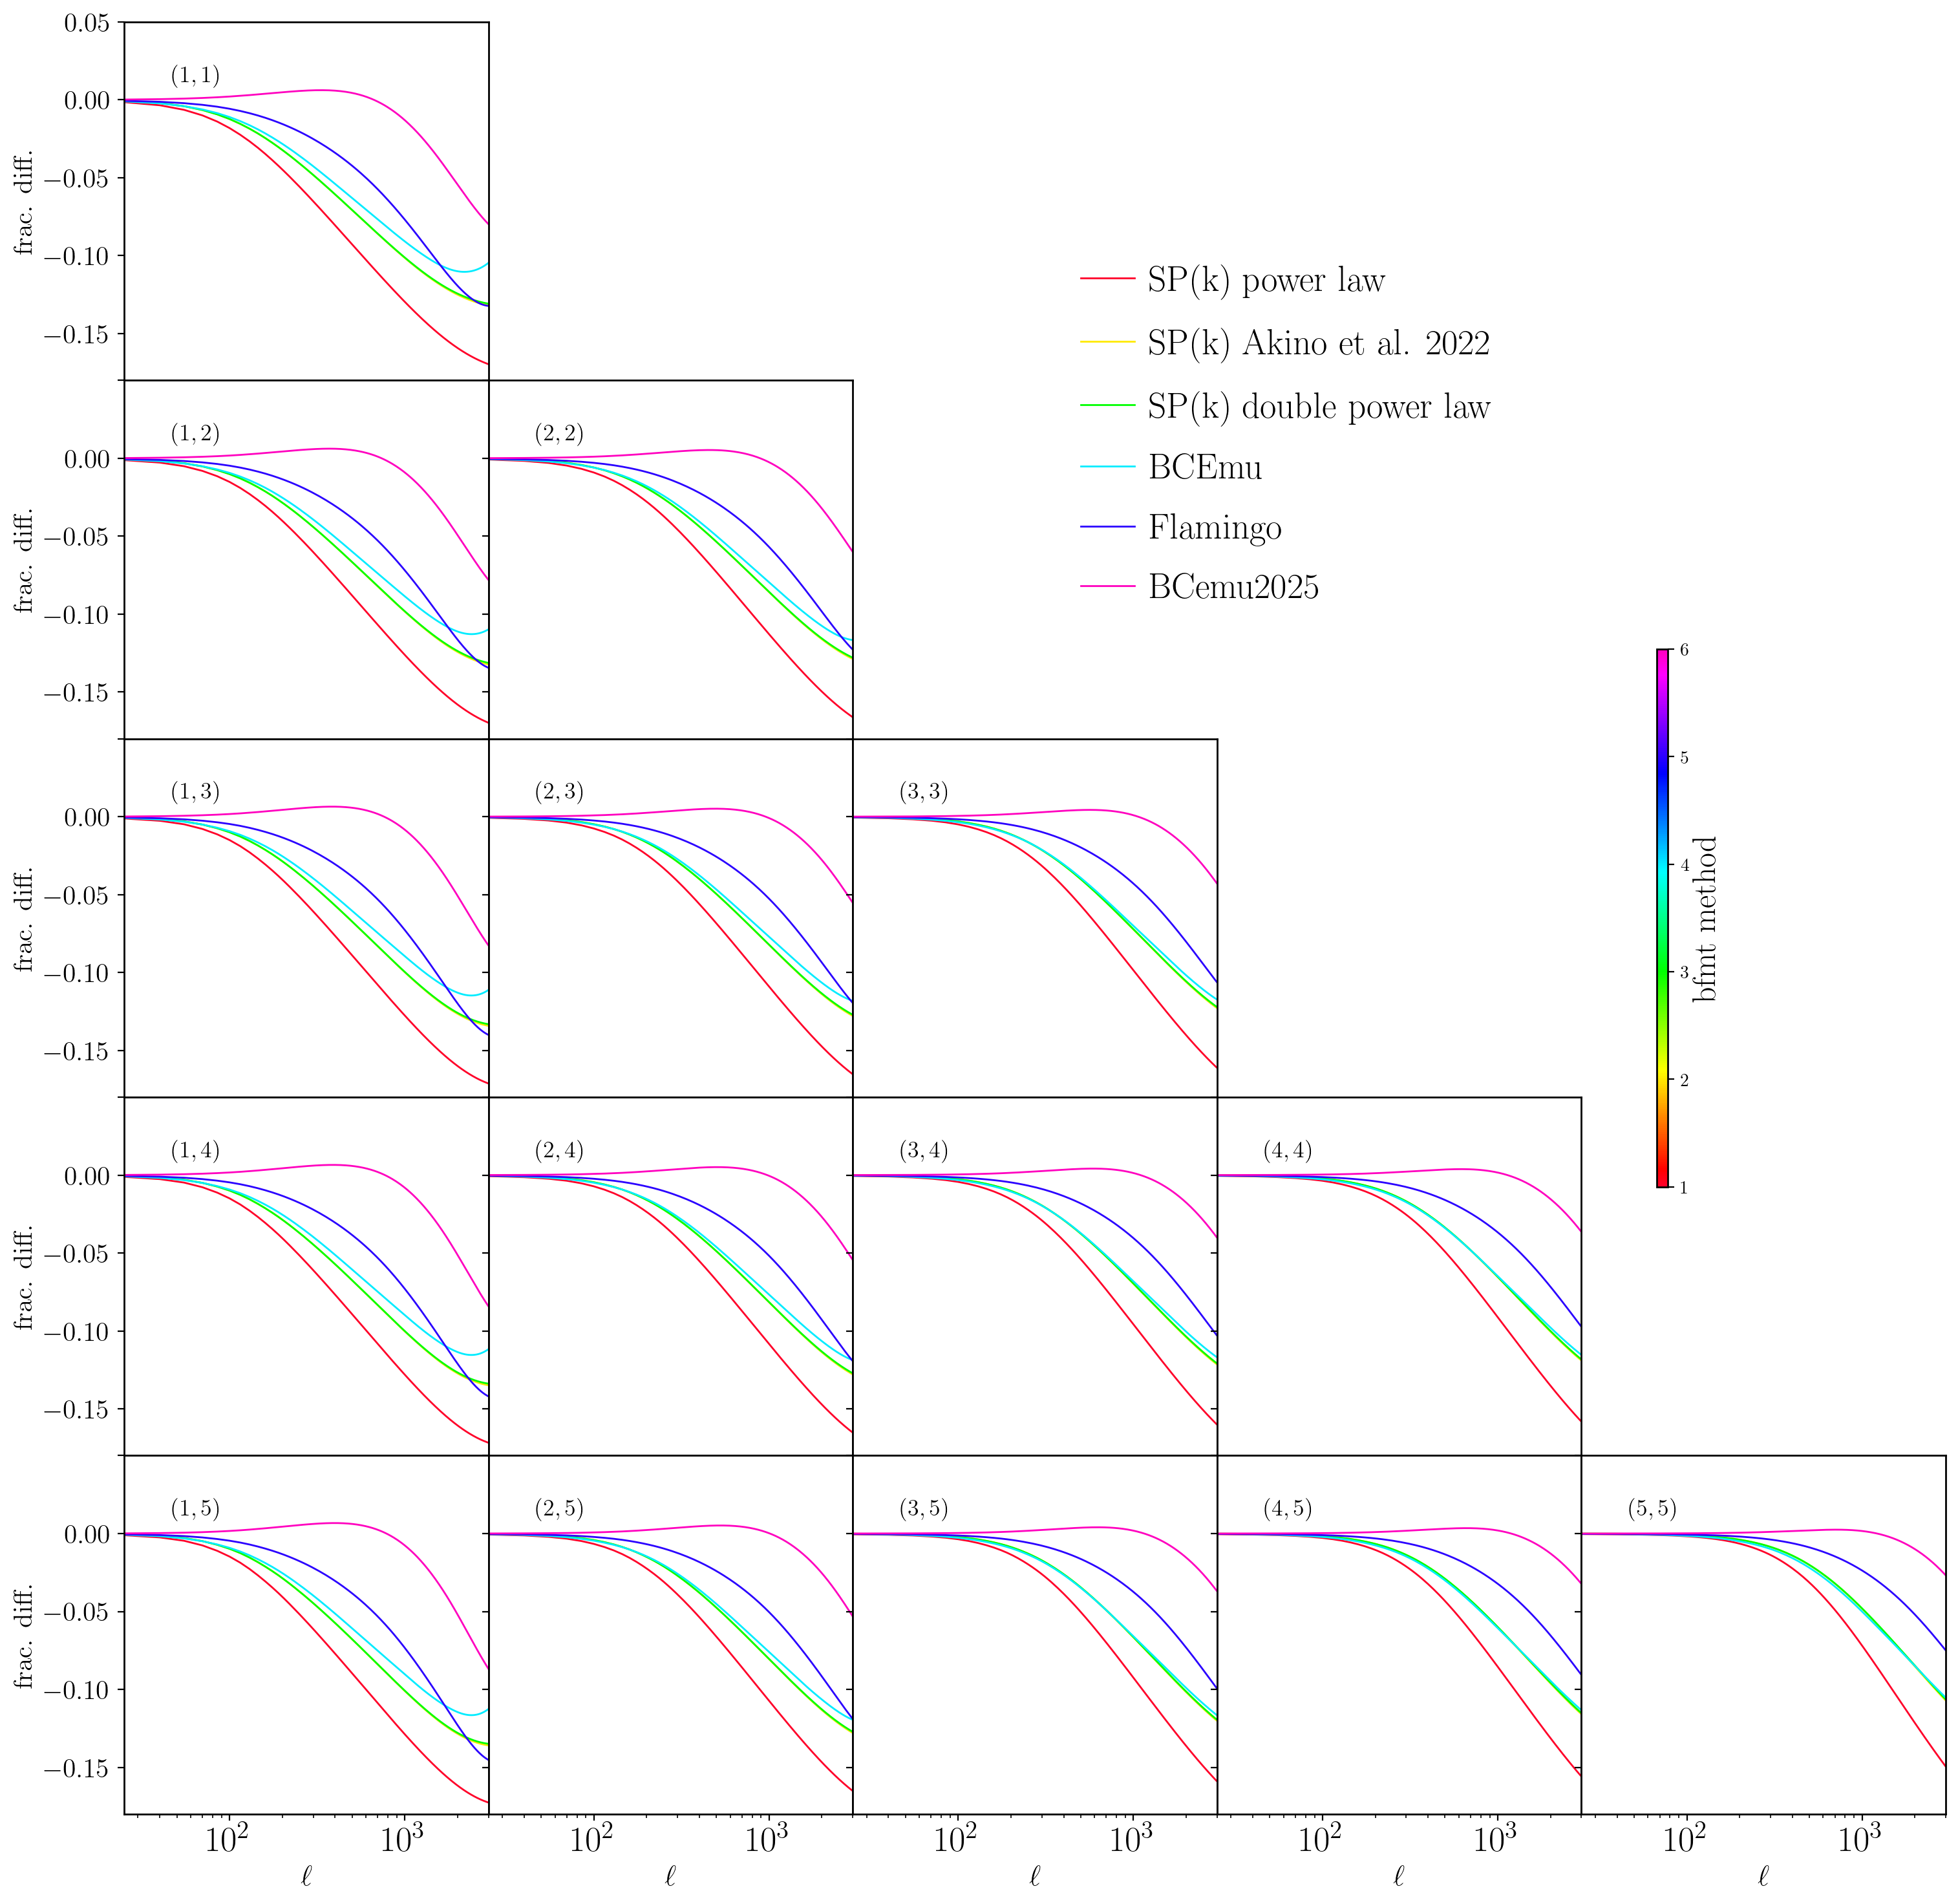

In [12]:
labels = [label for label, _, _ in BARYON_METHODS]

# param only orders the curve colors, one value per method; the legend names
# the methods.
param = np.arange(1.0, 1.0 + len(labels))

C_ss_list = [results[label]["C_ss"] for label in labels]

cnu.plot_C_ss_tomo_limber(ell=ref["ell"],
                          C_ss=C_ss_list,
                          C_ss_ref=ref["C_ss"],
                          param=param,
                          lmin=25,
                          lmax=3000,
                          ylim=(0.82, 1.05),
                          colorbarlabel="bfmt method",
                          legend=labels,
                          figsize=(18, 18),
                          legendloc=(0.55, 0.68),
                          legendfontsize=20,
                          xaxisticklabelsize=20,
                          yaxisticklabelsize=15,
                          yaxislabelsize=15)

## 9. Cosmic shear with feedback: $\xi_\pm(\theta)$

The same comparison in real space, first $\xi_+$ and then $\xi_-$, over the full
angular range of the data vector, in the band −12.5% to +5%. Feedback reaches larger
angles in $\xi_-$, which weights smaller physical scales than $\xi_+$ at the same angle.

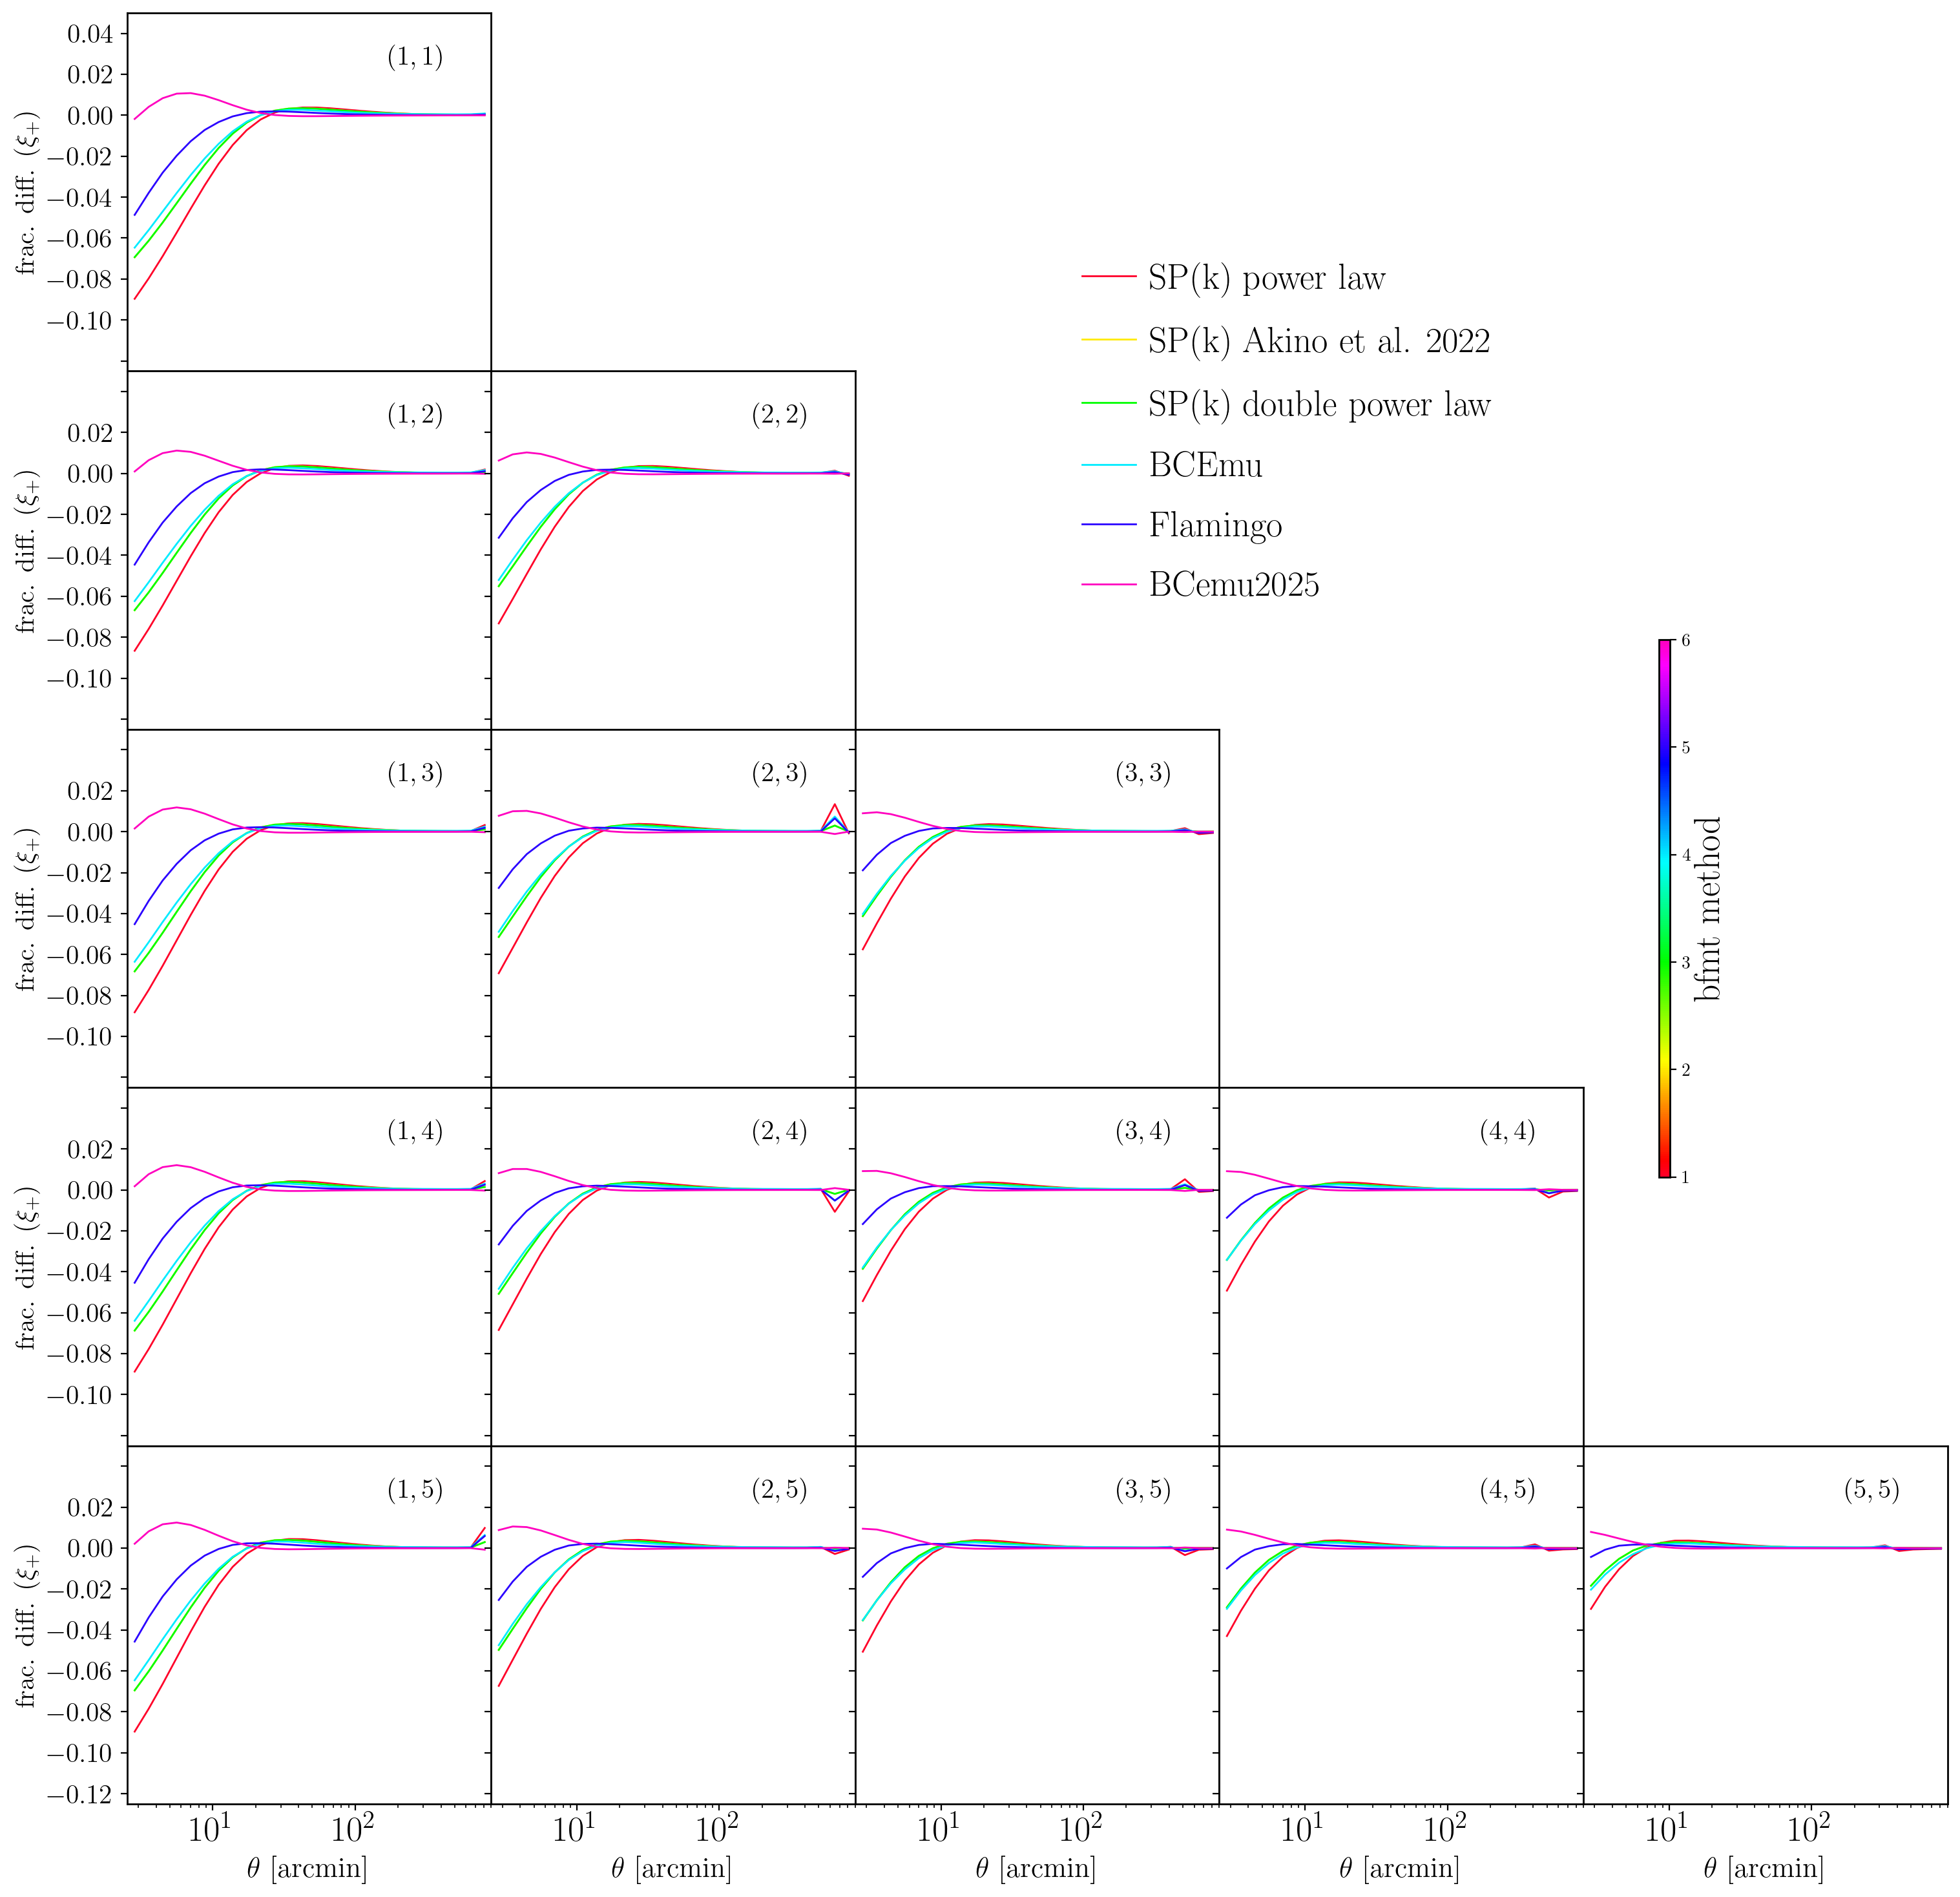

In [13]:
# Each entry is the (theta, xi_plus, xi_minus) tuple that plot_xi expects.
xi_list = [(results[label]["theta"], results[label]["xip"],
            results[label]["xim"]) for label in labels]

xi_ref = (ref["theta"], ref["xip"], ref["xim"])

cnu.plot_xi(pm=1,
            xi=xi_list,
            xi_ref=xi_ref,
            param=param,
            ylim=(0.875, 1.05),
            colorbarlabel="bfmt method",
            legend=labels,
            thetashow=[2.5, 900],
            legendloc=(0.55, 0.68),
            legendfontsize=20,
            xaxisticklabelsize=20,
            yaxisticklabelsize=15,
            yaxislabelsize=15)

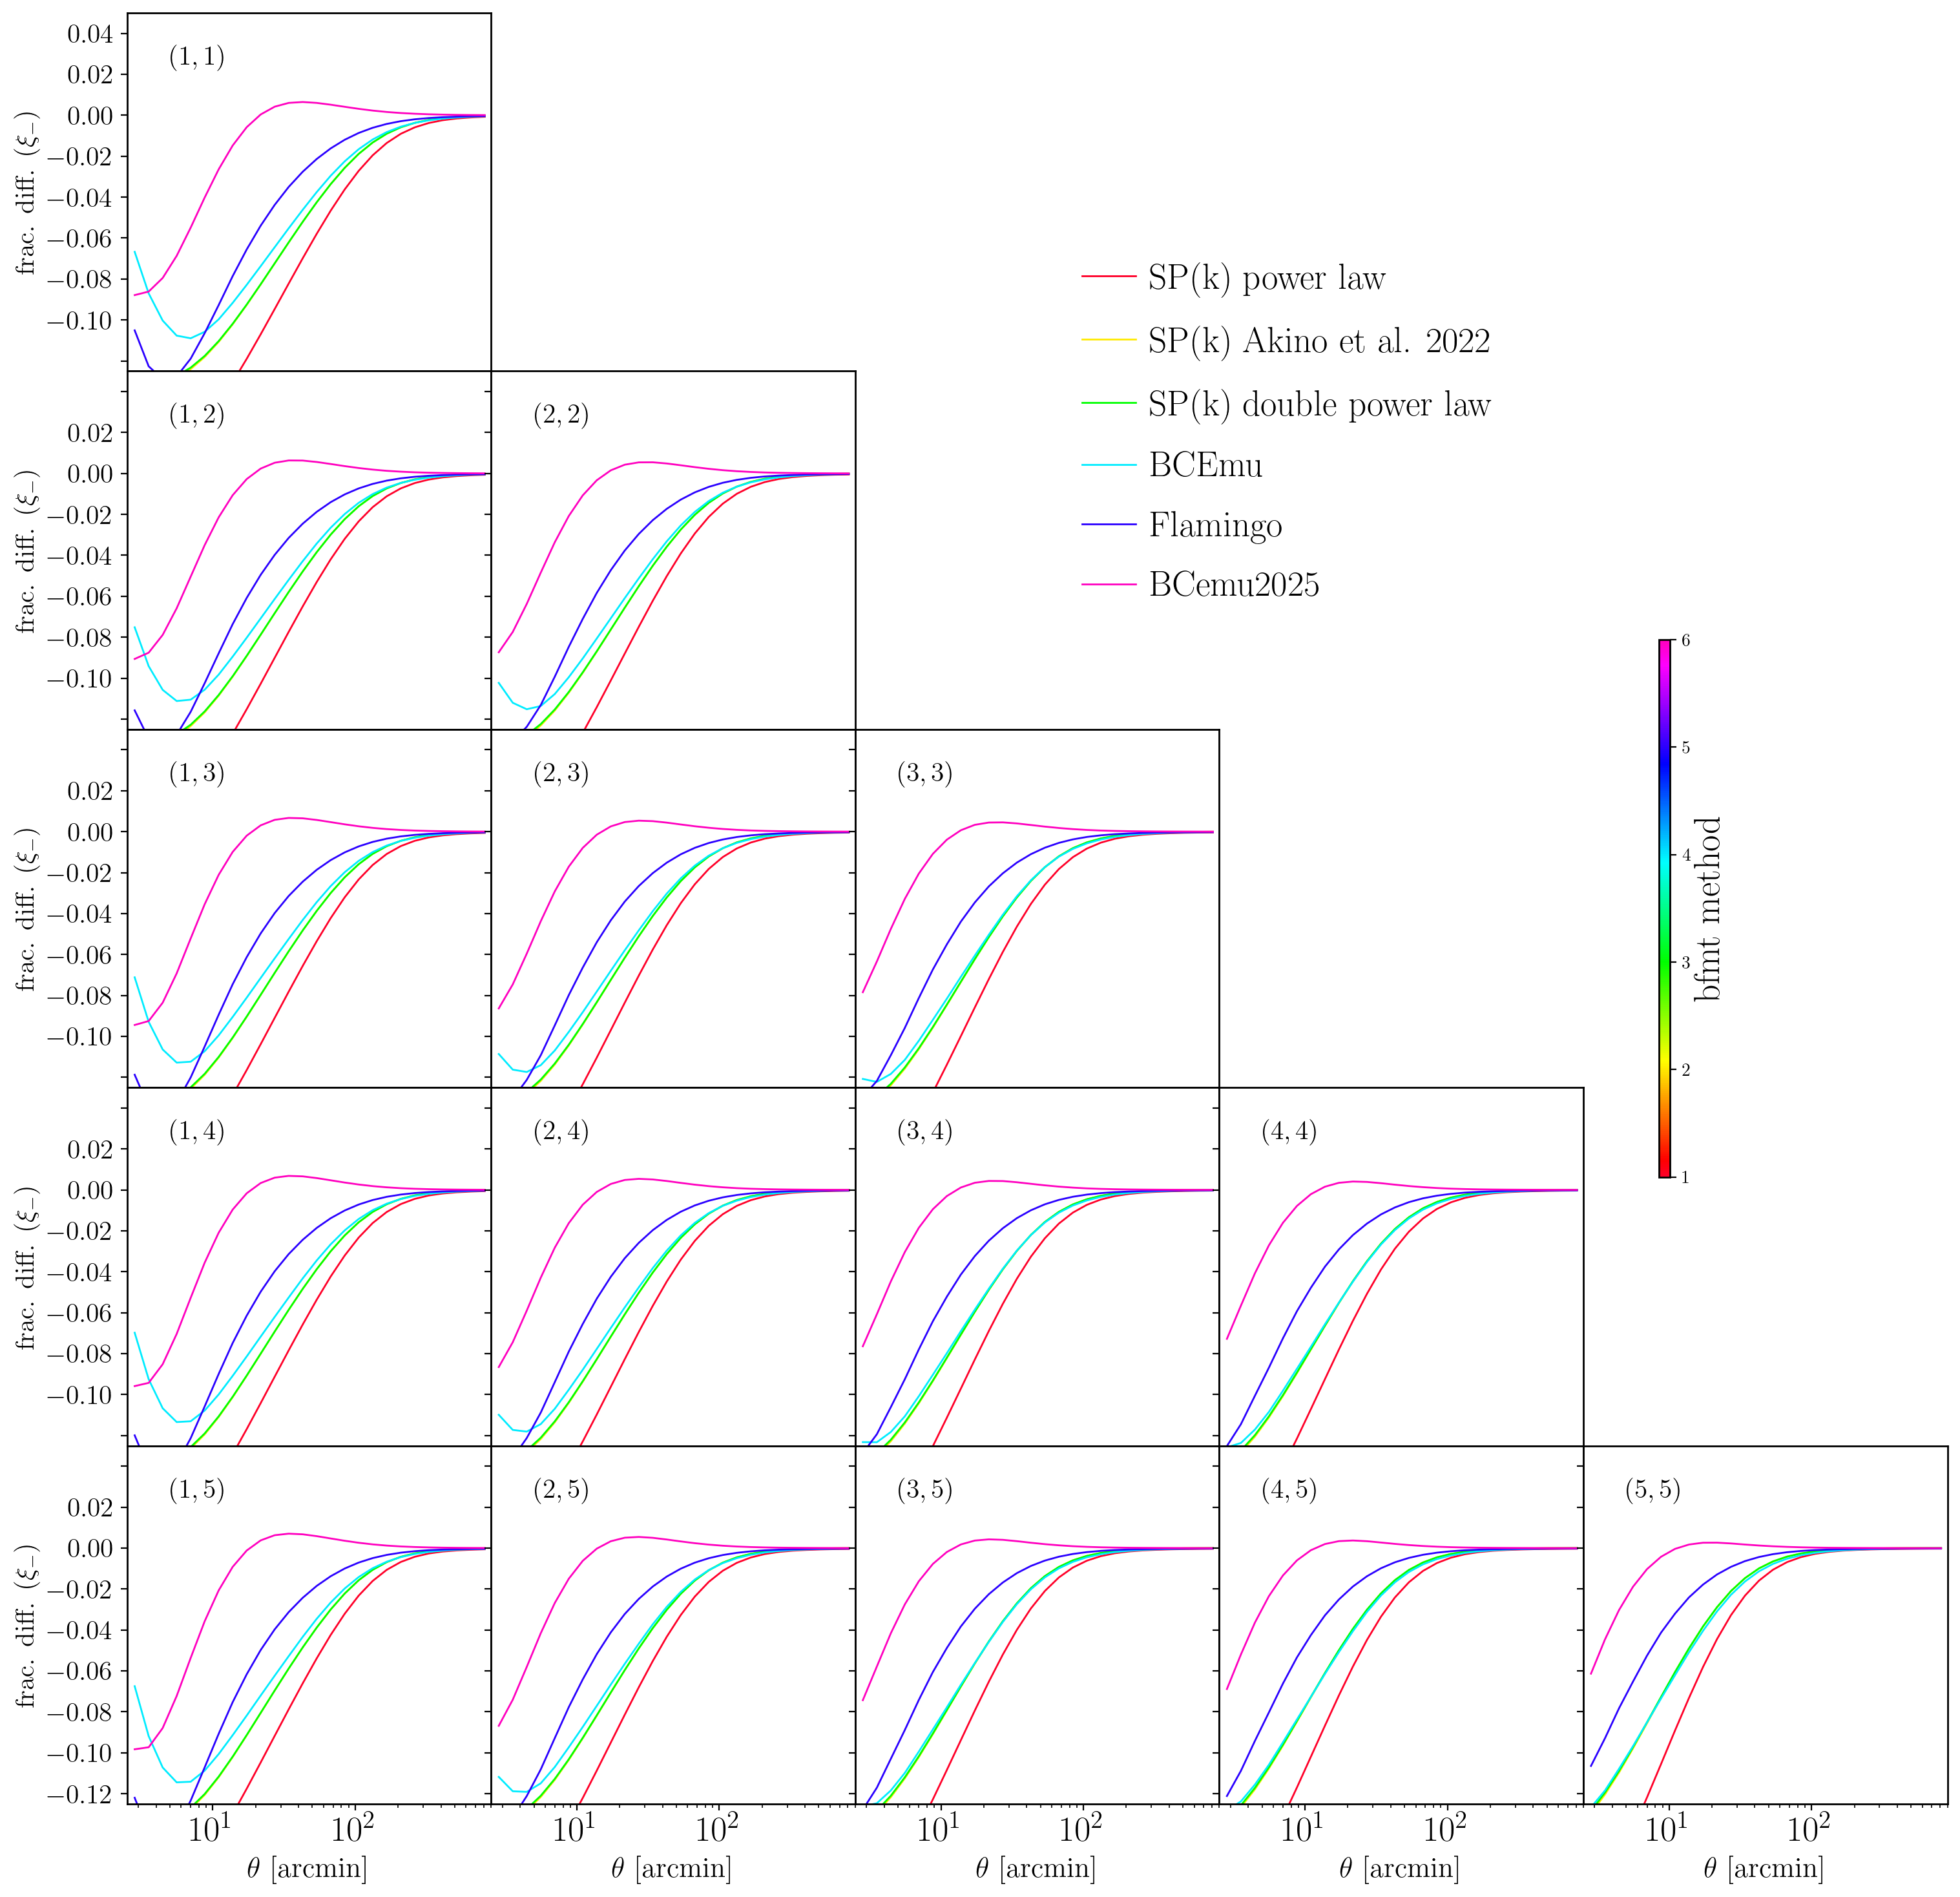

In [14]:
# pm <= 0 draws xi_minus.
cnu.plot_xi(pm=0,
            xi=xi_list,
            xi_ref=xi_ref,
            param=param,
            ylim=(0.875, 1.05),
            colorbarlabel="bfmt method",
            legend=labels,
            figsize=(18, 18),
            thetashow=[2.5, 900],
            legendloc=(0.55, 0.68),
            legendfontsize=20,
            xaxisticklabelsize=20,
            yaxisticklabelsize=15,
            yaxislabelsize=15)

## 10. Galaxy–galaxy lensing with feedback: $C_\ell^{gs}$

One row per source bin and one column per lens bin, labeled (lens, source), with
$C_\ell^{gs,\,\rm feedback}/C_\ell^{gs,\,\rm none}-1$ in the band −20% to +5%. Pairs whose
source bin lies in front of the lens bin carry little lensing signal, so their ratios
say little about feedback.

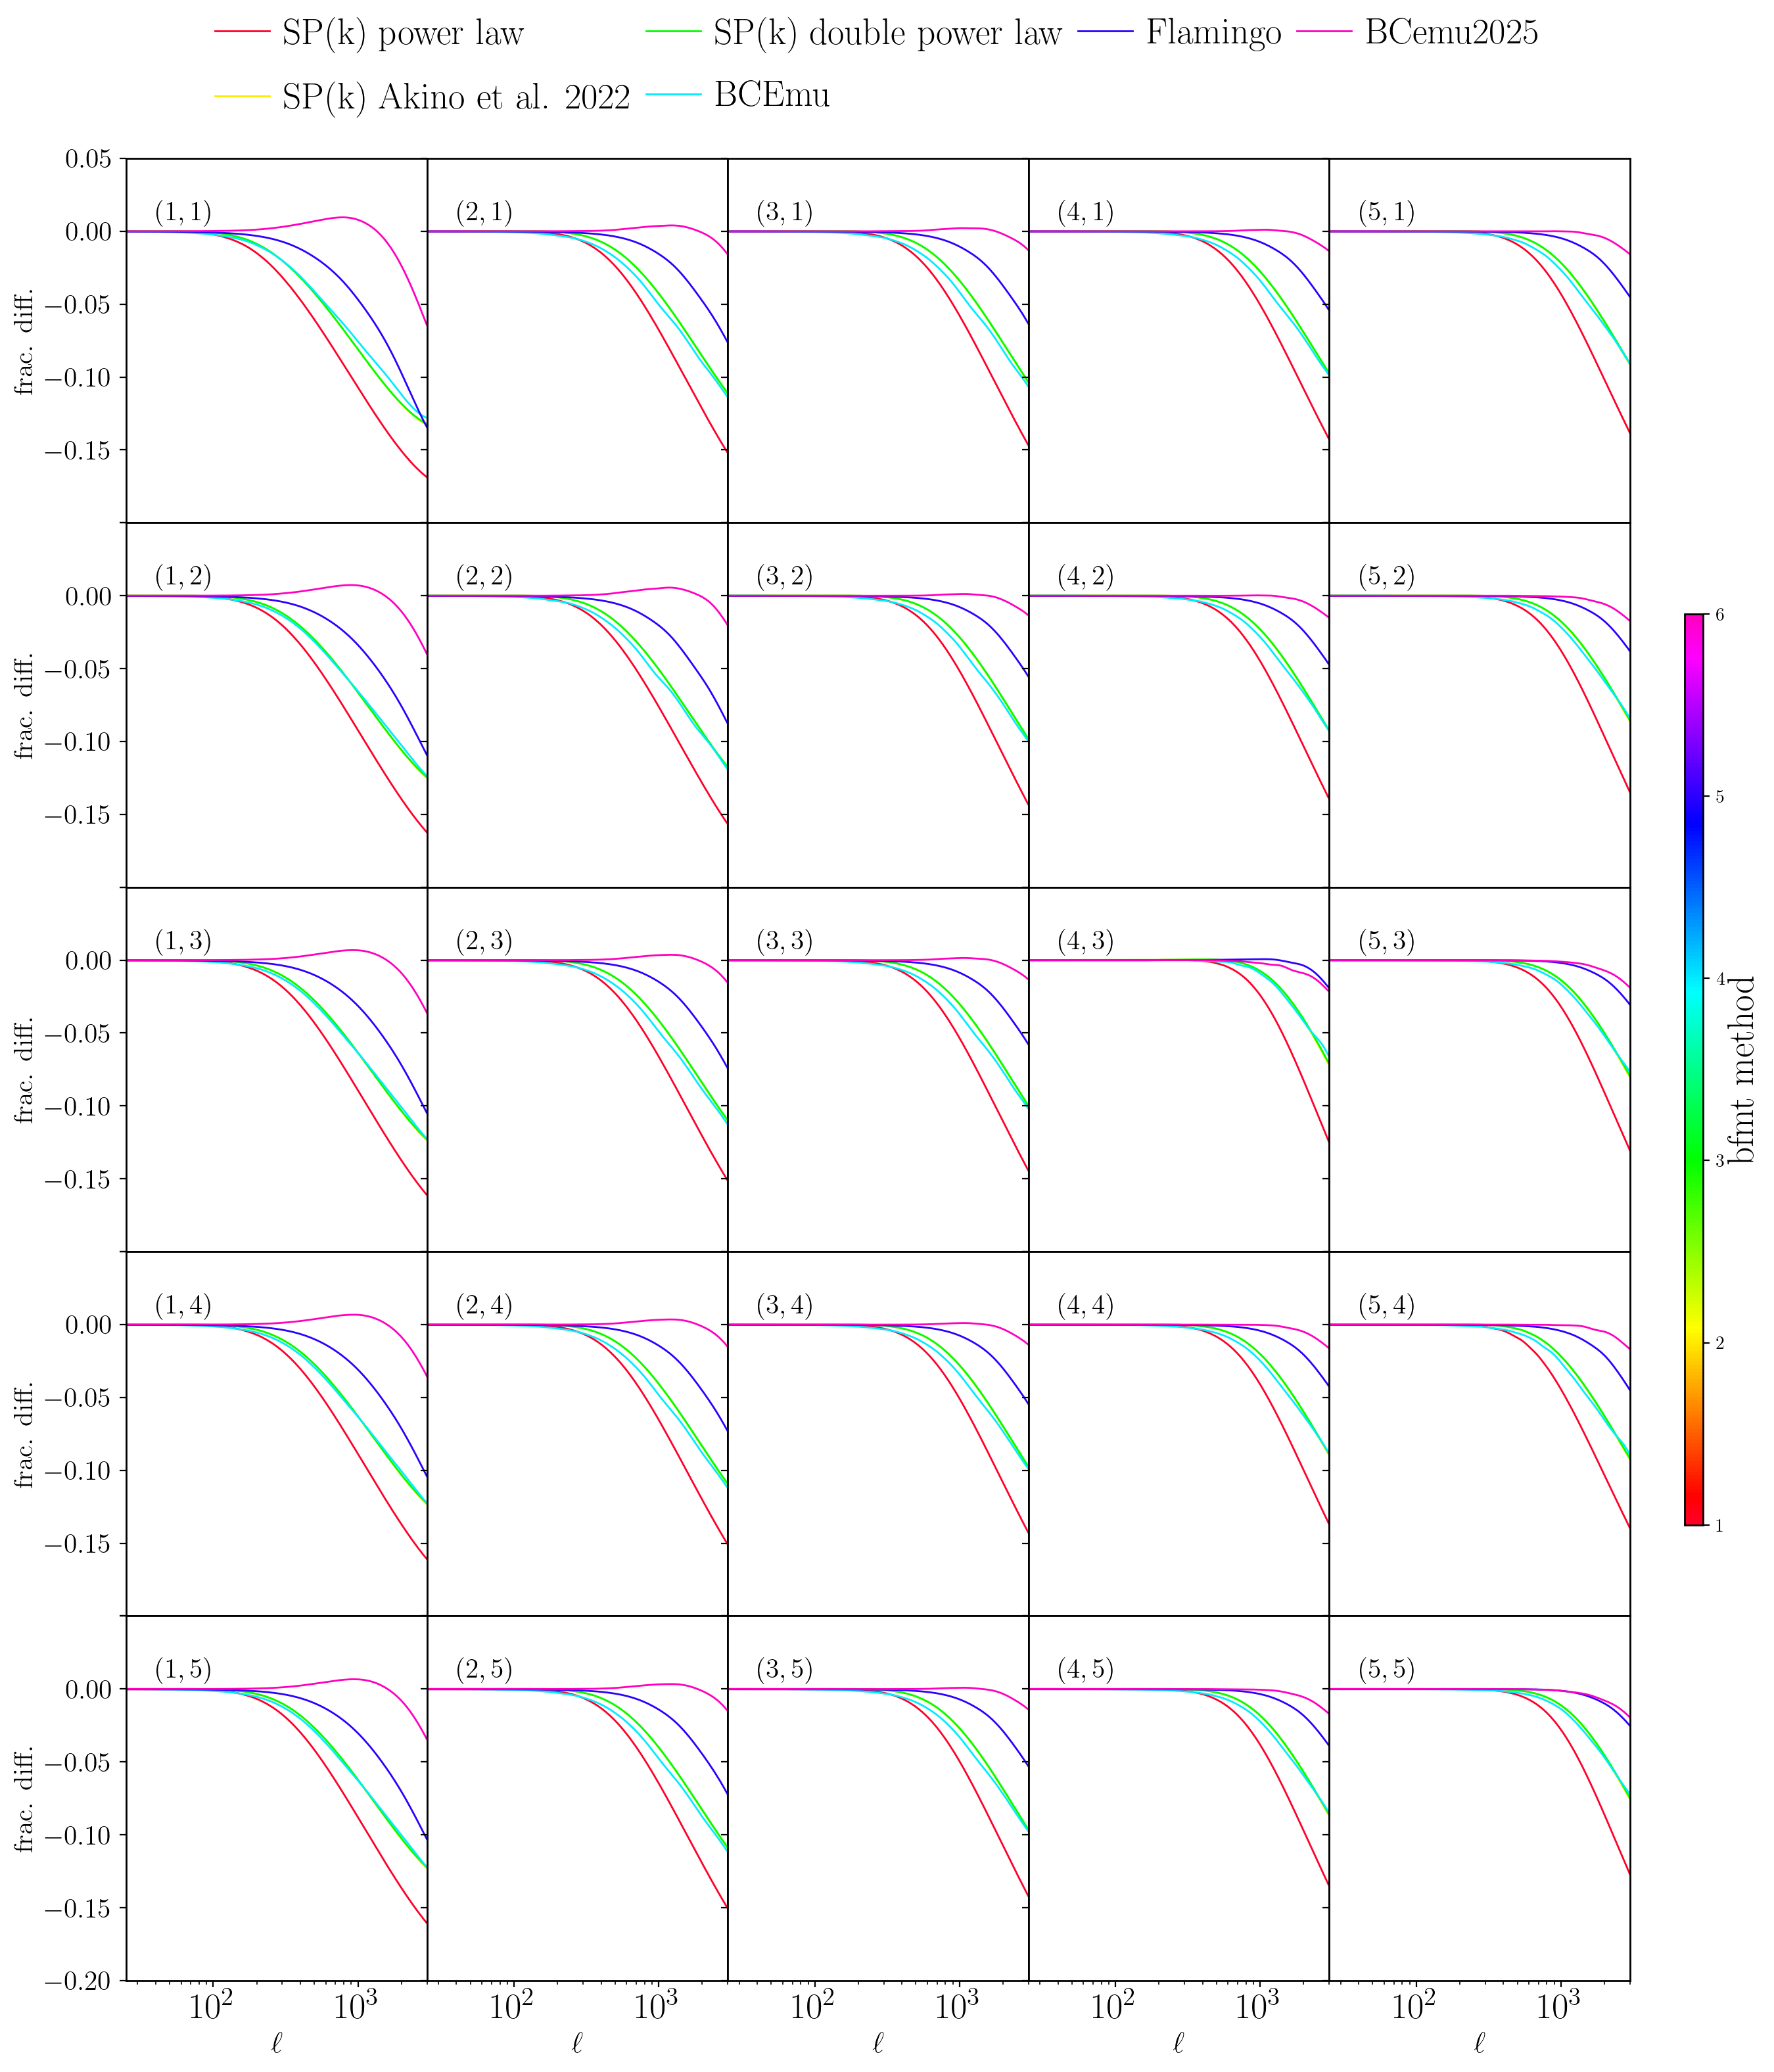

In [15]:
C_gs_list = [results[label]["C_gs"] for label in labels]

cnu.plot_C_gs_tomo_limber(ell=ref["ell"],
                          C_gs=C_gs_list,
                          C_gs_ref=ref["C_gs"],
                          param=param,
                          lmin=25,
                          lmax=3000,
                          figsize=(18, 18),
                          ylim=(0.8, 1.05),
                          colorbarlabel="bfmt method",
                          legend=labels,
                          legendfontsize=20,
                          xaxisticklabelsize=20,
                          yaxisticklabelsize=15,
                          yaxislabelsize=15)

## 11. Galaxy–galaxy lensing with feedback: $\gamma_t(\theta)$

The same grid in real space, $\gamma_t^{\rm feedback}/\gamma_t^{\rm none}-1$ in the band
−20% to +5%. Expect the suppression to concentrate at small angles, where $\gamma_t$
probes the matter distribution close to the lens halos.

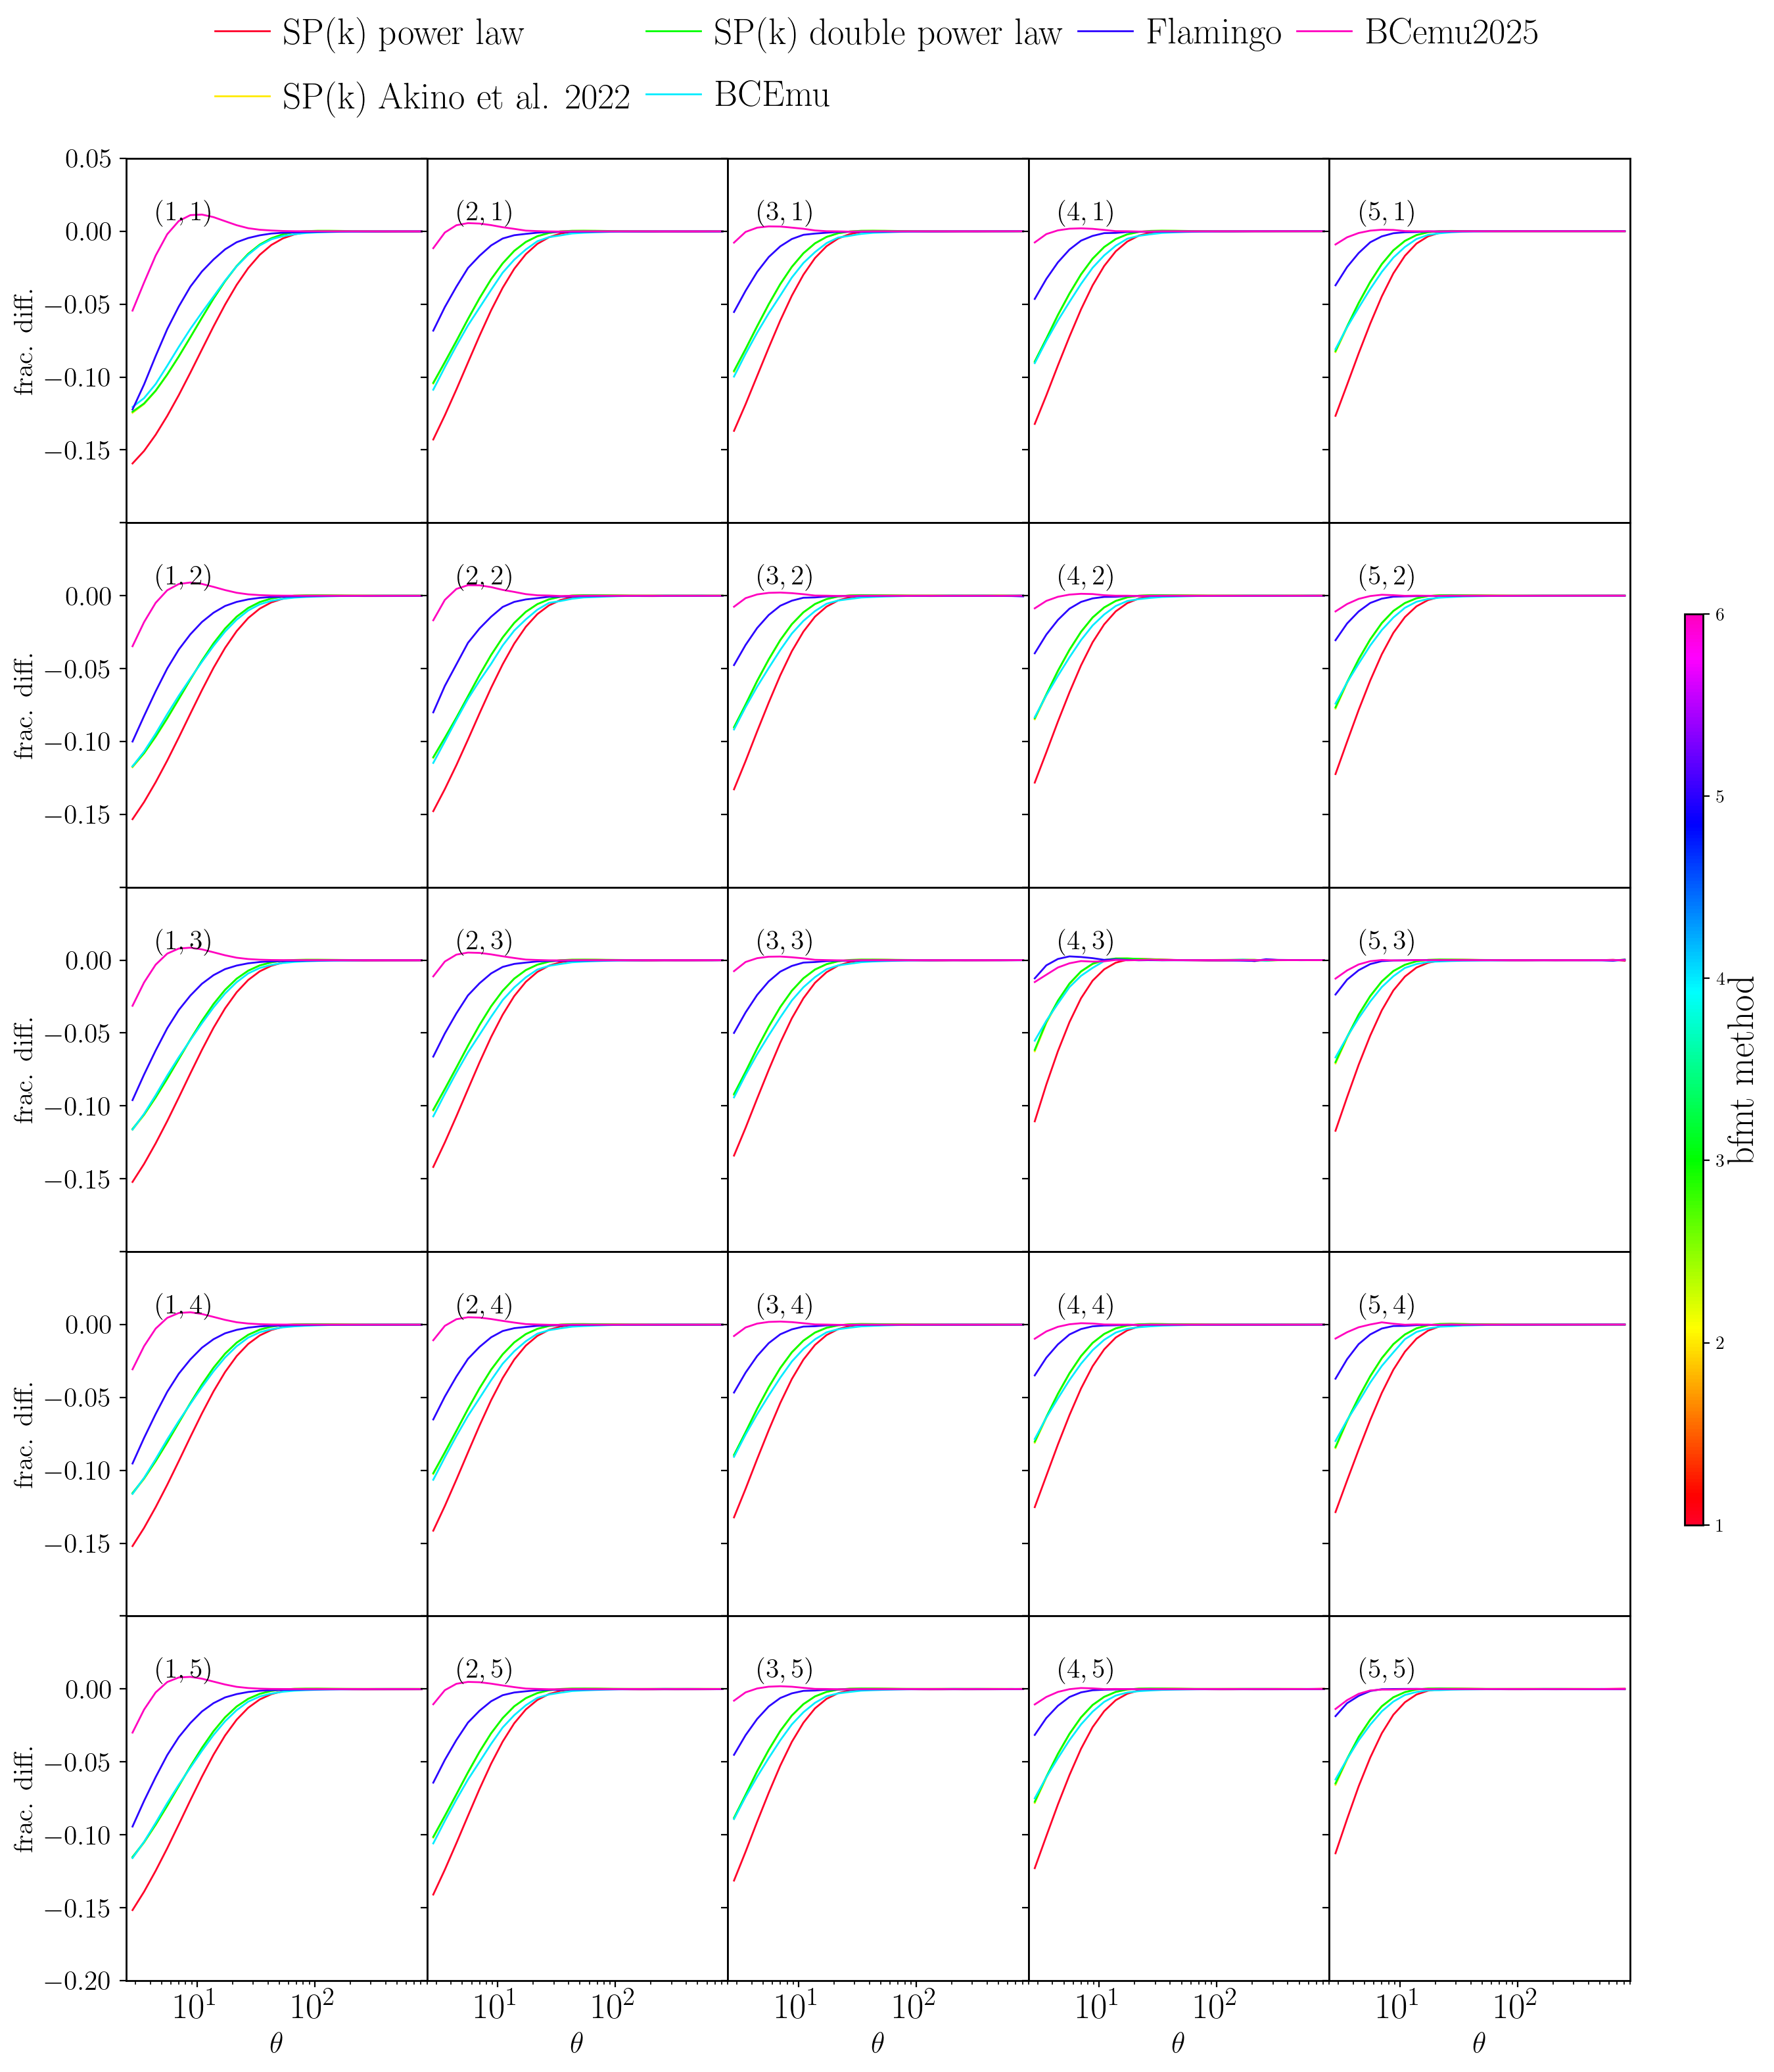

In [16]:
gammat_list = [(results[label]["theta"], results[label]["gammat"])
               for label in labels]
gammat_ref = (ref["theta"], ref["gammat"])
cnu.plot_gammat_tomo_limber(theta_gammat=gammat_list,
                            gammat_ref=gammat_ref,
                            param=param,
                            ylim=(0.8, 1.05),
                            figsize=(18, 18),
                            colorbarlabel="bfmt method",
                            legend=labels,
                            thetashow=[2.5, 900],
                            legendfontsize=20,
                            xaxisticklabelsize=20,
                            yaxisticklabelsize=15,
                            yaxislabelsize=15)

## 12. Vary each method's free parameters, one at a time

Each figure below sweeps a single parameter of one feedback method, holding everything
else at the method's fiducial point, and shows the suppression
$S(k)=P_{\rm feedback}/P_{\rm DM}$ against $\log_{10}k$ ($k$ in 1/Mpc) at $z=0$ (solid)
and $z=1$ (dashed), one color per parameter value (color bar), in the band 0.6–1.35.
No data vector is computed here. The sweep ranges sit inside the `bfmt` validation
boxes: the 3$\sigma$ boxes of the YAML priors for SP(k) Akino, the emulator training
boxes otherwise. An SP(k) curve can revert to unity at a redshift where the swept
parameter pushes the baryon fraction outside the calibrated band of `pyspk`, the SP(k)
package; that is the block's documented fallback, not a bug. Every value is one
`get_baryon_suppression` call (a fresh CAMB run), so this section evaluates CAMB about
130 times and takes tens of minutes. The next cell defines the sweep grids and two
helper functions; each cell after it draws the figures of one method.

In [17]:
import io
from contextlib import redirect_stdout, redirect_stderr

# The sweep grid: two redshifts are enough to see the evolution, and
# the k grid spans the scales where feedback acts (1/Mpc, the unit the
# likelihoods send). SWEEP_RESULTS keeps every computed sweep, so a
# figure can be replotted without recomputing.
z_sweep = [0.0, 1.0]
log10k_sweep = np.linspace(-1.3, 1.1, 120)
SWEEP_RESULTS = {}
METHODS_BY_LABEL = {label: (options, point)
                    for label, options, point in BARYON_METHODS}

PARAM_SWEEPS = {
    # loose boxes; the hard guard is pyspk's calibrated fb band
    "SP(k) power law": {
        "fb_a_spk":   [0.2, 0.3, 0.4, 0.5, 0.6],
        "fb_pow_spk": [0.1, 0.2, 0.3, 0.4, 0.5],
    },
    # 3-sigma boxes: alpha 3.8-4.6, beta 1.0-1.6, gamma 0.1-0.75
    "SP(k) Akino et al. 2022": {
        "alpha_spk": [3.9, 4.05, 4.189, 4.35, 4.5],
        "beta_spk":  [1.05, 1.16, 1.273, 1.4, 1.55],
        "gamma_spk": [0.15, 0.22, 0.298, 0.45, 0.6],
    },
    # centered on the in-band point of the methods table above
    "SP(k) double power law": {
        "epsilon_spk": [0.50, 0.58, 0.66, 0.74, 0.82],
        "alpha_spk":   [0.15, 0.25, 0.35, 0.45, 0.55],
        "beta_spk":    [0.10, 0.15, 0.20, 0.25, 0.30],
        "gamma_spk":   [0.10, 0.20, 0.30, 0.40, 0.50],
    },
    # inside the Giri et al. 2021 training box
    "BCEmu": {
        "log10Mc_bcemu": [12.5, 13.0, 13.32, 13.8, 14.3],
        "mu_bcemu":      [0.3, 0.6, 0.93, 1.3, 1.7],
        "thej_bcemu":    [2.5, 3.3, 4.235, 5.3, 6.5],
        "gamma_bcemu":   [1.5, 1.9, 2.25, 2.8, 3.5],
        "delta_bcemu":   [4.0, 5.2, 6.4, 7.7, 9.0],
        "eta_bcemu":     [0.08, 0.11, 0.15, 0.25, 0.35],
        "deta_bcemu":    [0.08, 0.11, 0.14, 0.25, 0.35],
    },
    # the Schaller et al. 2025 suite spans fgas -8sigma..+2sigma,
    # mstar -1sigma, and jet fractions 0..1
    "Flamingo": {
        "fgas_sigma_flamingo":  [-8.0, -4.0, -2.0, 0.0, 2.0],
        "mstar_sigma_flamingo": [-1.0, -0.5, 0.0, 0.5, 1.0],
        "jet_frac_flamingo":    [0.0, 0.25, 0.5, 0.75, 1.0],
    },
    # inside the BCemu2025 training LHC box
    "BCemu2025": {
        "Theta_co_bcemu25": [0.1, 0.2, 0.3, 0.45, 0.6],
        "log10Mc_bcemu25":  [12.0, 12.6, 13.1, 13.7, 14.4],
        "mu_bcemu25":       [0.4, 0.7, 1.0, 1.5, 2.0],
        "delta_bcemu25":    [3.0, 4.5, 6.0, 8.0, 10.0],
        "eta_bcemu25":      [-0.15, -0.05, 0.02, 0.10, 0.18],
        "deta_bcemu25":     [0.05, 0.12, 0.22, 0.30, 0.38],
        "Nstar_bcemu25":    [0.010, 0.019, 0.028, 0.037, 0.045],
    },
}

def sweep_parameter(label, name, values):
    """One-at-a-time sweep: name takes each value, the rest stay at
    the method's fiducial point; returns one (n_z, n_k) array per
    value and caches them in SWEEP_RESULTS. Everything the libraries
    print while a model builds (emulator loading bars, cobaya
    banners) goes to an in-memory buffer instead of the notebook, so
    a sweep cell shows only its figures; an exception still surfaces
    with its full traceback."""
    options, fiducial = METHODS_BY_LABEL[label]
    sups = []
    for v in values:
        point = dict(fiducial, **{name: v})
        chatter = io.StringIO()
        with redirect_stdout(chatter), redirect_stderr(chatter):
            S = nw.get_baryon_suppression(options, point,
                                       z_sweep, log10k_sweep)
        sups.append(np.array([S[z] for z in z_sweep]))
    SWEEP_RESULTS.setdefault(label, {})[name] = sups
    return sups

# plot_sweeps(label): one figure per free parameter of the method, each from five
# sweep_parameter values, drawn with cnu.plot_baryon_suppression.
def plot_sweeps(label):
    for name, values in PARAM_SWEEPS[label].items():
        sups = sweep_parameter(label, name, values)
        cnu.plot_baryon_suppression(log10k=log10k_sweep,
                                    sup=sups,
                                    param=np.array(values),
                                    colorbarlabel=name.replace("_", " "),
                                    zlabels=["$z=0$", "$z=1$"],
                                    ylim=(0.6, 1.35),
                                    title=label + ": vary " + name.replace("_", " "))

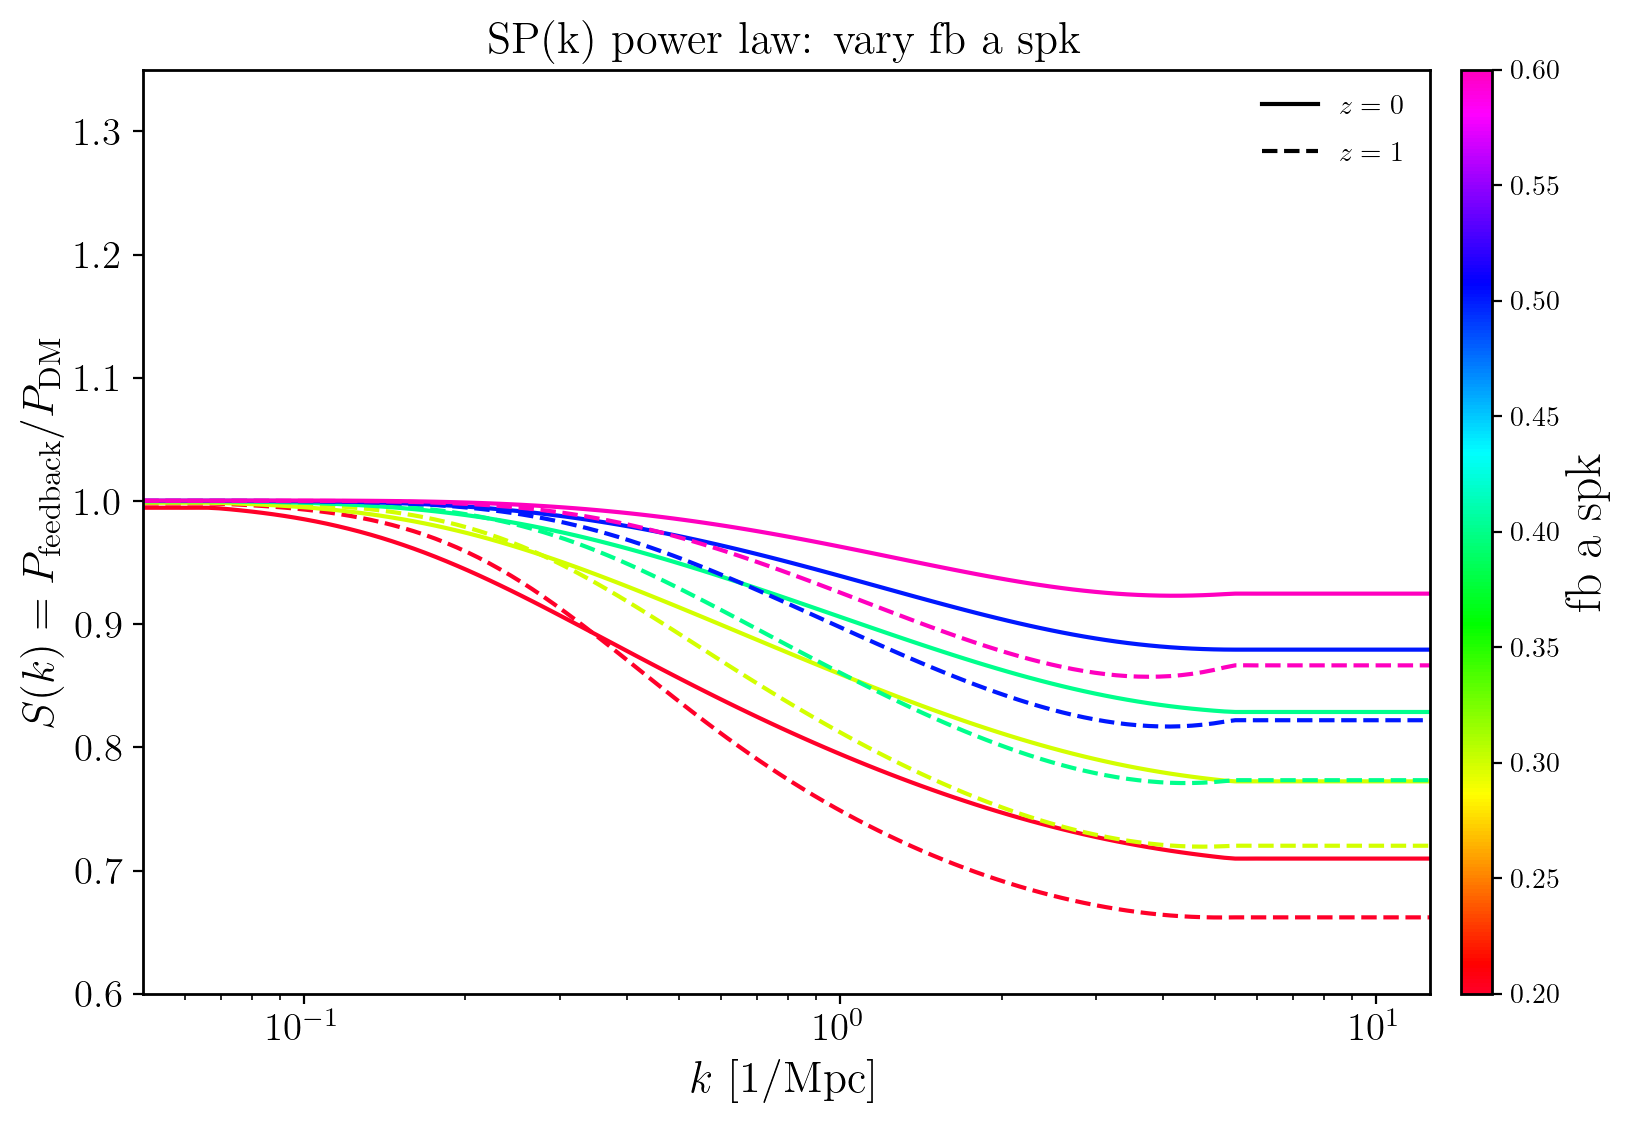

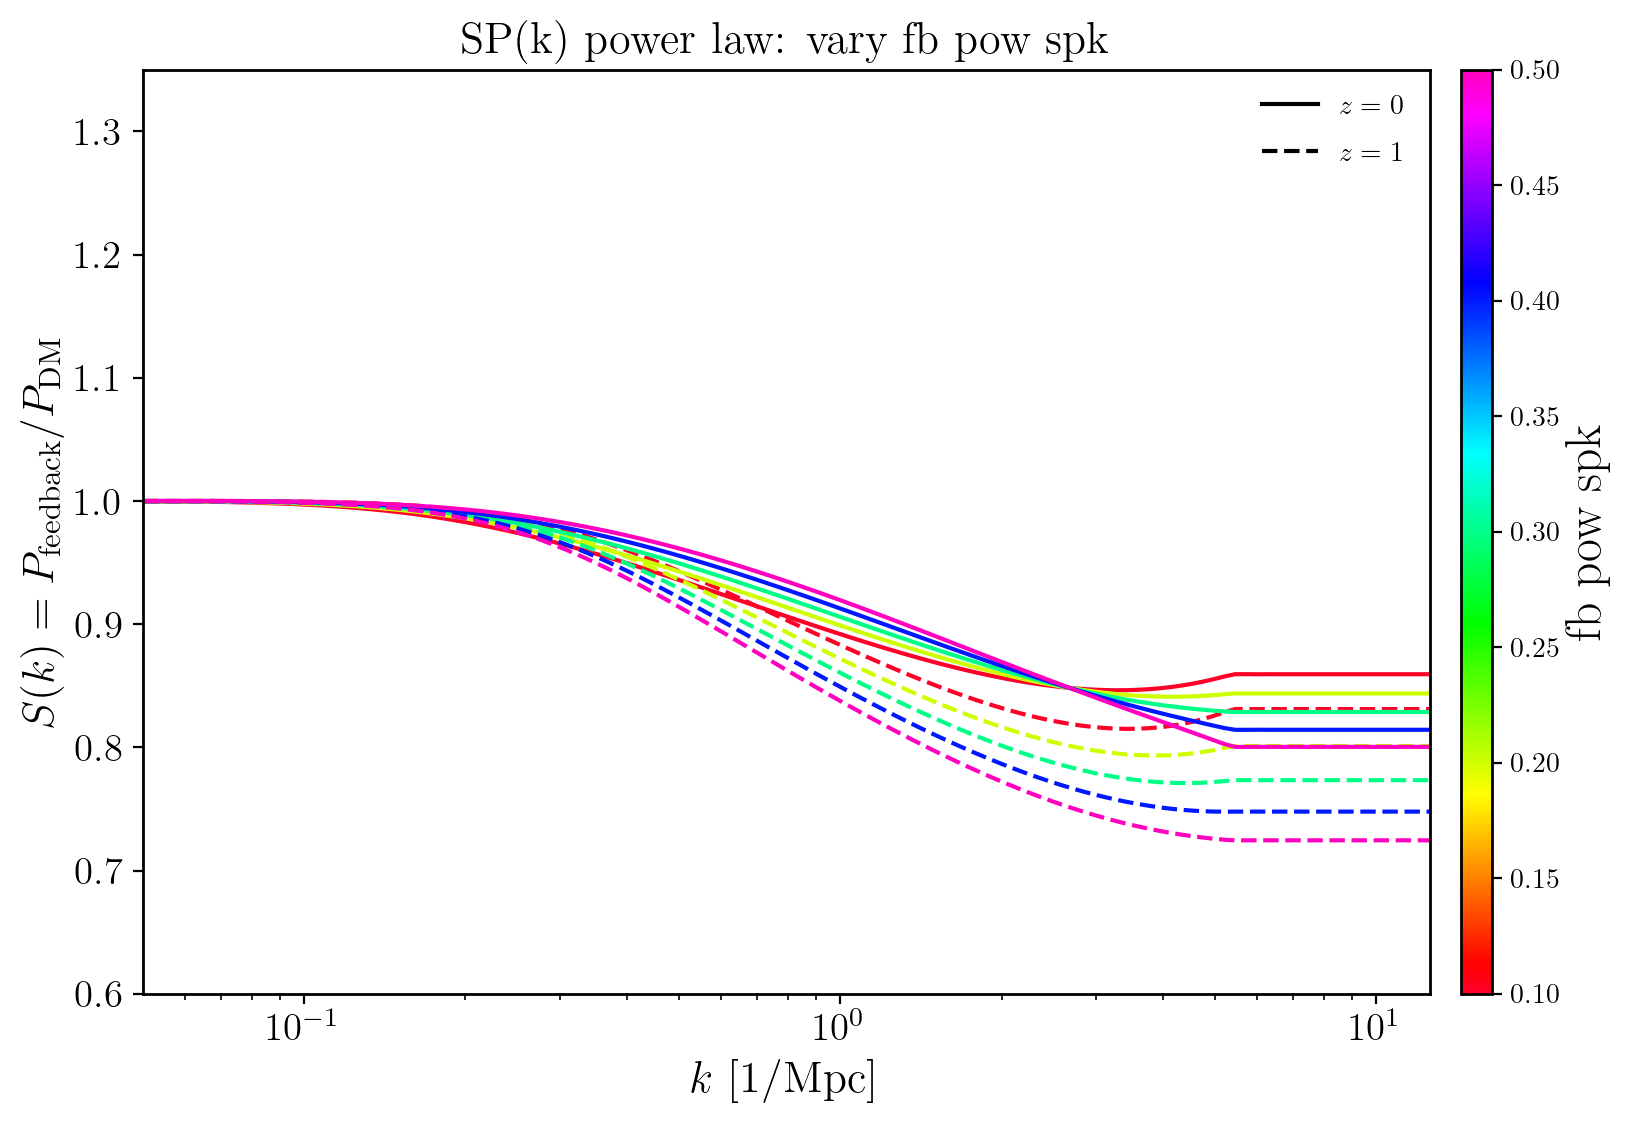

In [18]:
plot_sweeps("SP(k) power law")

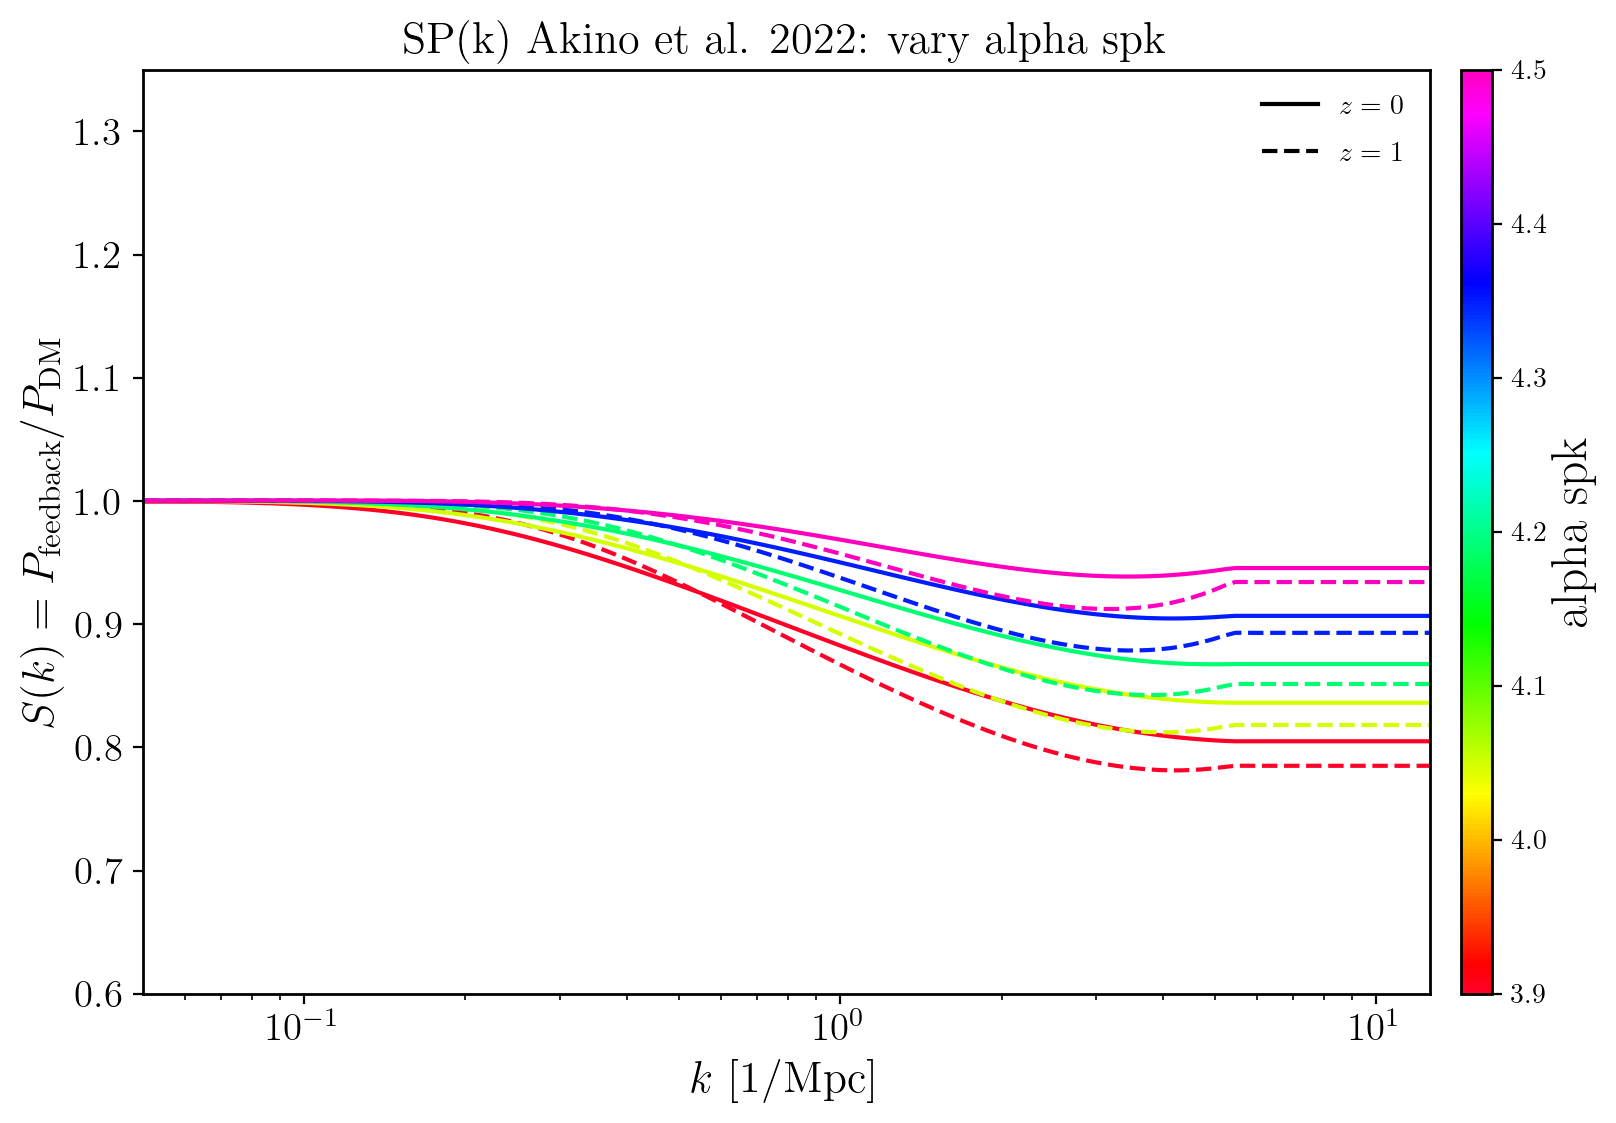

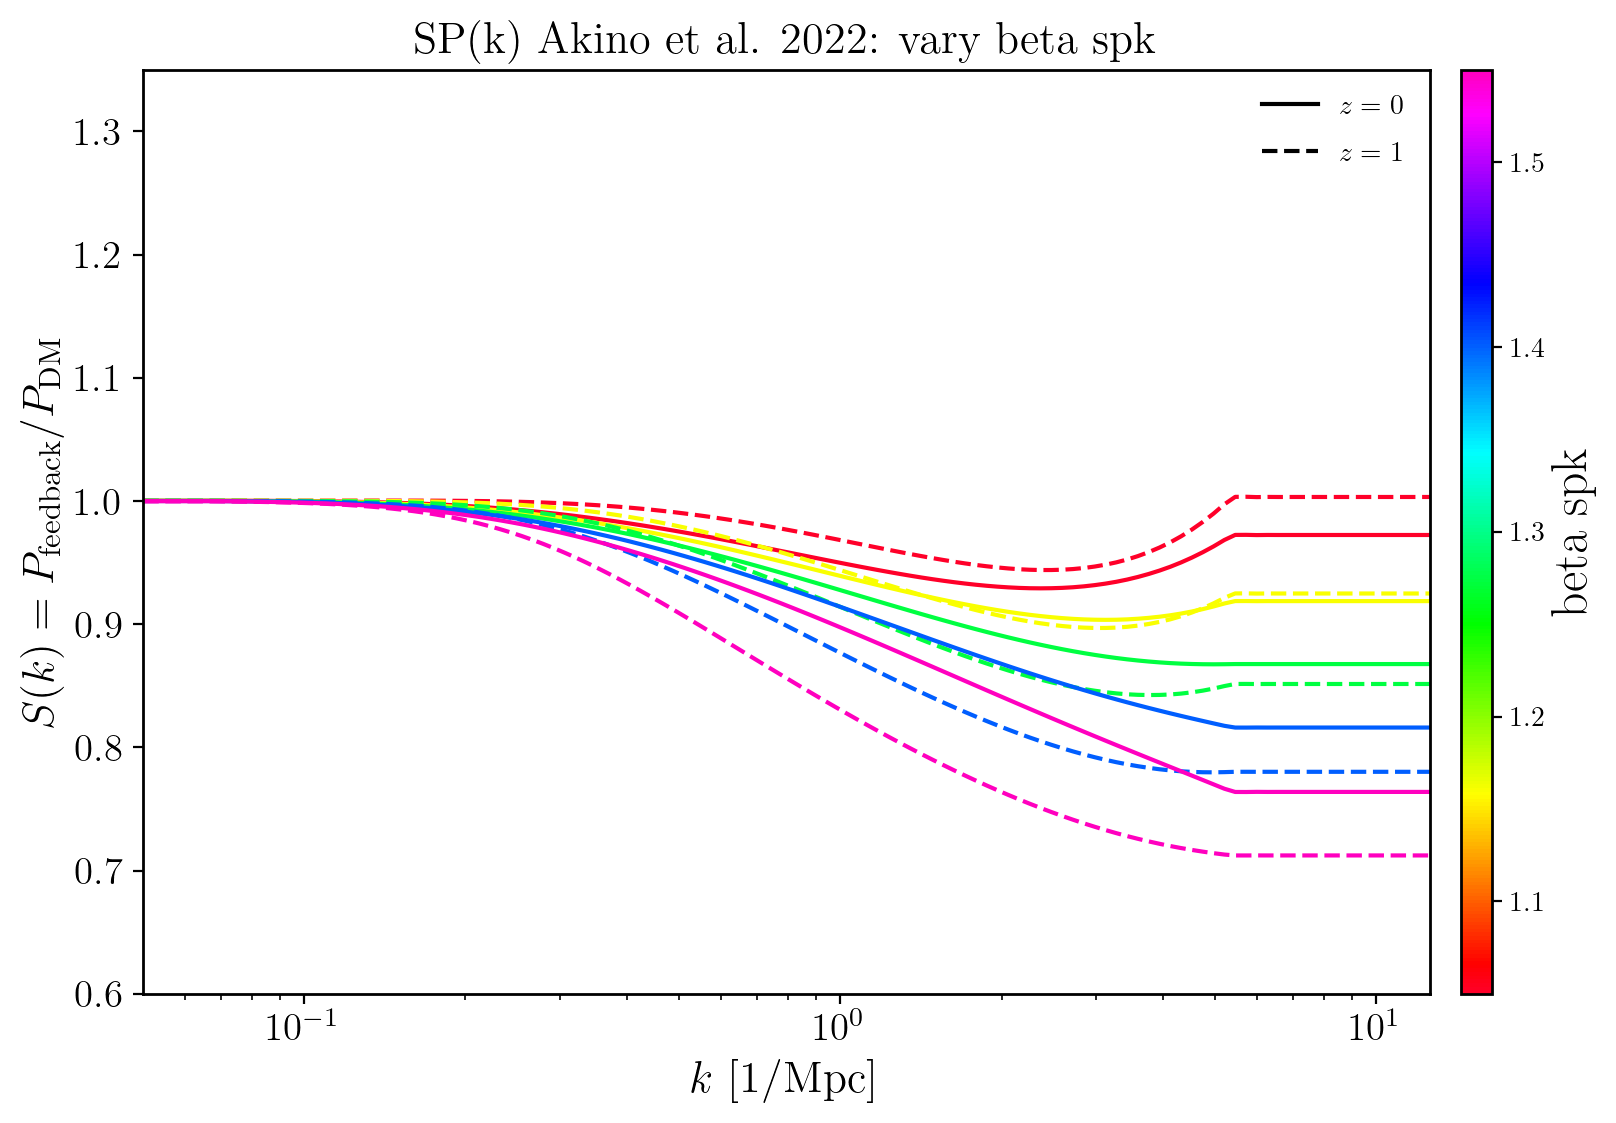

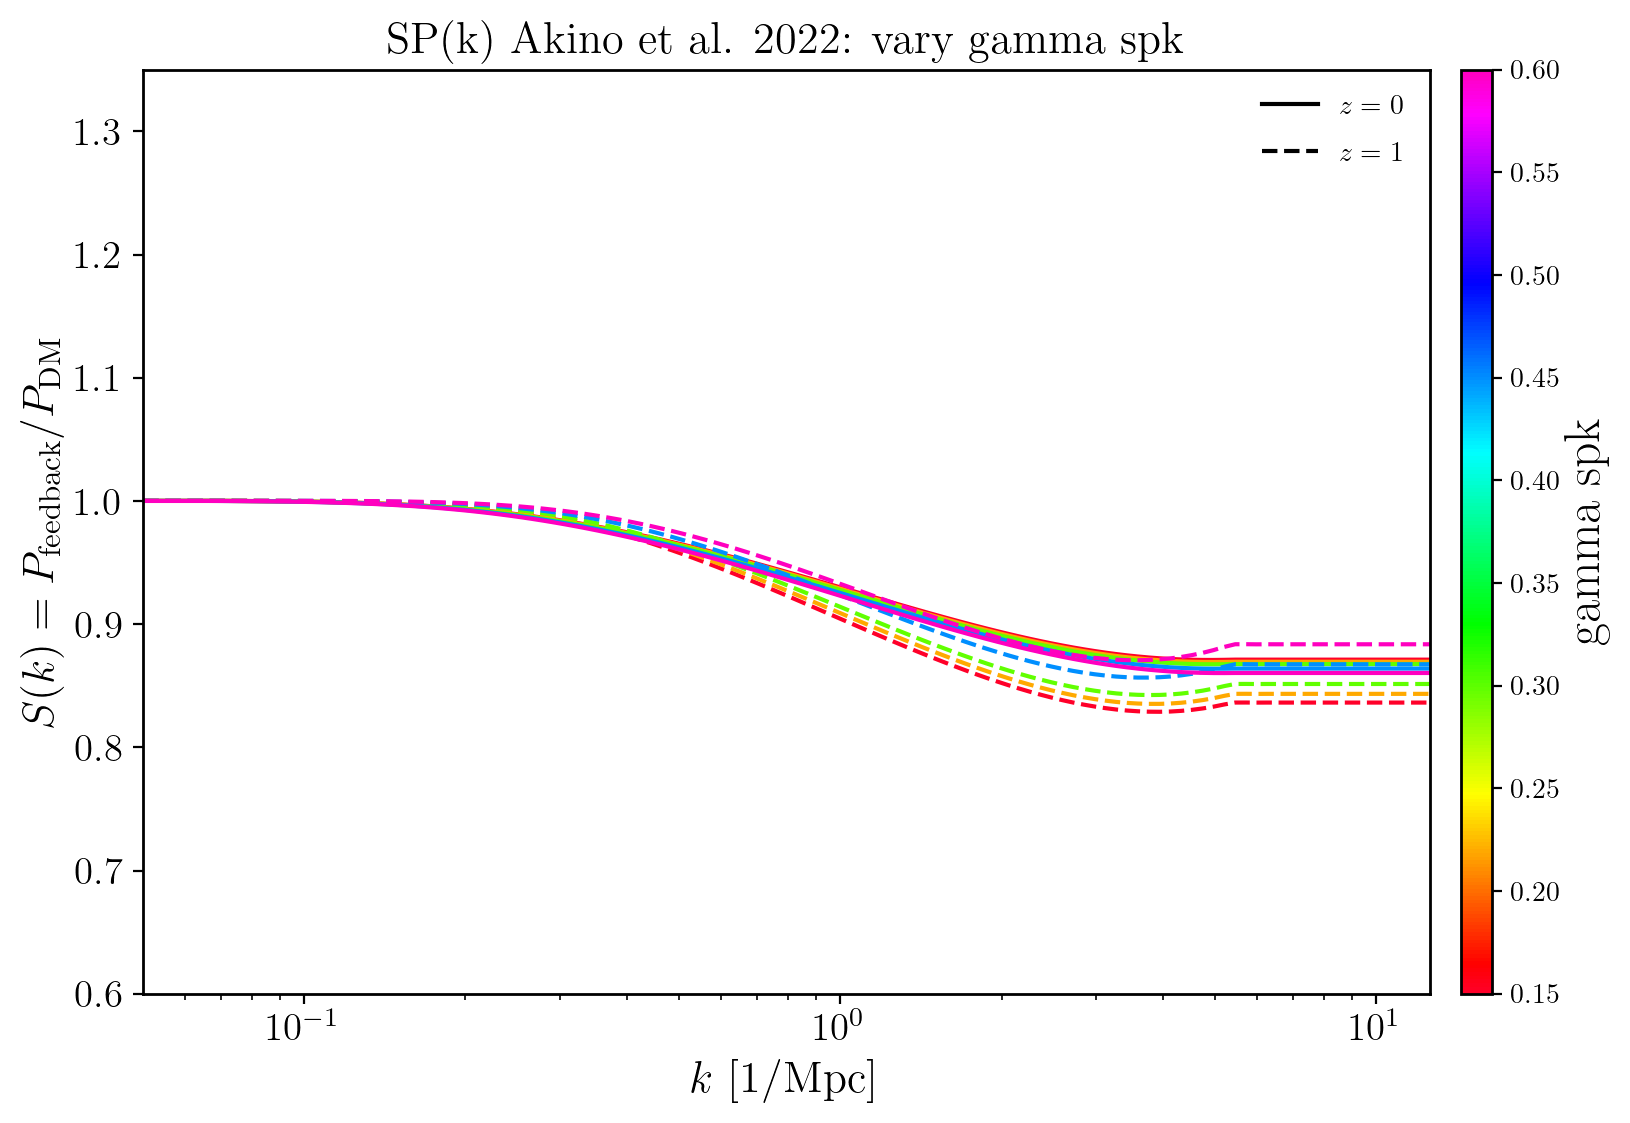

In [19]:
plot_sweeps("SP(k) Akino et al. 2022")

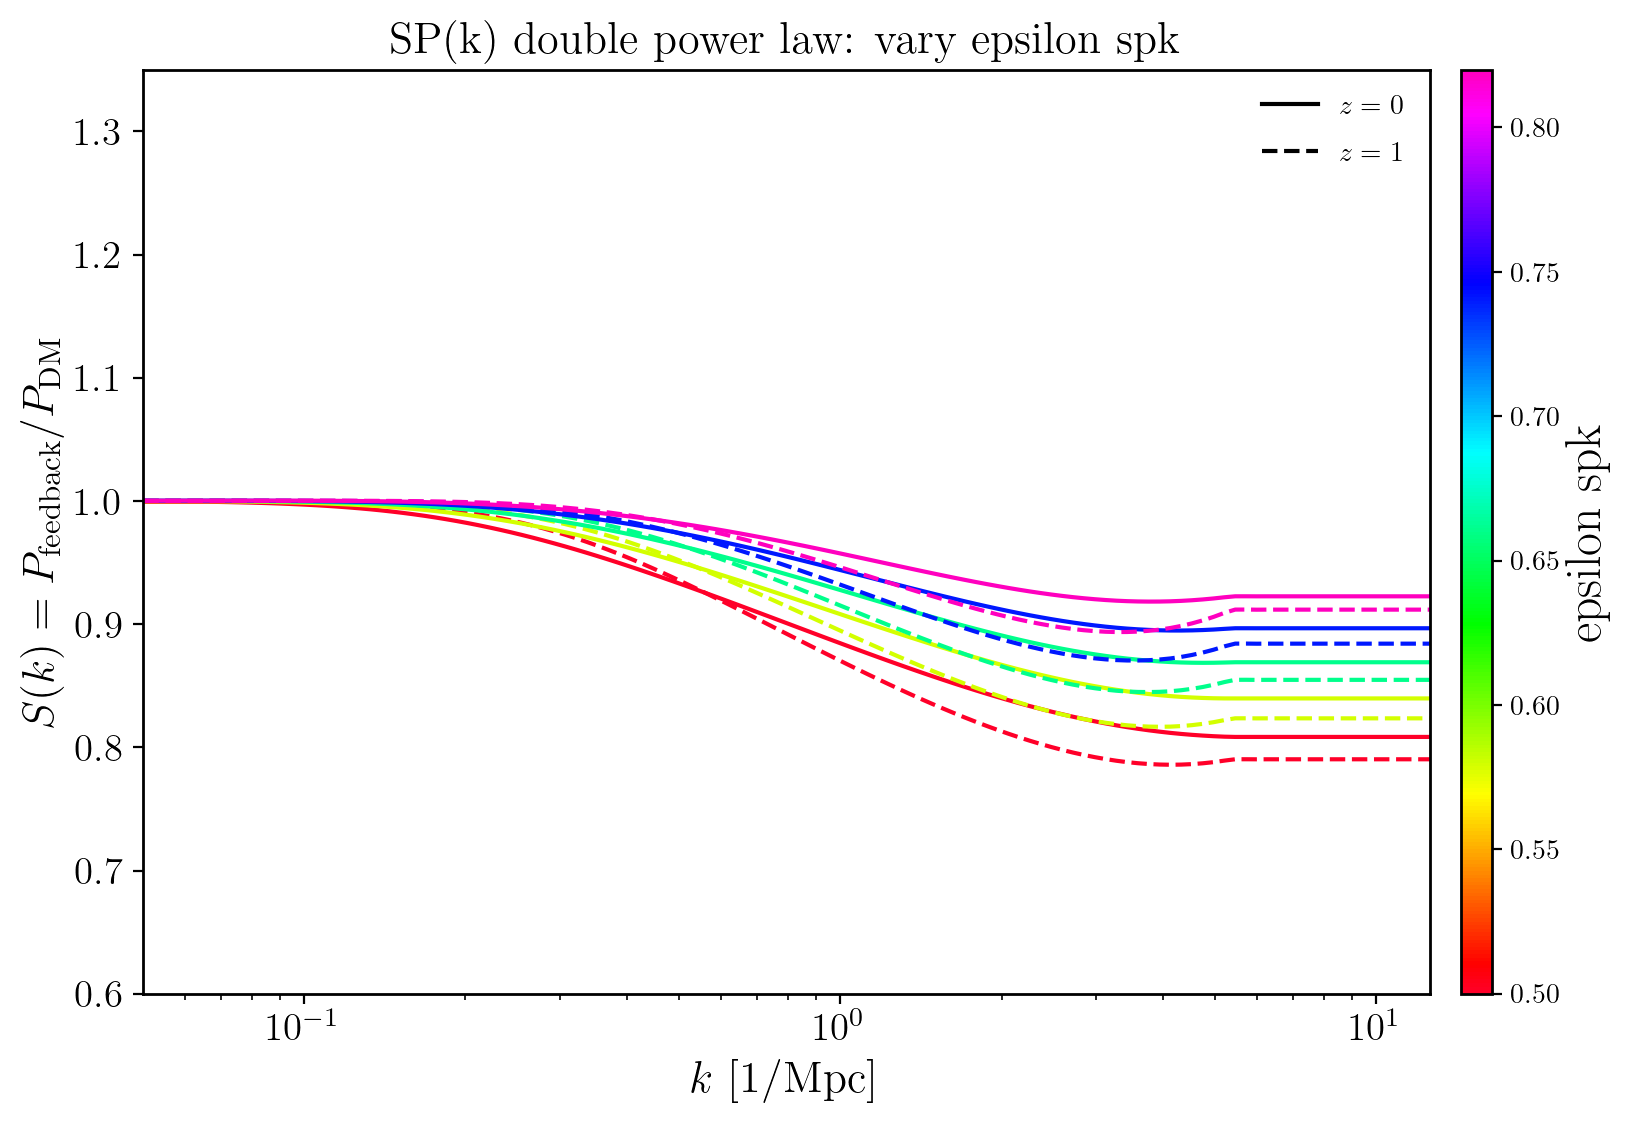

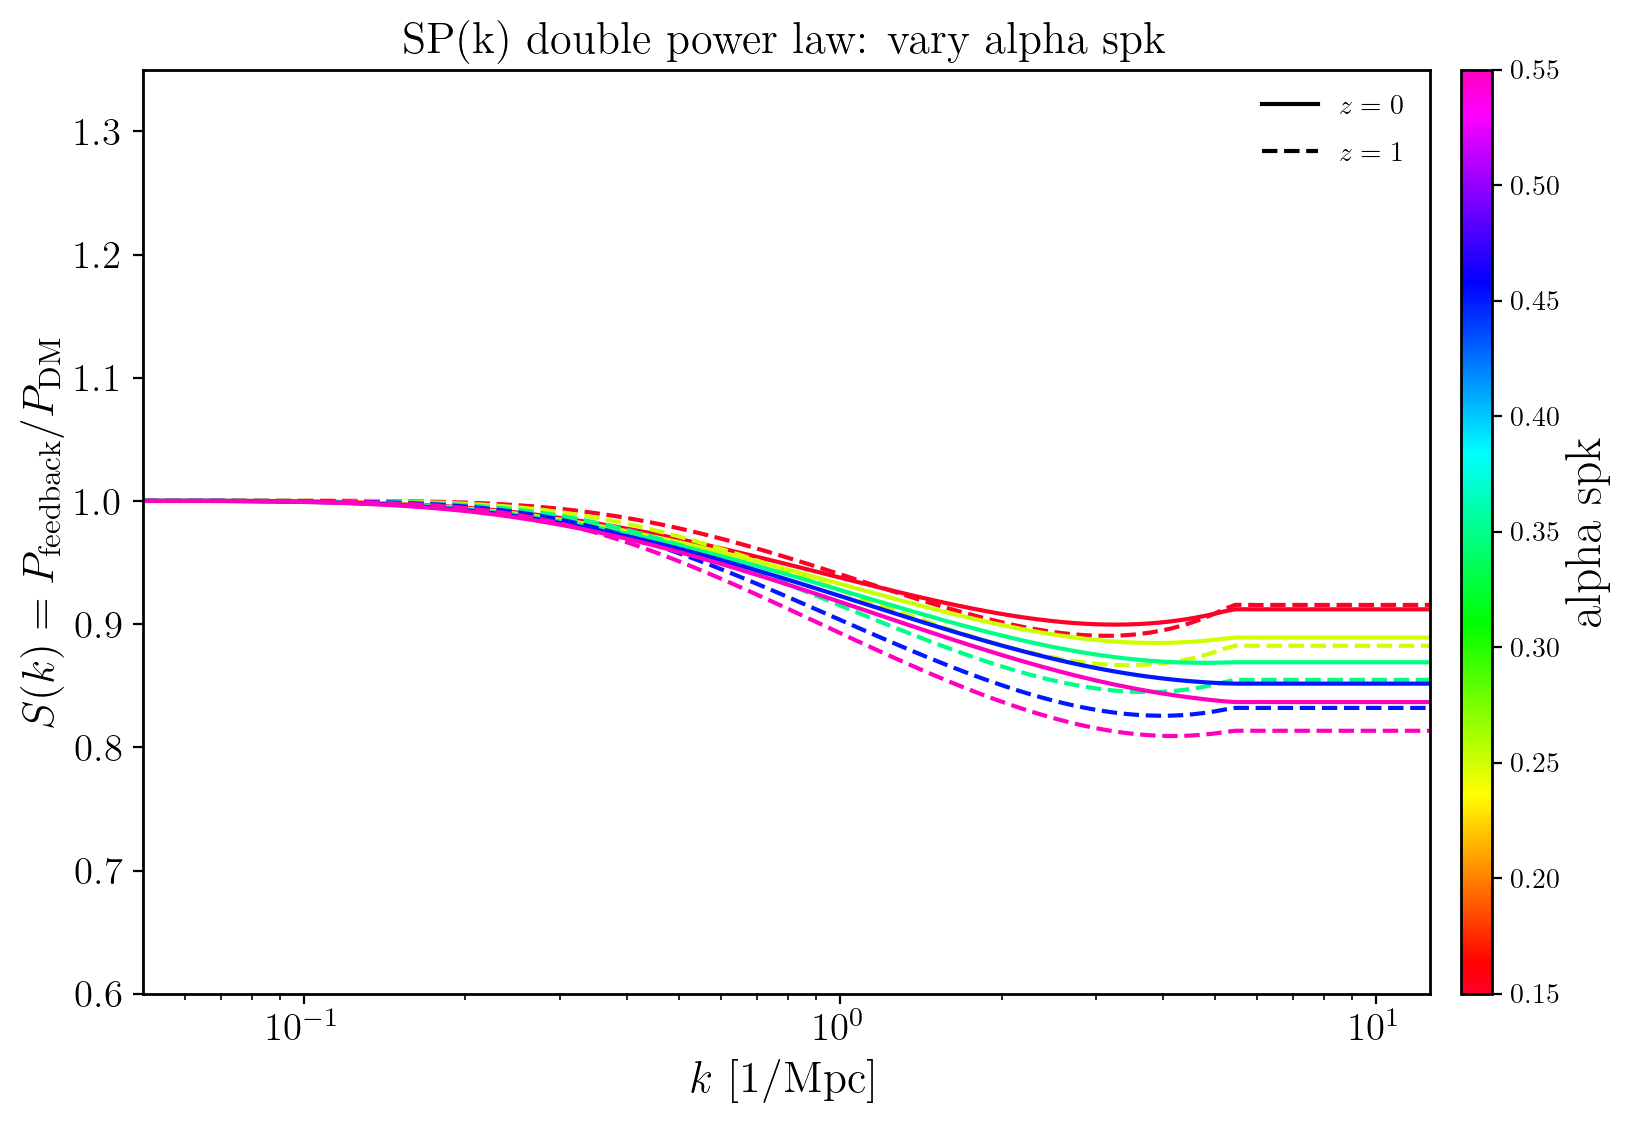

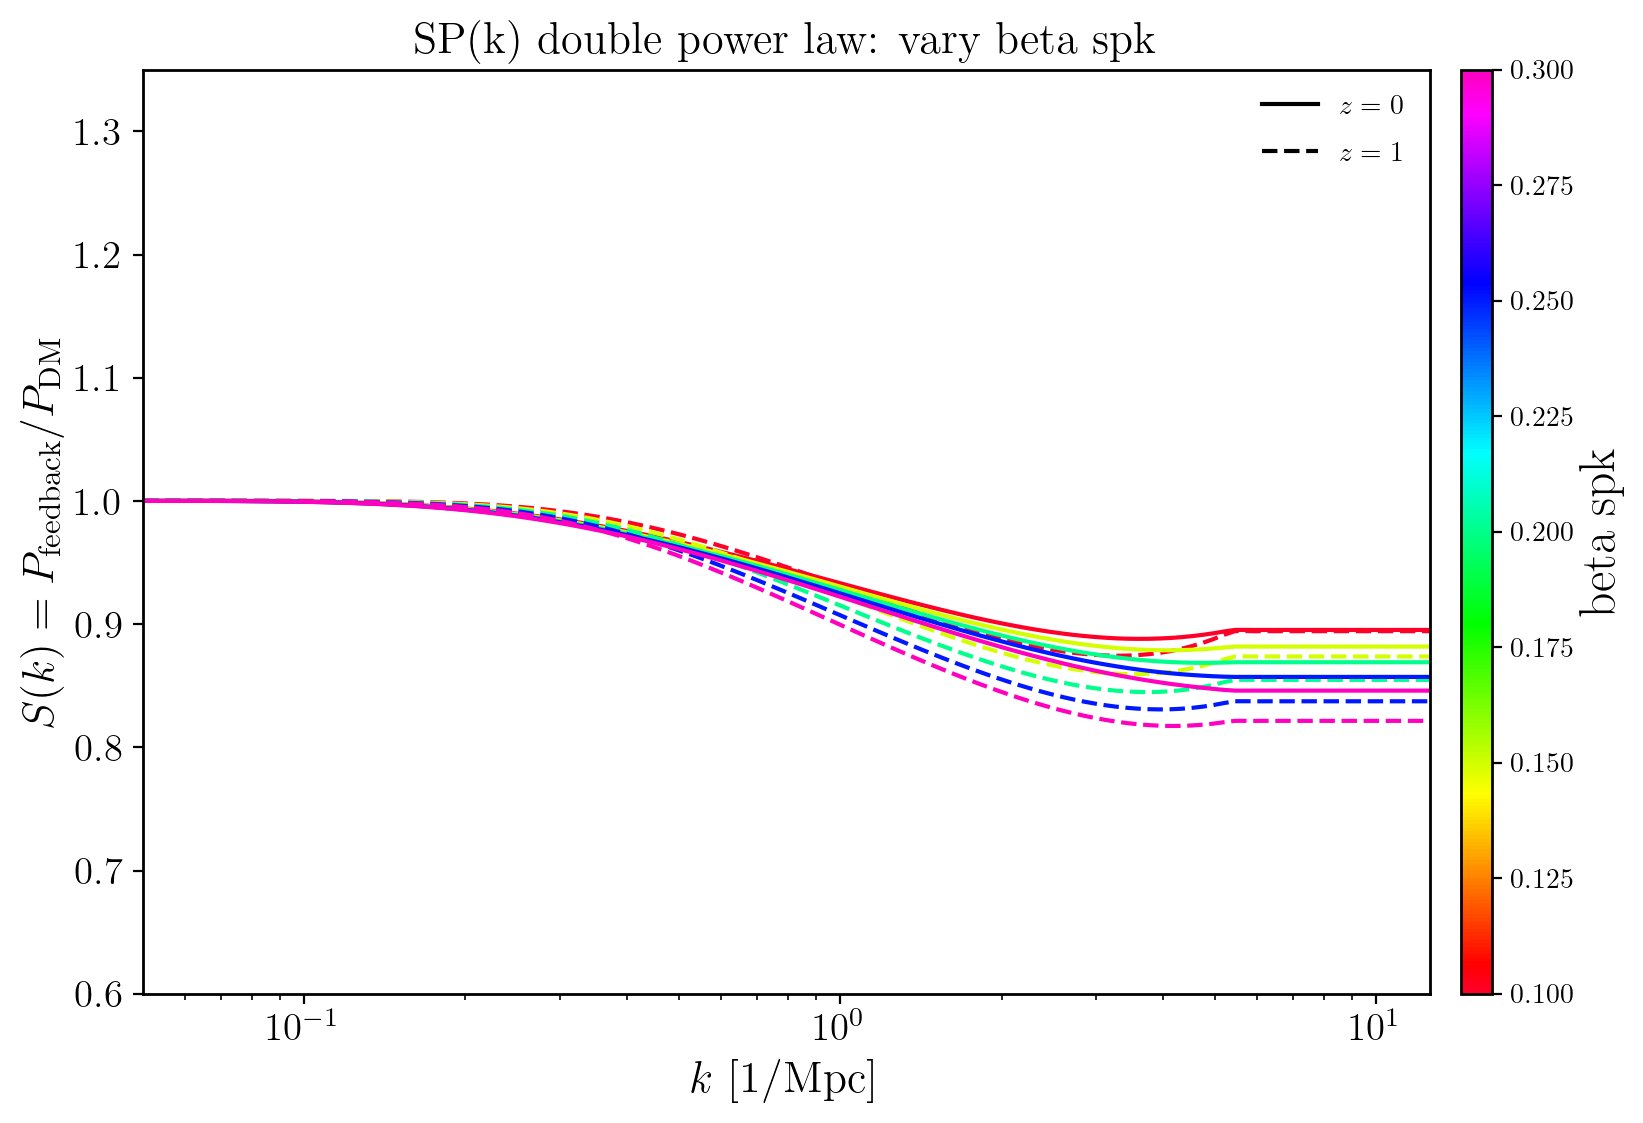

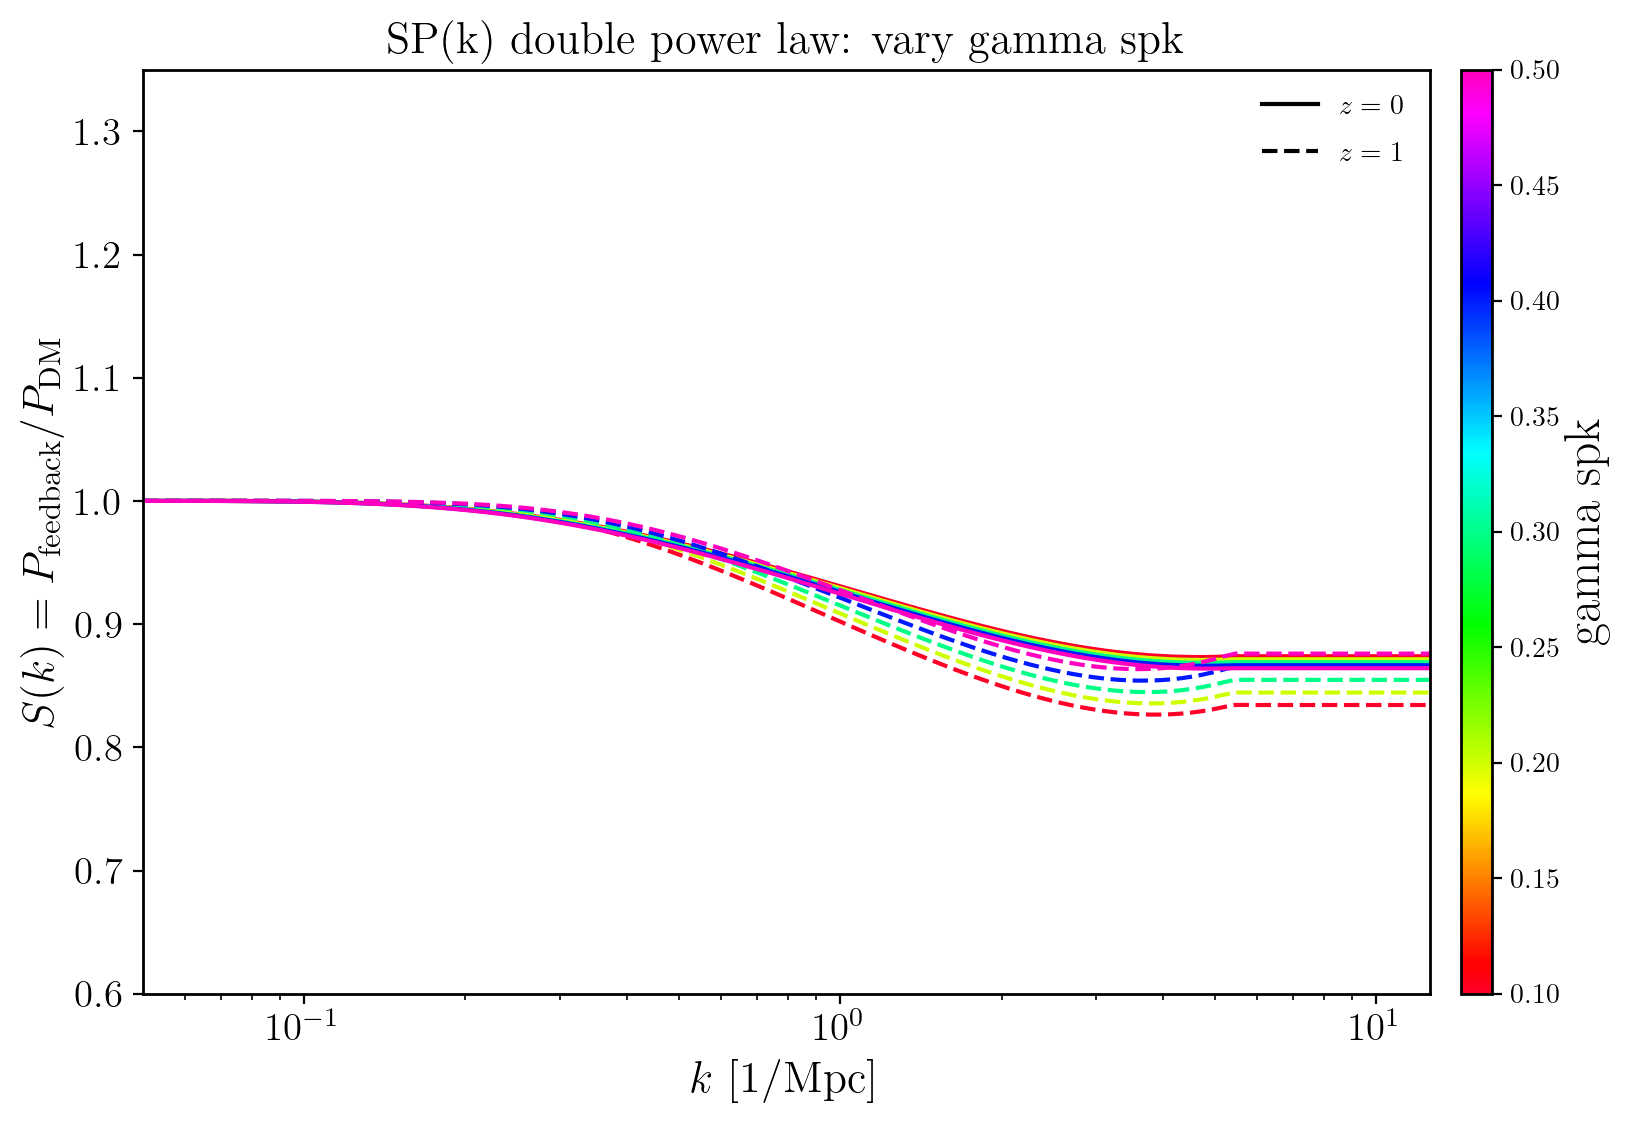

In [20]:
plot_sweeps("SP(k) double power law")

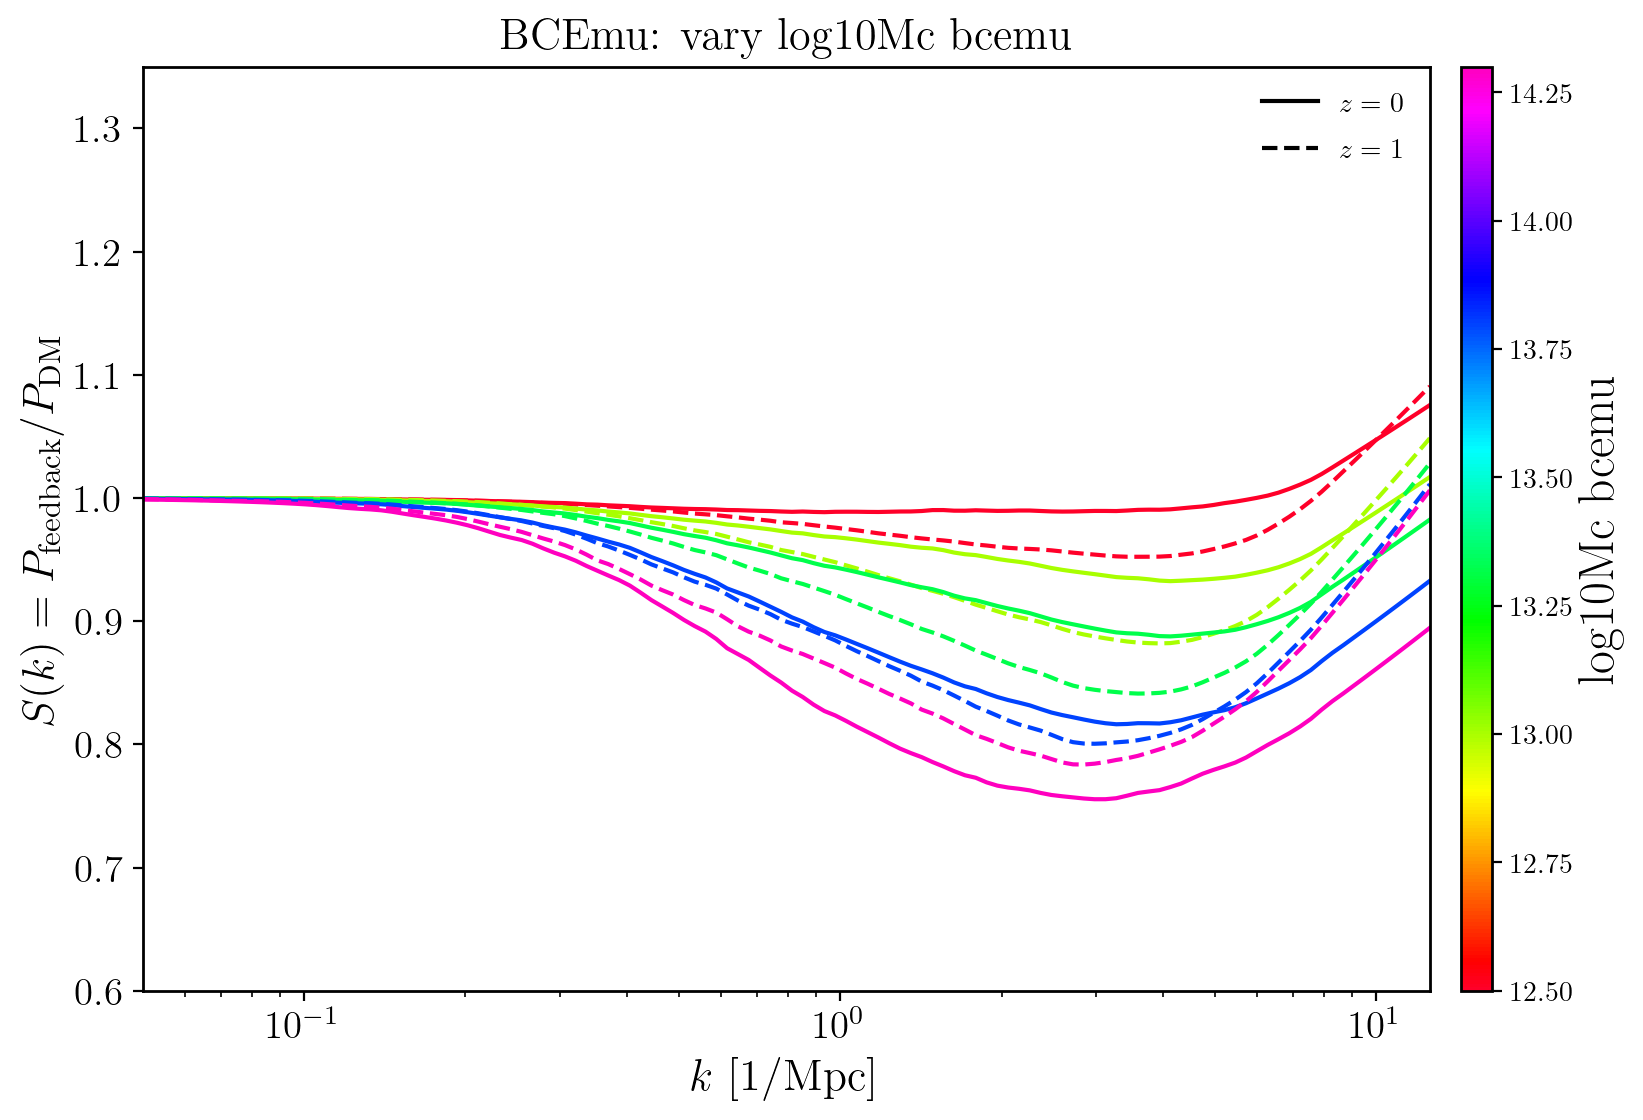

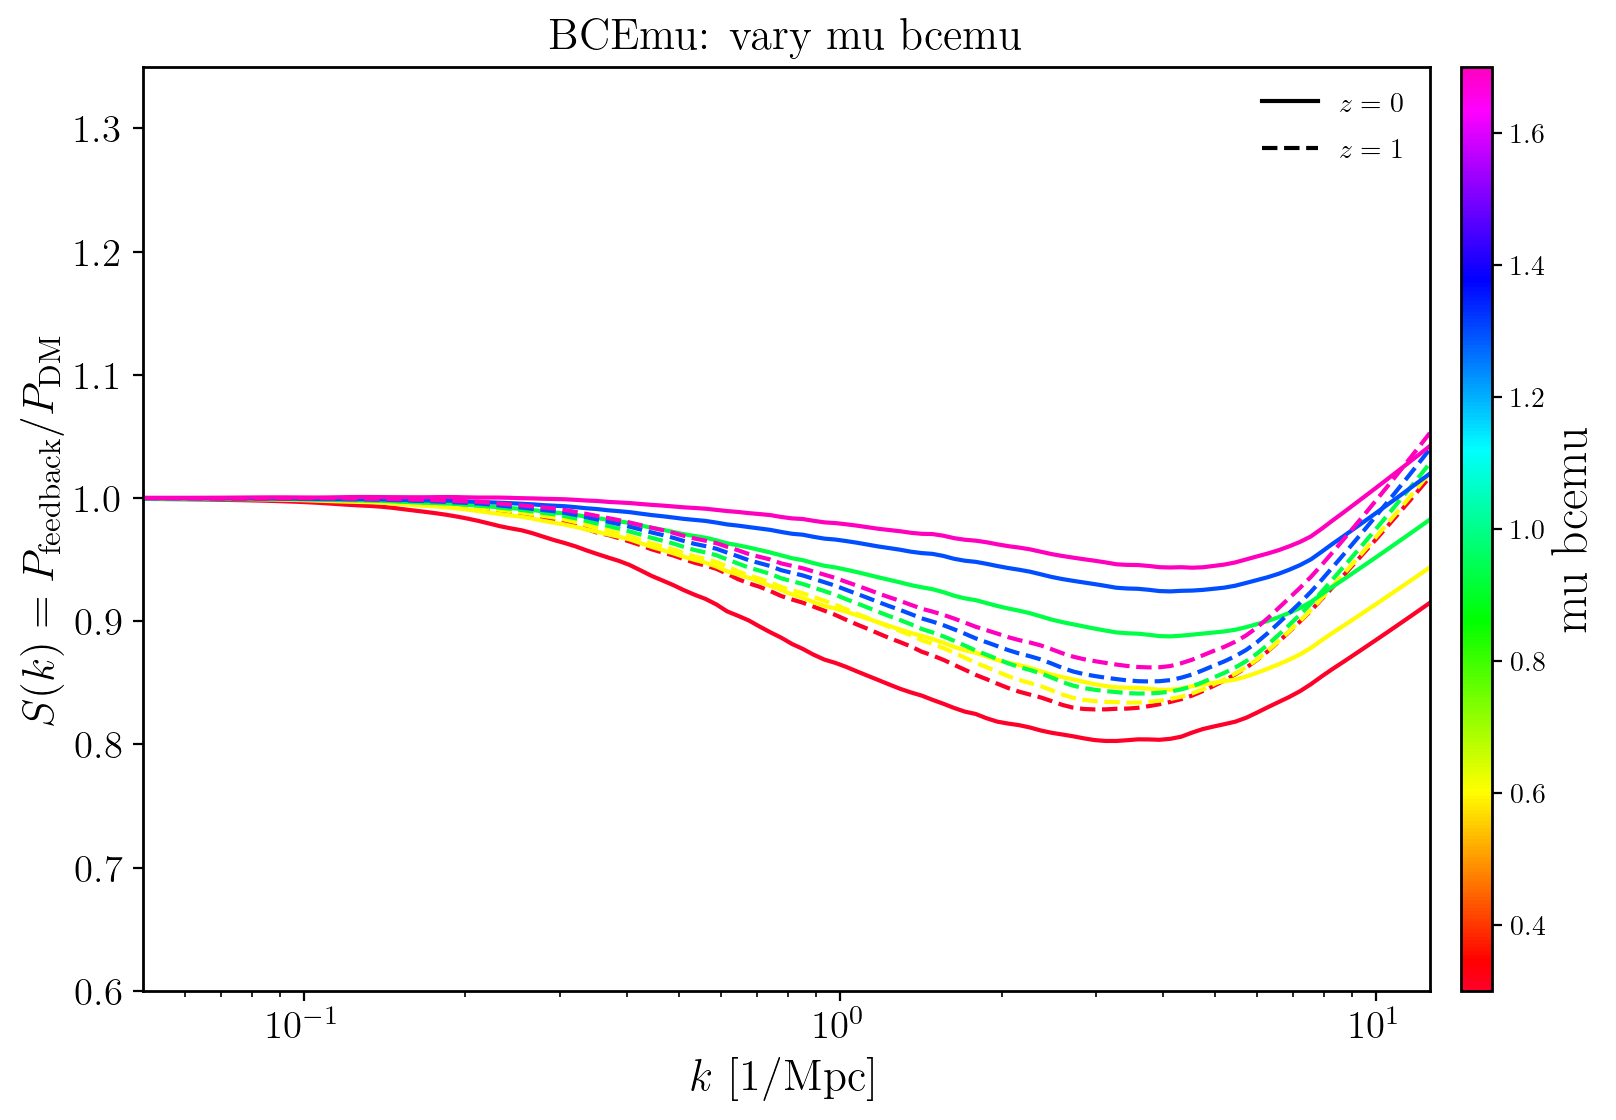

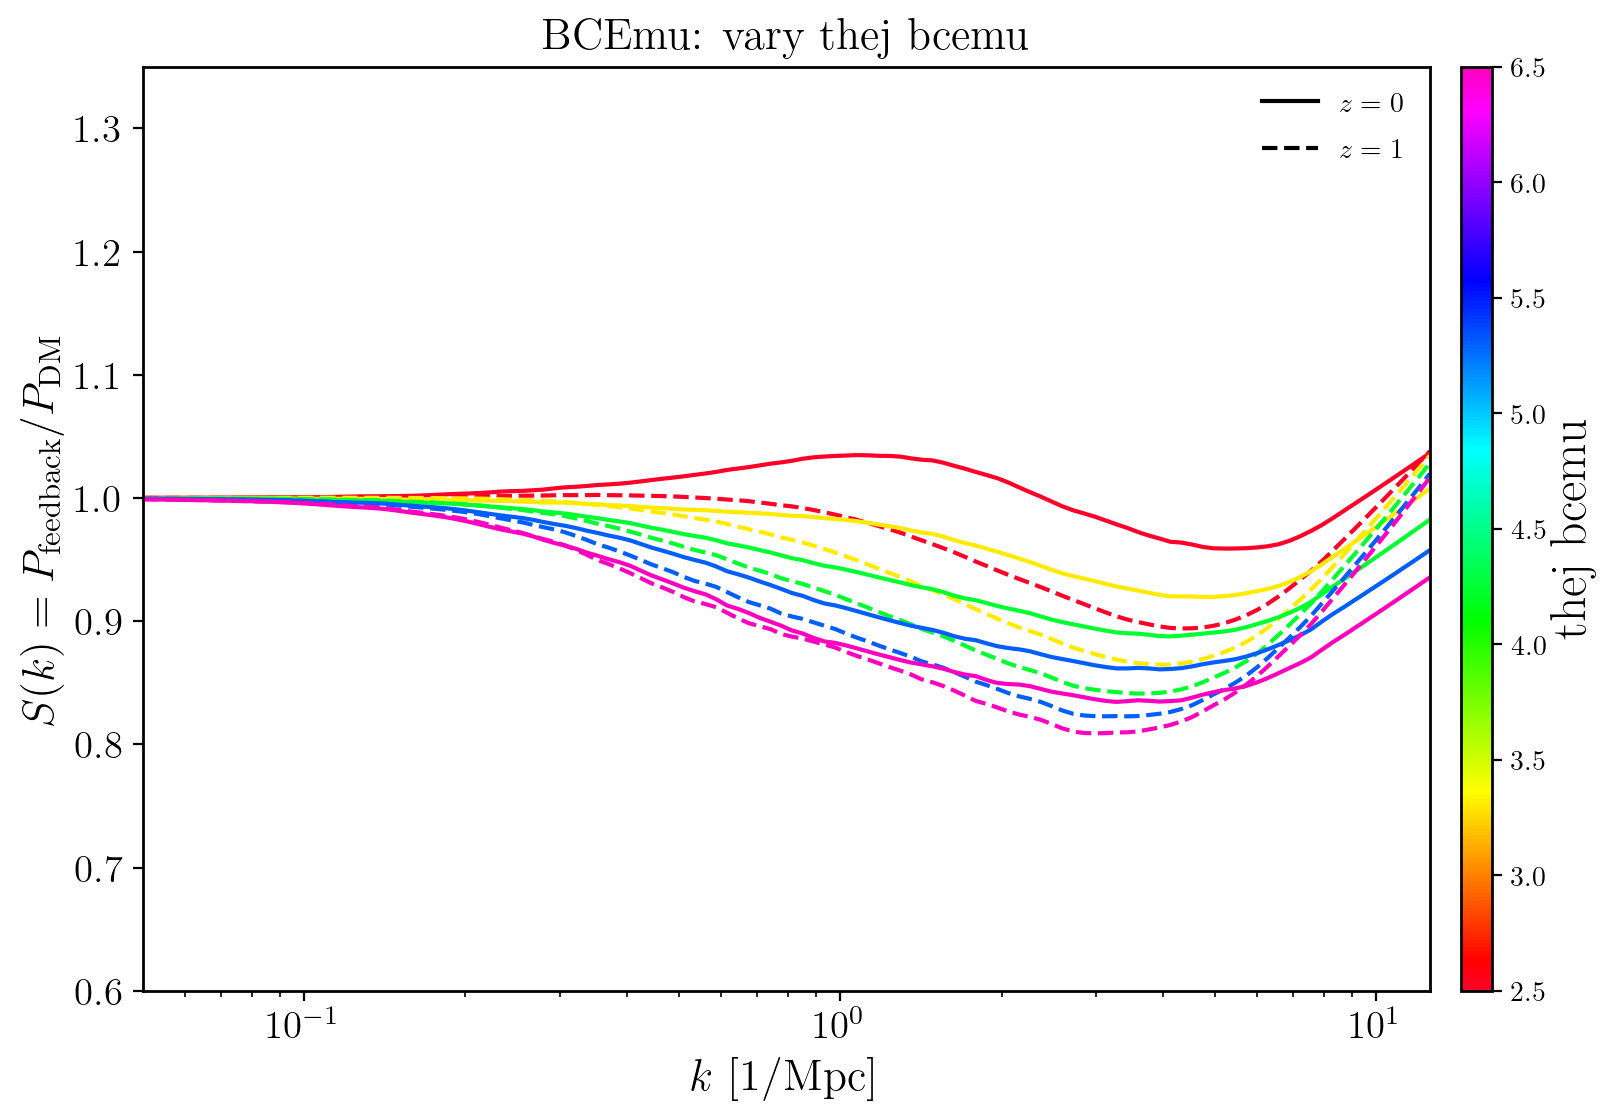

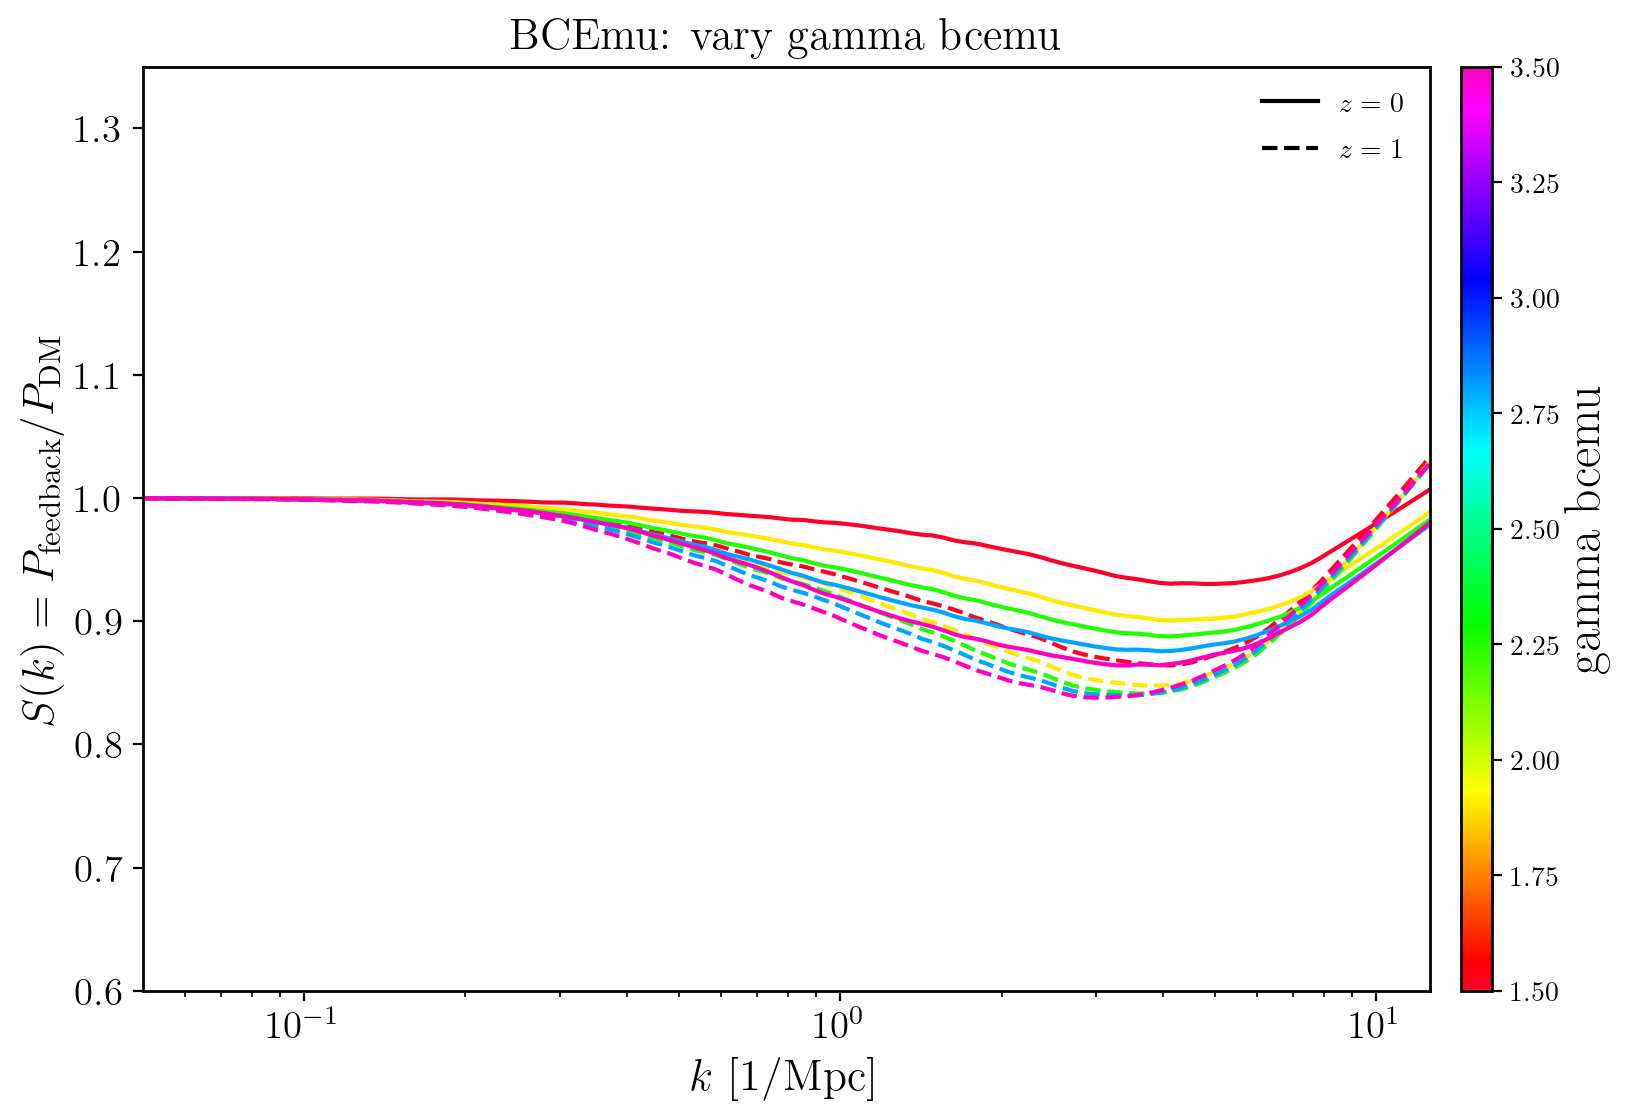

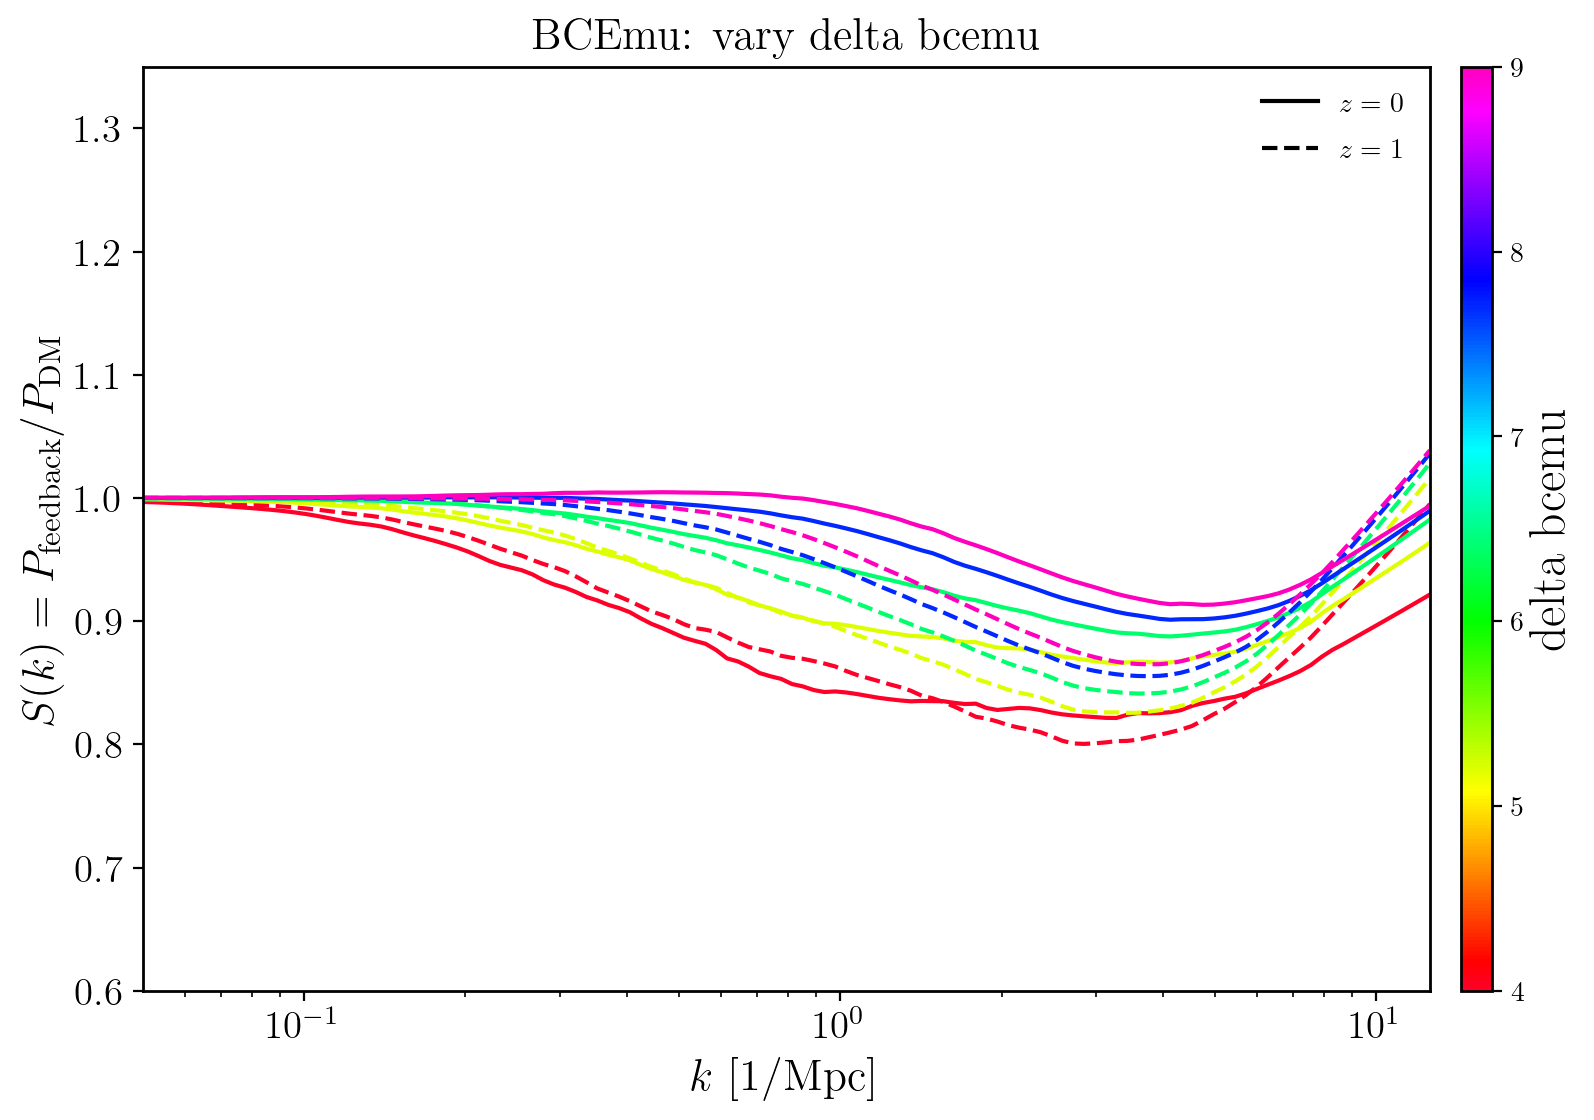

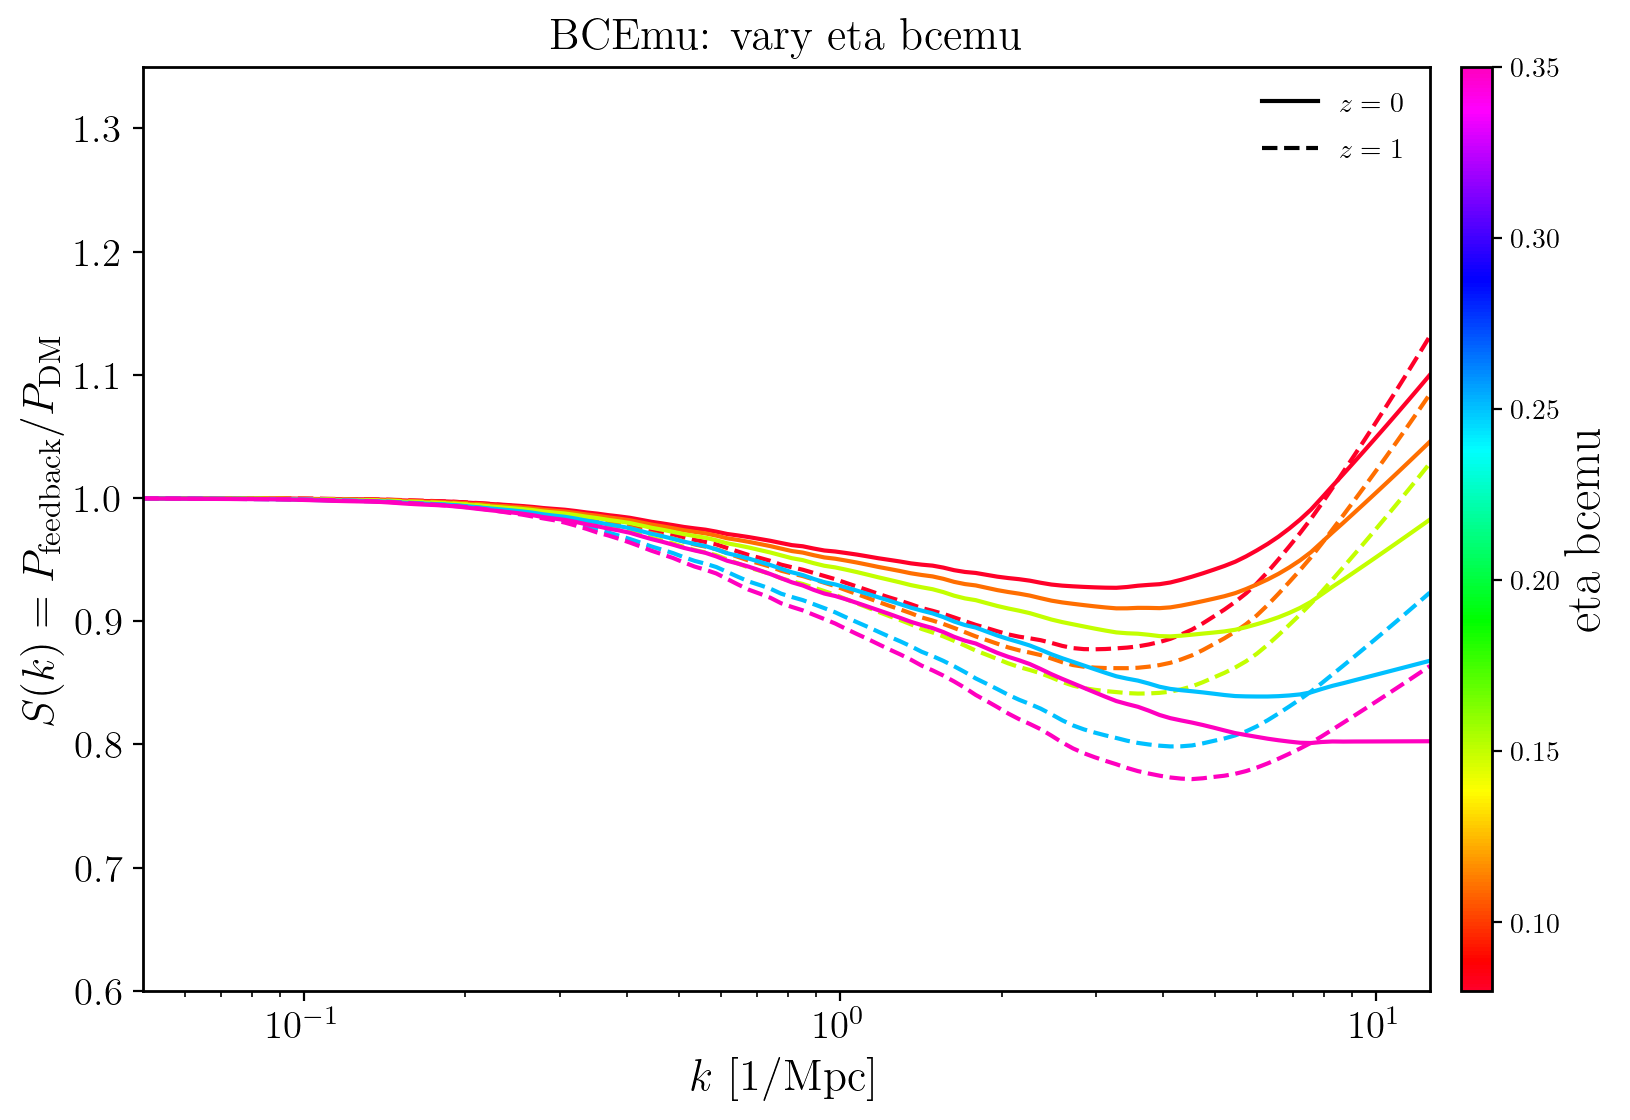

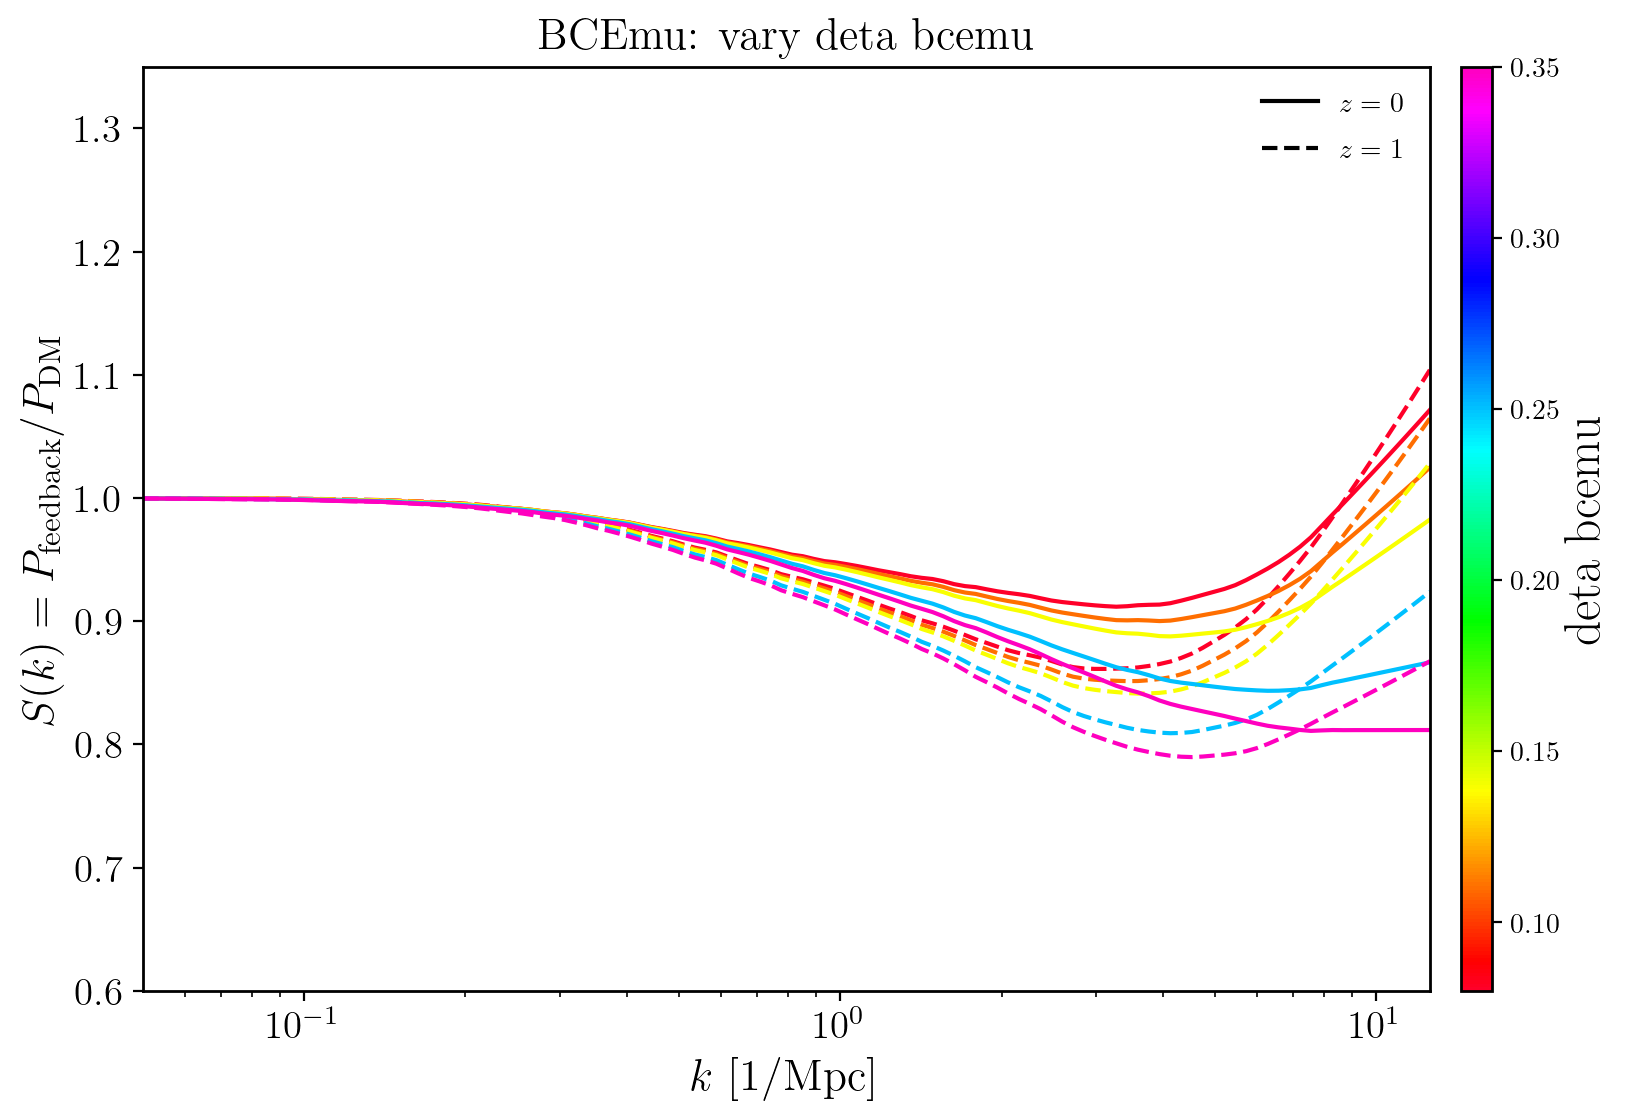

In [21]:
plot_sweeps("BCEmu")

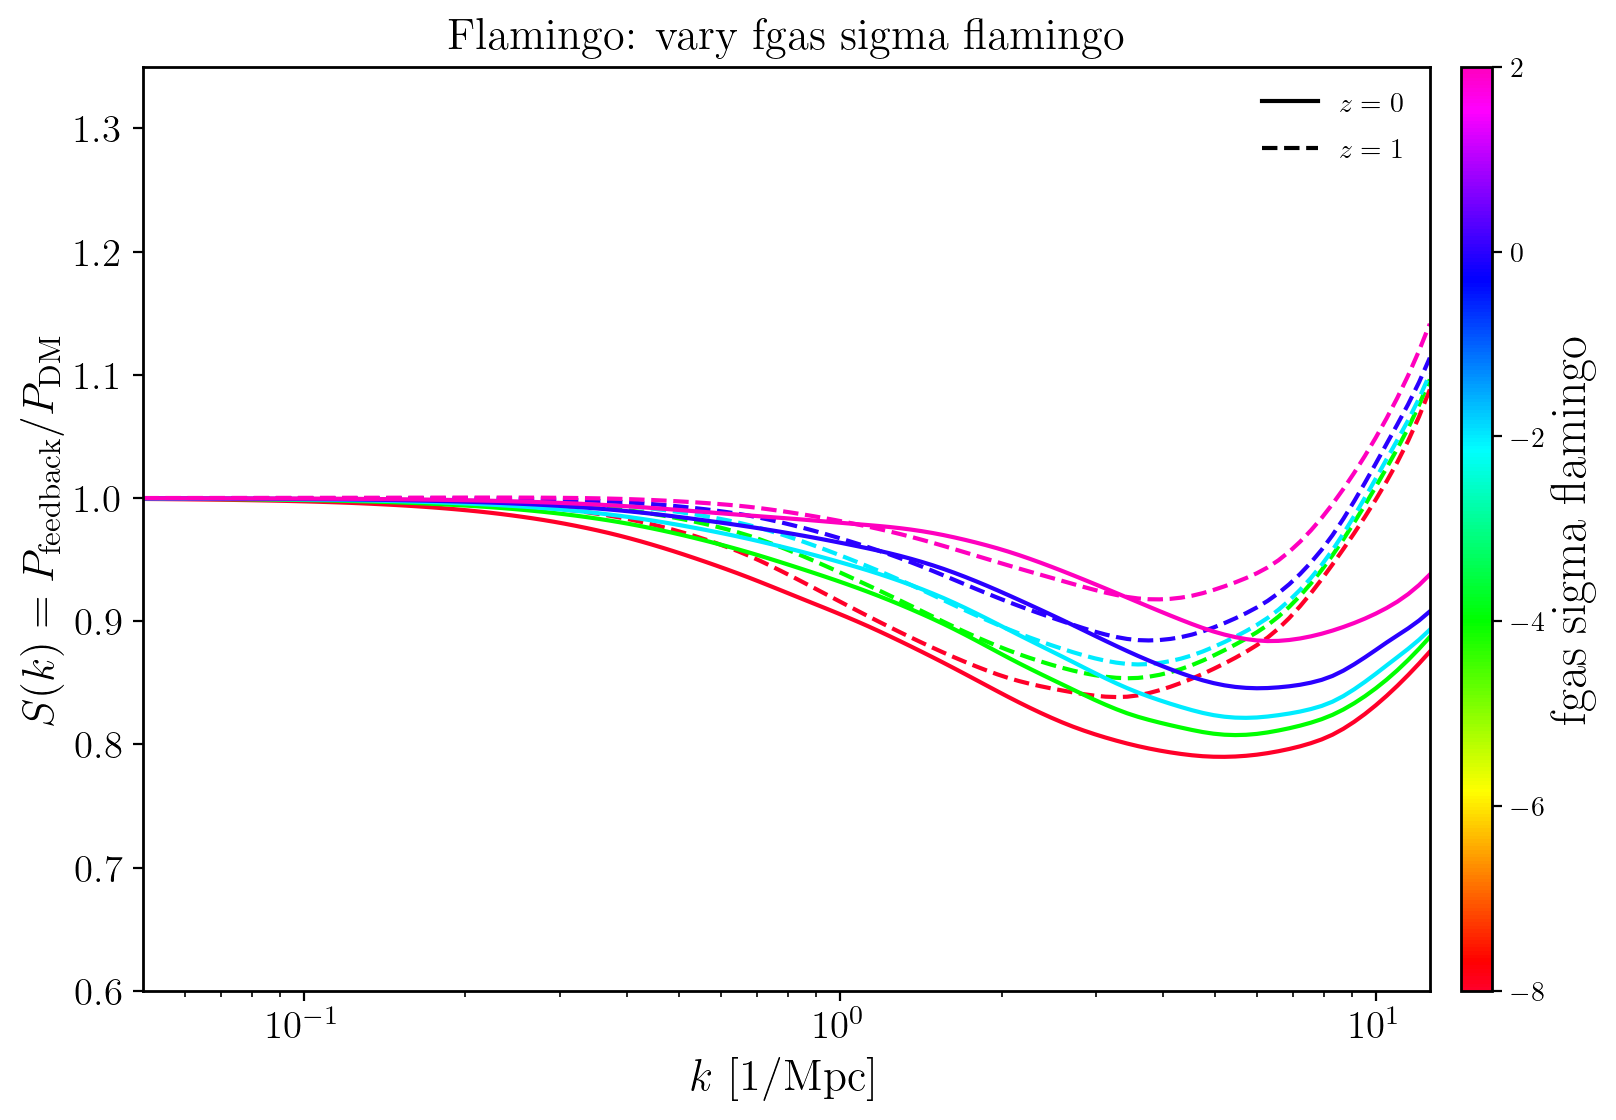

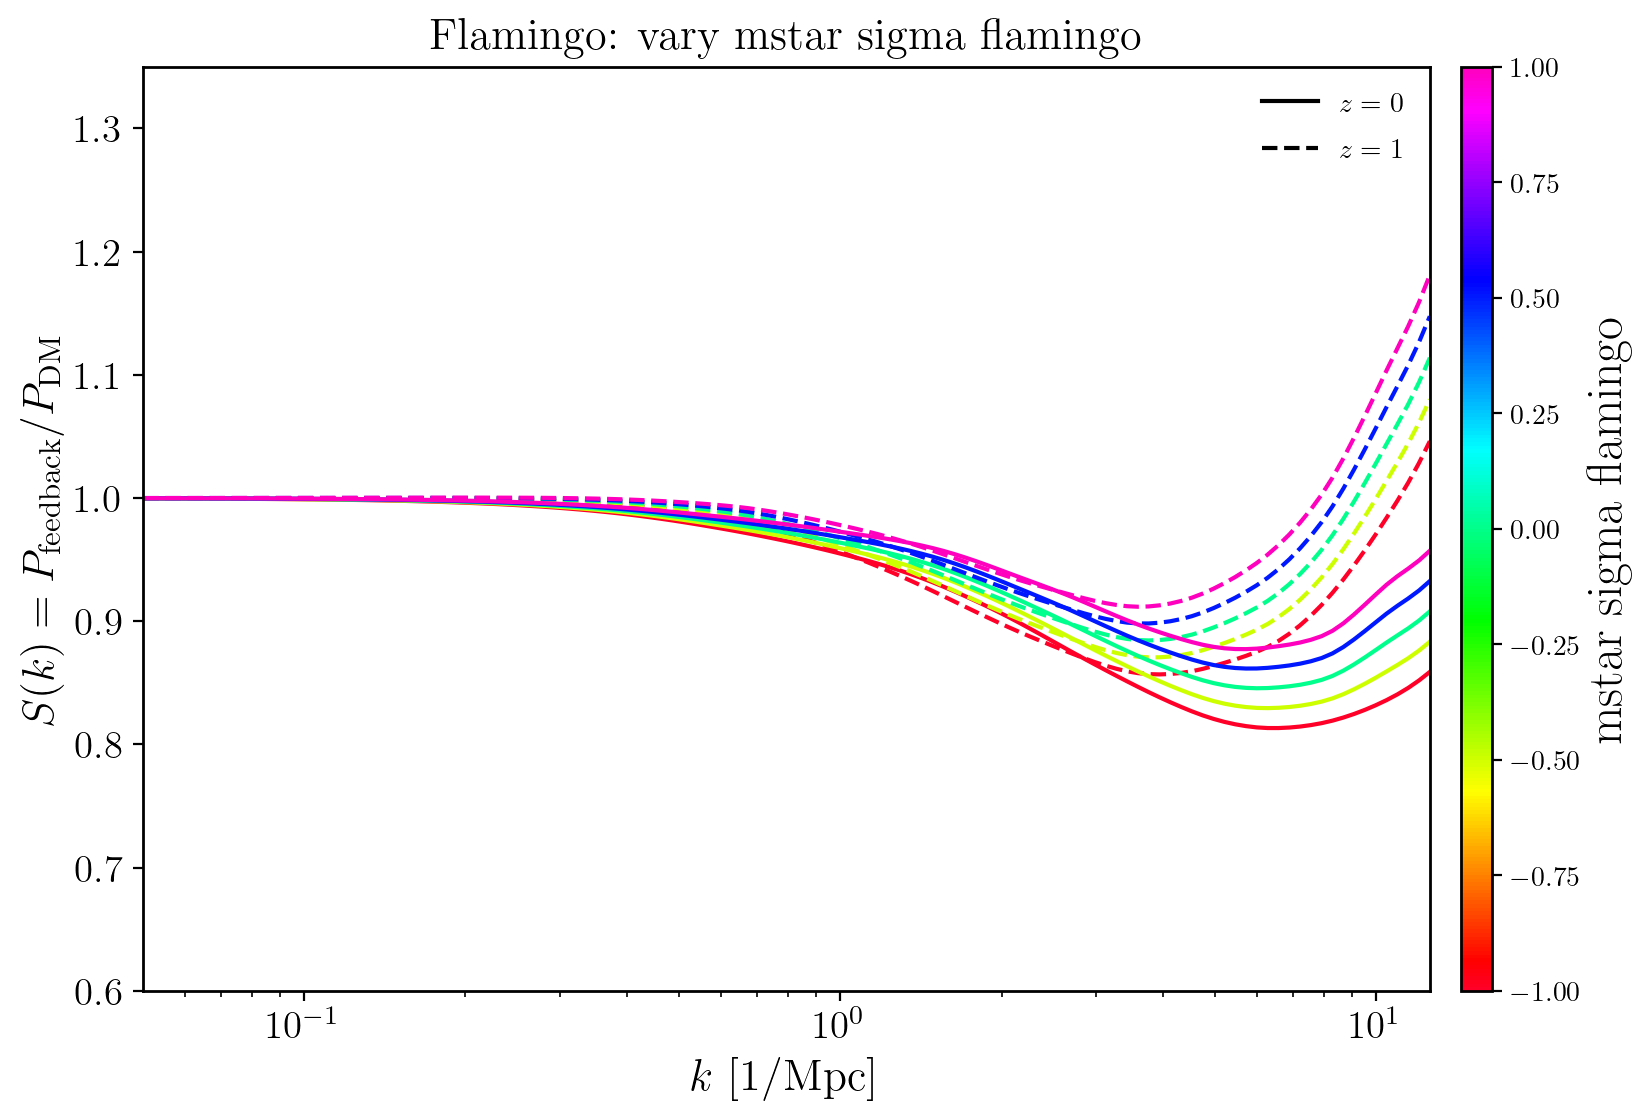

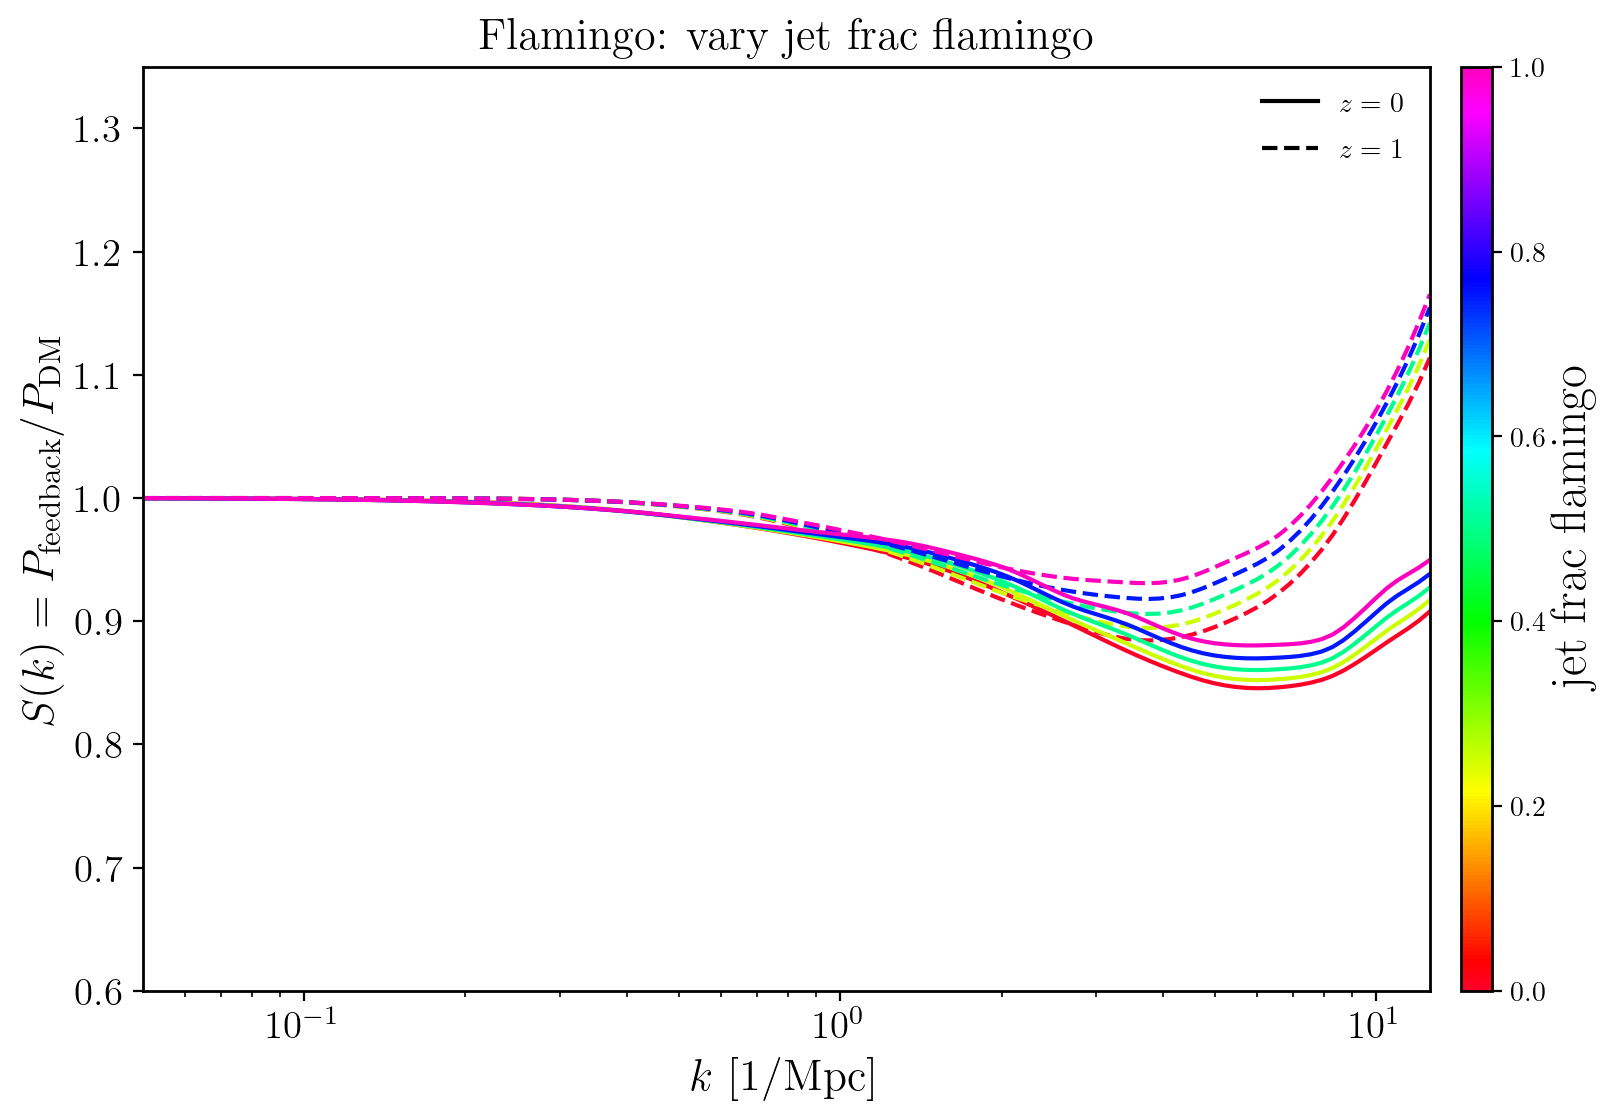

In [22]:
plot_sweeps("Flamingo")

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

... (25 outputs left out)

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

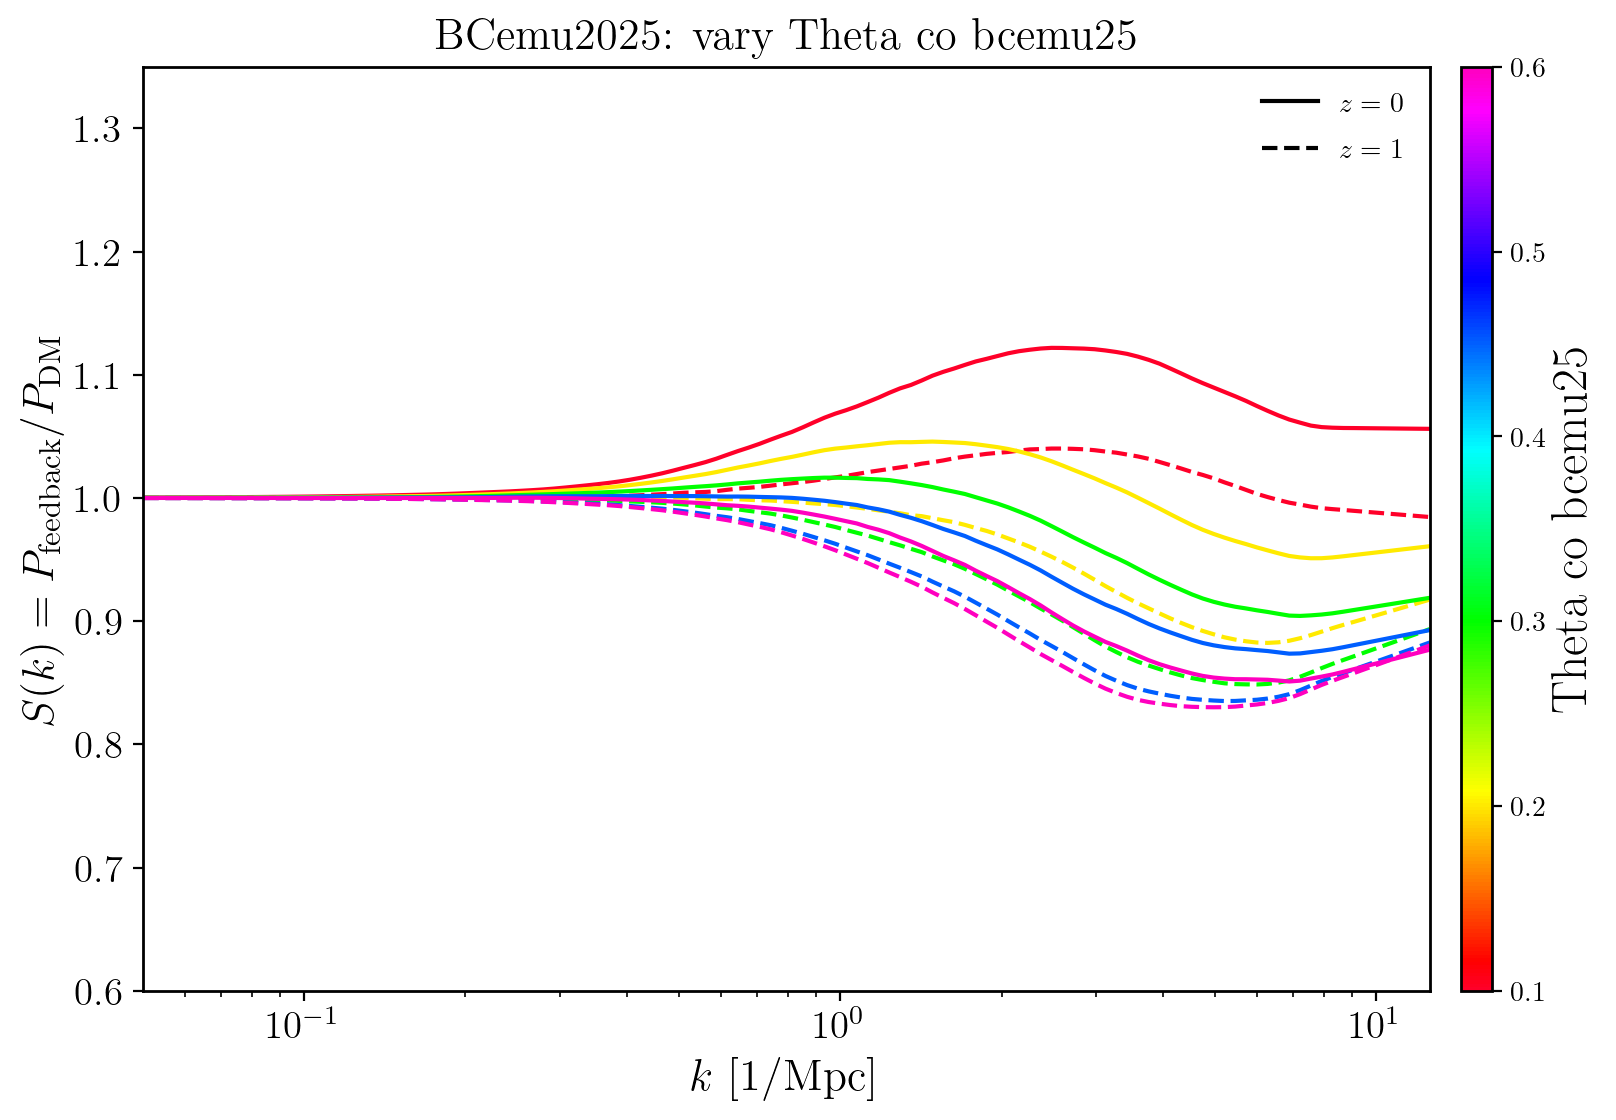

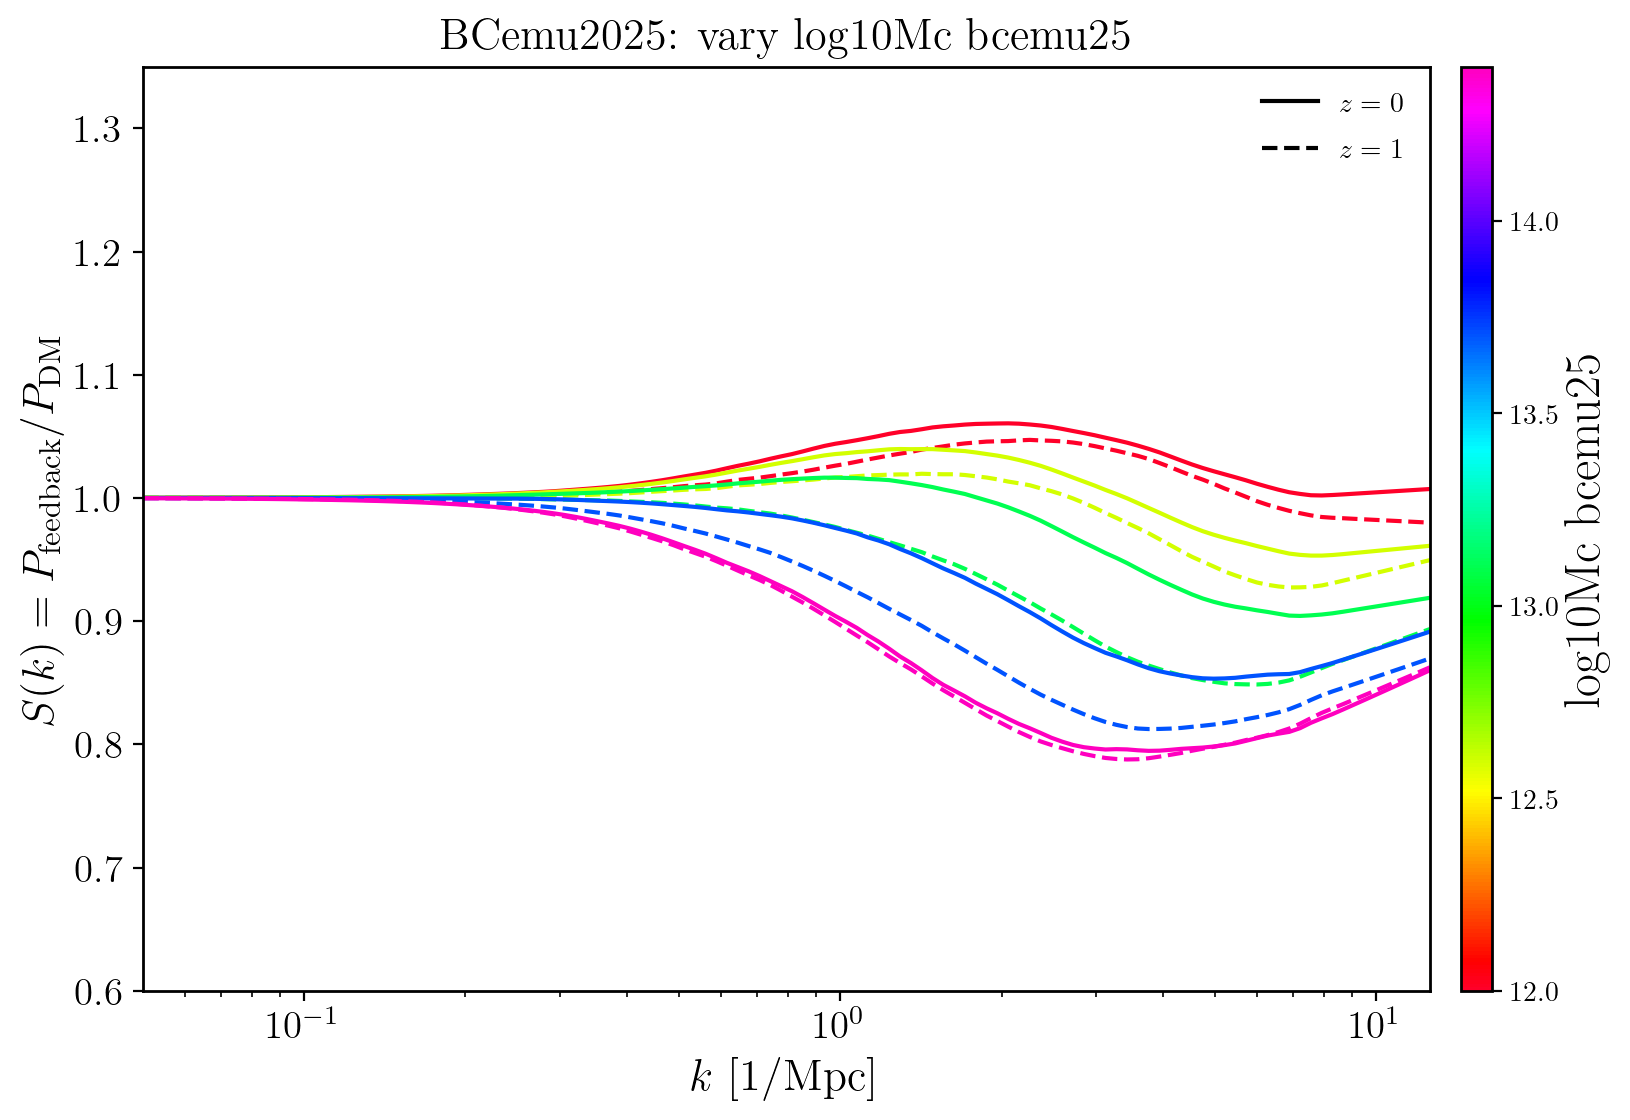

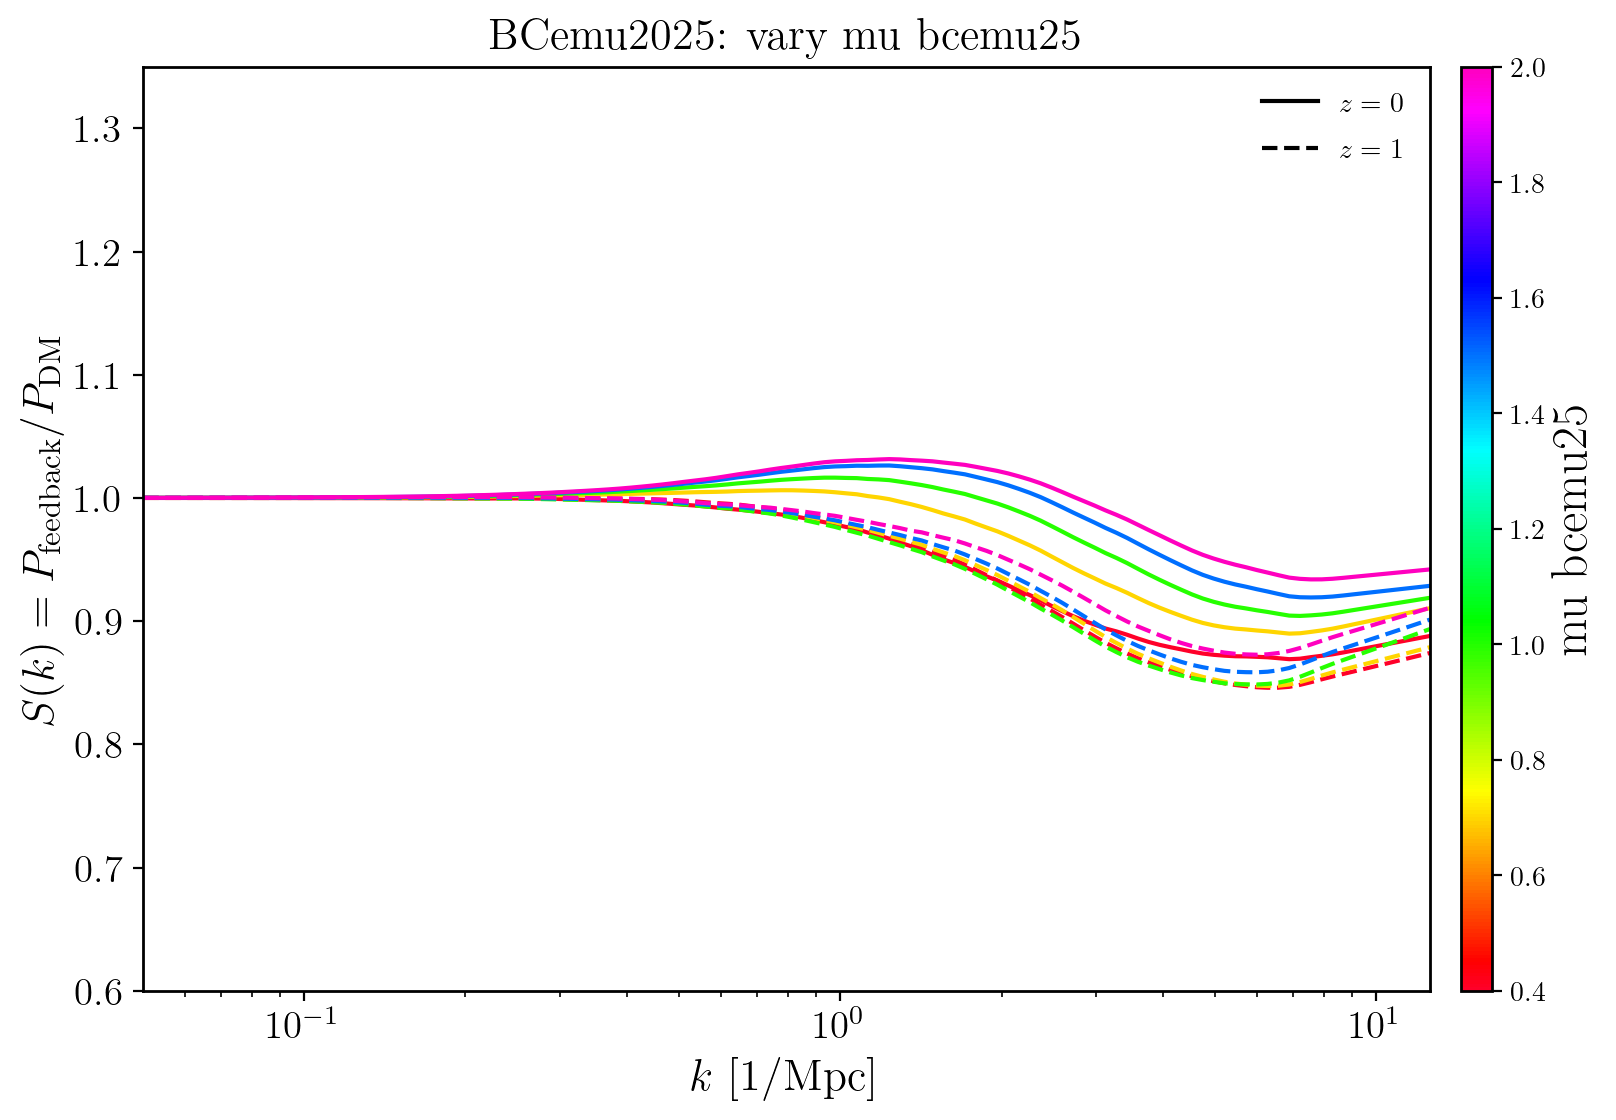

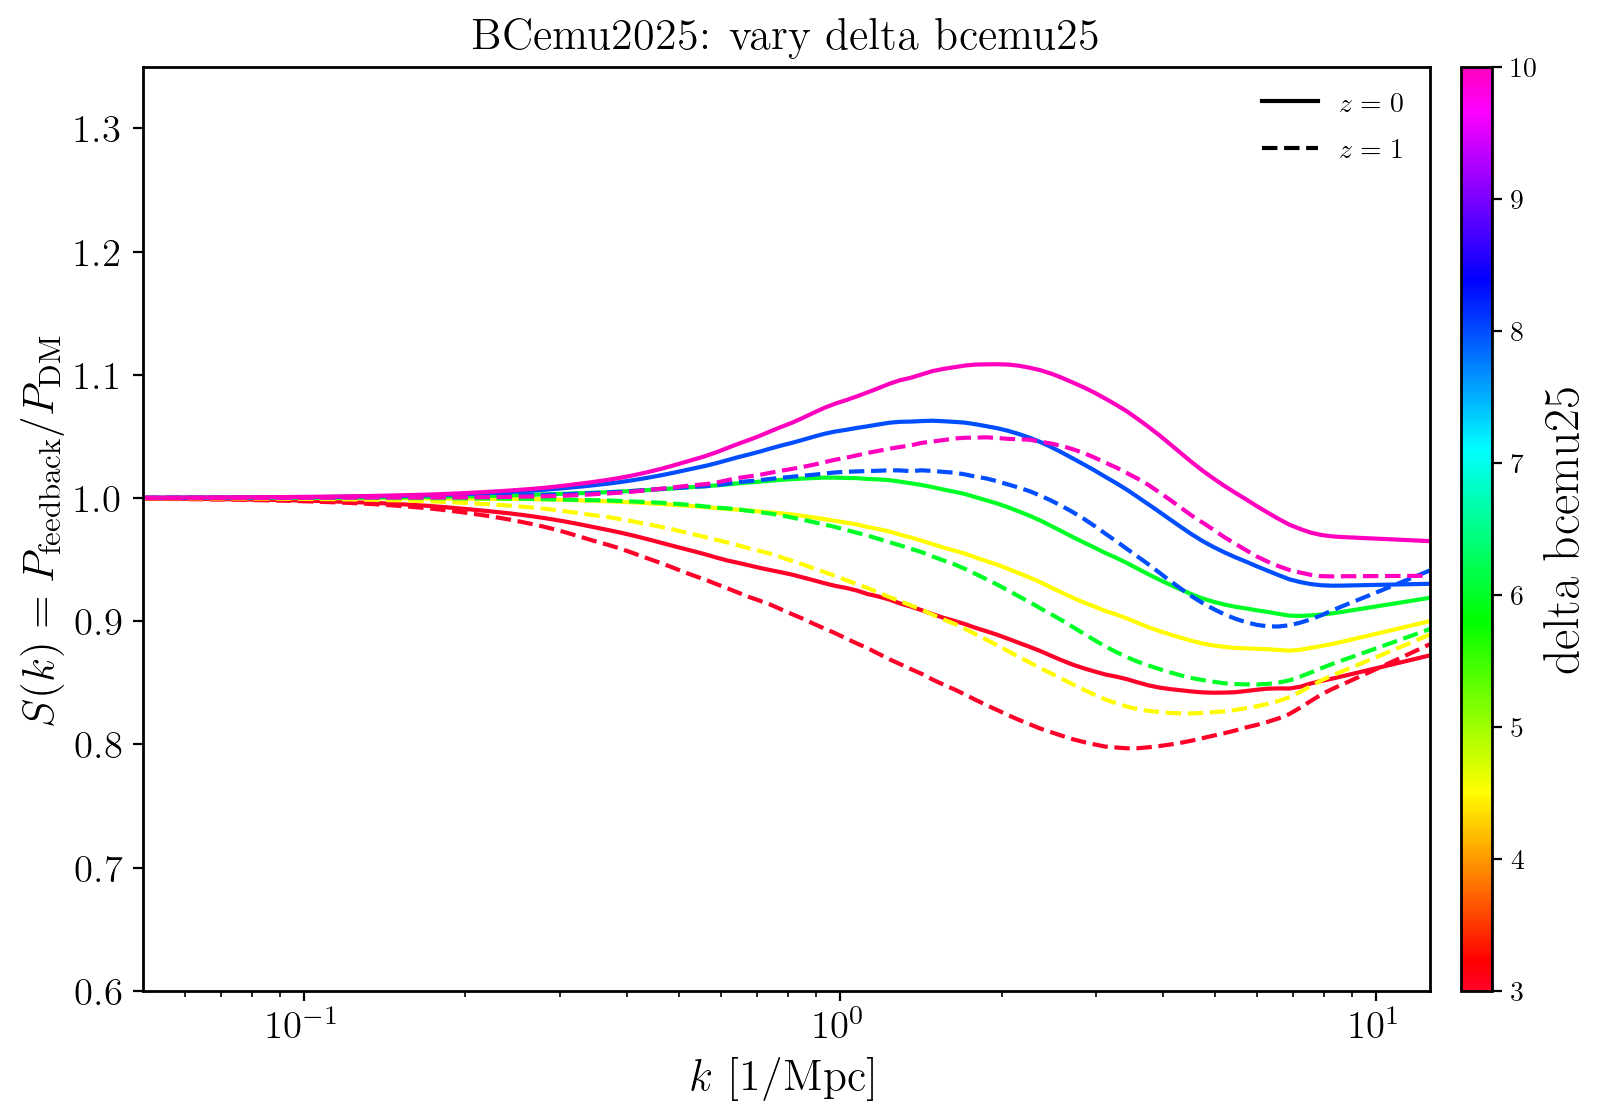

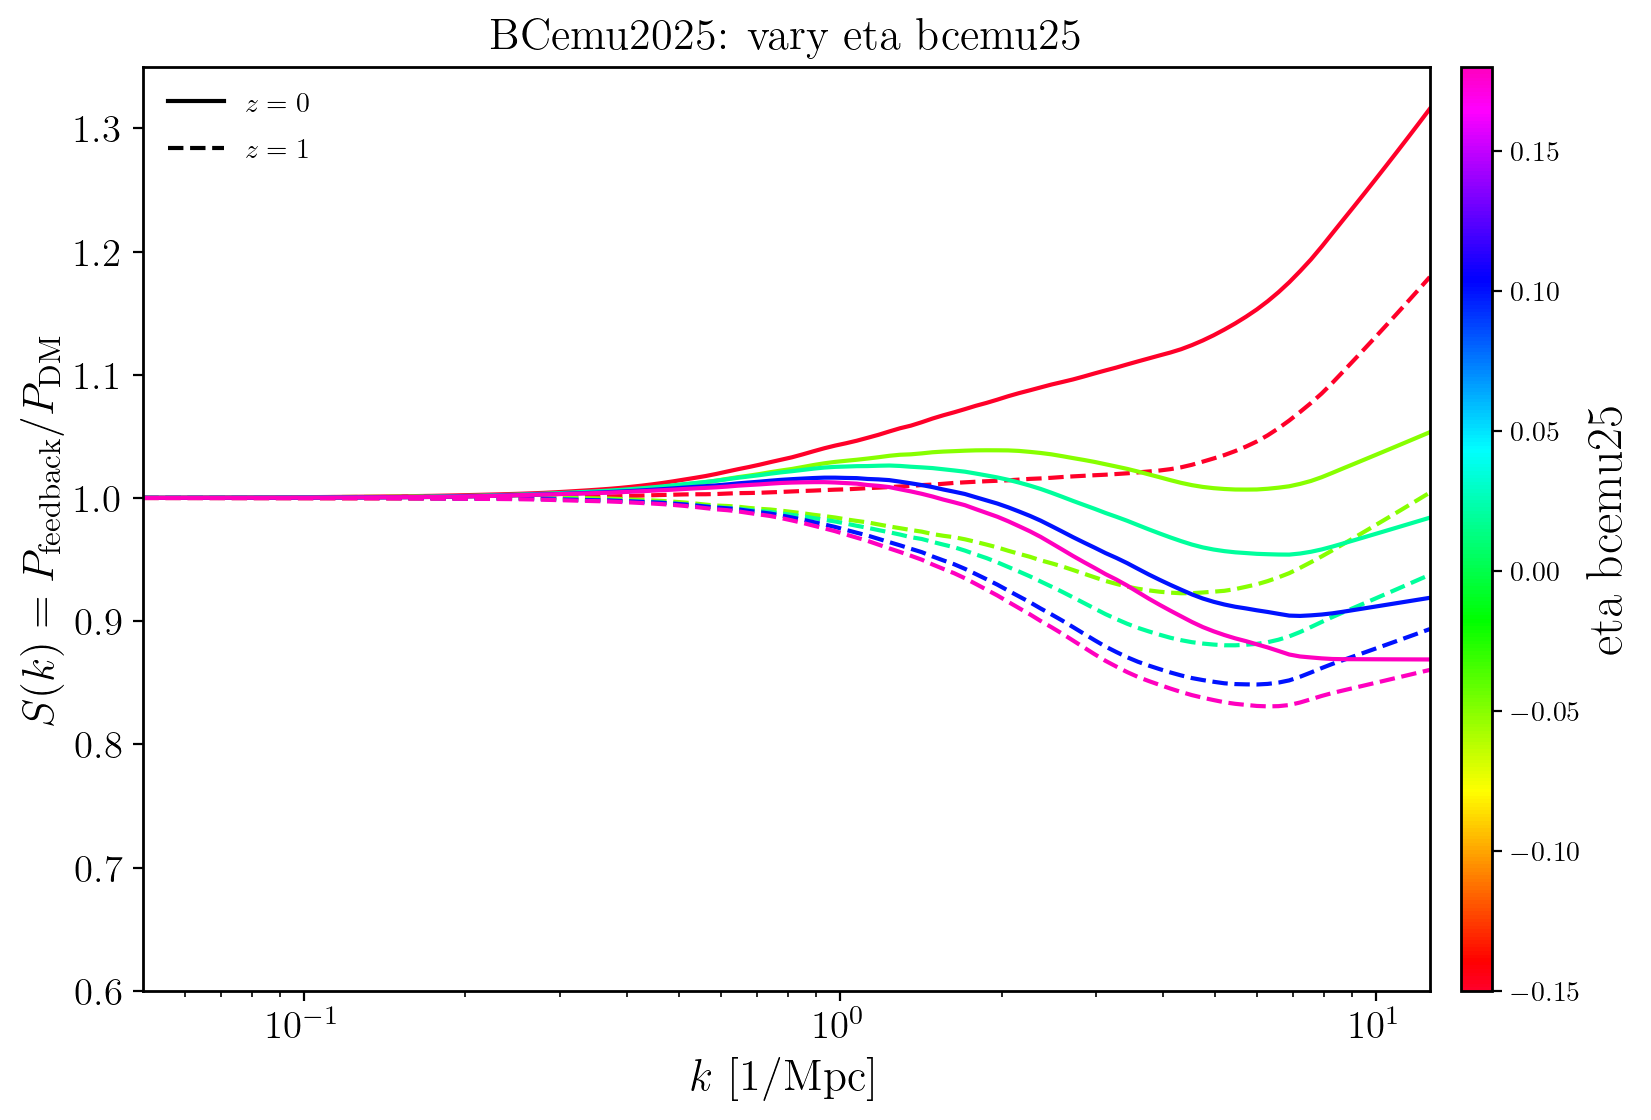

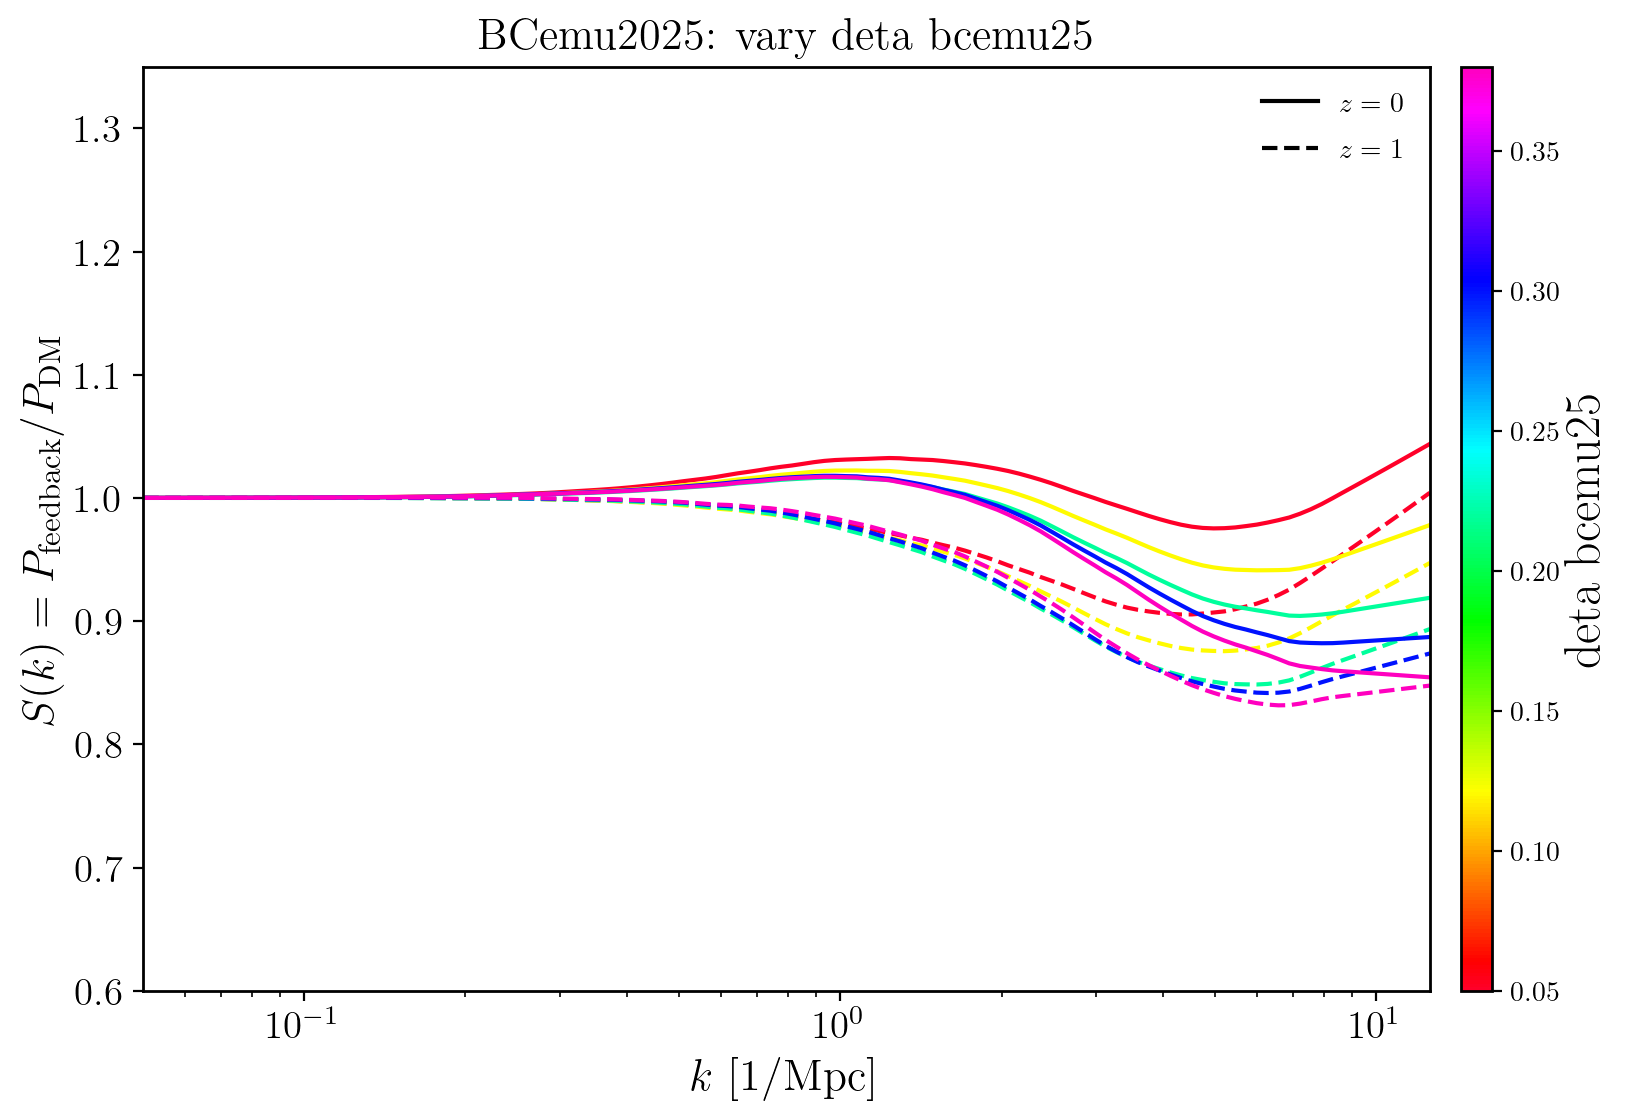

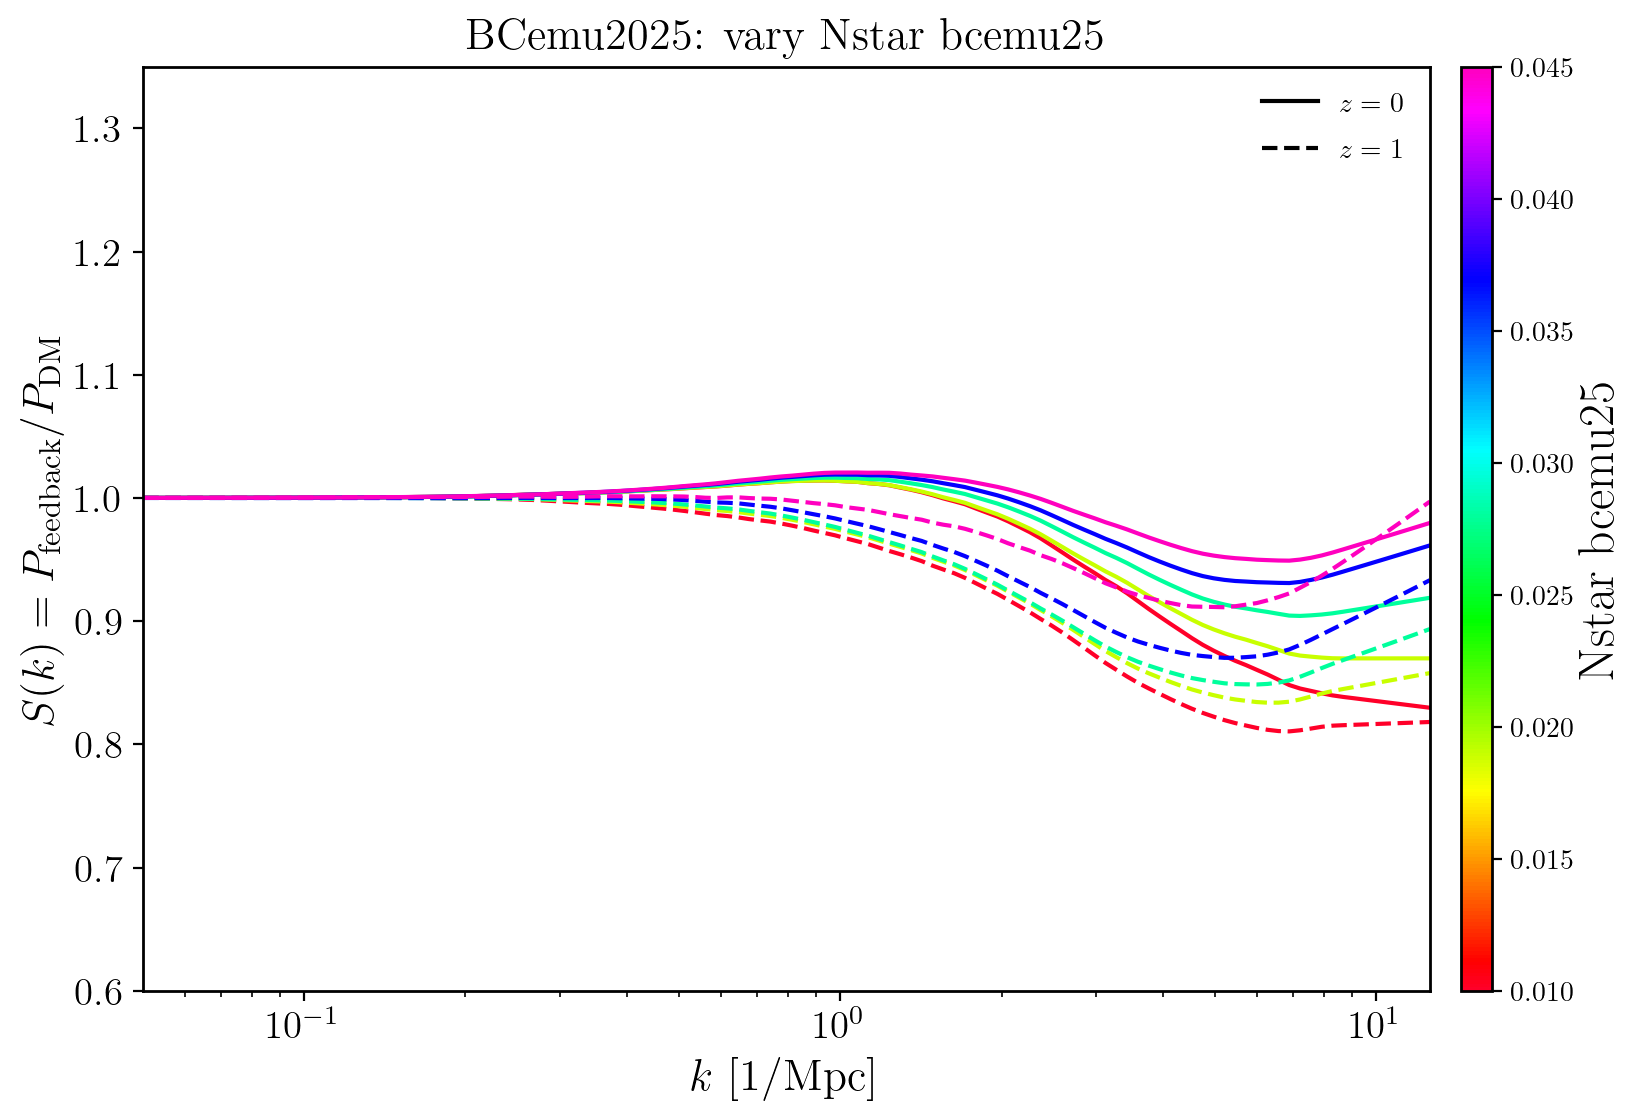

In [23]:
plot_sweeps("BCemu2025")